# Analyzing DDM Parameters for TOJ Task
**List of contents:**\
1- General\
2- Prior response \
3- Prior stimulus\
4- Plot statistical results

In [1]:
library(broom)
library(mosaic)
library(glue)
library(patchwork)
library(scam)
library(tidyverse)
library(readxl)
library(rstatix)
library(ggpubr)
library(writexl)
library(dplyr)
library(ggbeeswarm)

Warning message:
"package 'mosaic' was built under R version 4.4.2"
Registered S3 method overwritten by 'mosaic':
  method                           from   
  fortify.SpatialPolygonsDataFrame ggplot2


The 'mosaic' package masks several functions from core packages in order to add 
additional features.  The original behavior of these functions should not be affected by this.


Attaching package: 'mosaic'


The following objects are masked from 'package:dplyr':

    count, do, tally


The following object is masked from 'package:Matrix':

    mean


The following object is masked from 'package:ggplot2':

    stat


The following objects are masked from 'package:stats':

    binom.test, cor, cor.test, cov, fivenum, IQR, median, prop.test,
    quantile, sd, t.test, var


The following objects are masked from 'package:base':

    max, mean, min, prod, range, sample, sum


Warning message:
"package 'patchwork' was built under R version 4.4.3"
Warning message:
"package 'scam' was built under

###############################################################\
###############################################################
# 1- General
**List of contents:**\
1-1 Testing change in relative starting point across SOA \
1-2 Testing change in signal to noise ratio across SOA\
1-3 Calculating sensory and decisional bias

In [2]:
# =========================================================
# Load DDM parameter estimates (prior response model)
# The Excel file contains trial-wise parameter estimates
# extracted from PyDDM for the TOJ task.
# =========================================================

df_resp <- read_xlsx("files/TOJ_general_DDM_parameters.xlsx")

# Rename first columns for clarity
colnames(df_resp)[1] <- "ID"
colnames(df_resp)[2] <- "SOA"

# ---------------------------------------------------------
# Compute Signal-to-Noise Ratio (SNR)
# SNR = drift rate (v) / noise (σ)
# This quantity reflects the quality of sensory evidence
# accumulation and is used as an index of sensory bias.
# ---------------------------------------------------------

df_resp$snr <- df_resp$drift / df_resp$noise

df_resp <- df_resp %>% arrange(ID, SOA)

###############################################################
## 1-1 Testing change in relative starting point across SOA

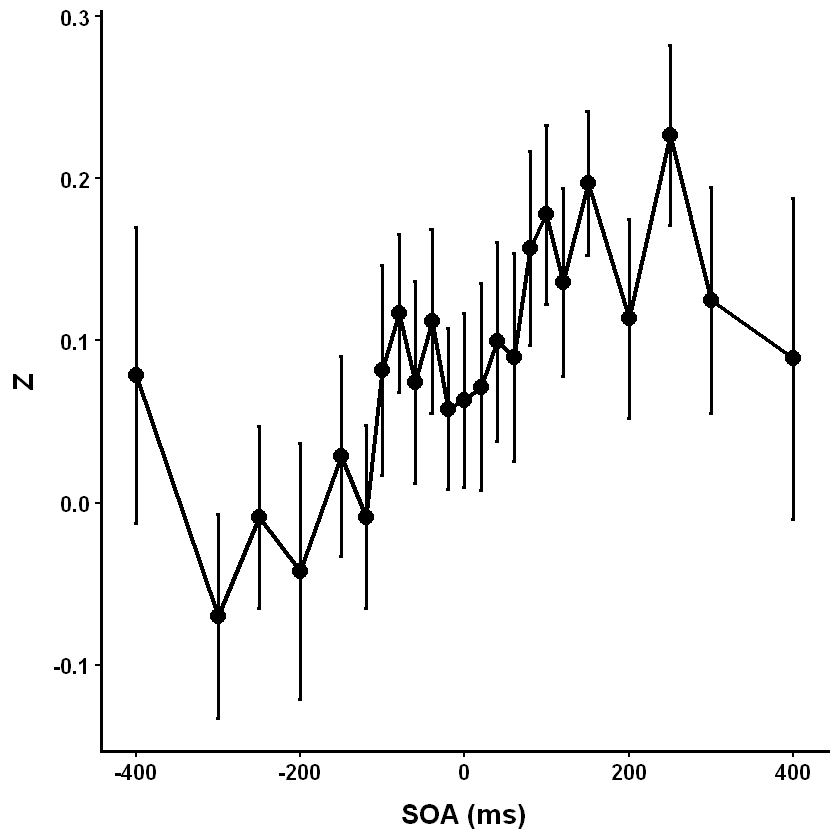

In [3]:
# =========================================================
# Visualize how relative starting point varies as a function of SOA for SJ task.
# =========================================================

# 1. Calculate summary statistics (Mean and SEM)
summary_resp <- df_resp %>%
  group_by(SOA) %>%
  summarise(
    mean_z = mean(Z, na.rm = TRUE),
    se_z = sd(Z, na.rm = TRUE) / sqrt(n()),
    .groups = "drop"
  )

# 2. Create the plot with enhanced visibility for publication
p_resp <- ggplot(summary_resp,
                 aes(x = SOA, y = mean_z)) +
  # Increase line thickness for better visibility
  geom_line(linewidth = 1.2) +
  # Increase point size for better visibility
  geom_point(size = 4) +
  # Make error bars thicker and more visible
  geom_errorbar(aes(ymin = mean_z - se_z,
                    ymax = mean_z + se_z),
                width = 5, linewidth = 1) +
  # Define axis labels and legend title (No figure title)
  labs(
    x = "SOA (ms)",
    y = "Z"
  ) +
  # Use the same professional color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  # Use a clean and consistent theme across all figures
  theme_classic(base_size = 14) +
  theme(
    # Bold and enlarge axis titles
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    # Bold and enlarge axis tick labels
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    # Bold and enlarge legend title and legend text
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    # Keep legend placement consistent across all figures
    legend.position = "top",
    # Make axis lines clearly visible
    axis.line = element_line(linewidth = 1)
  )

# 3. Display the plot
print(p_resp)

In [4]:
friedman.test(
  Z ~ SOA | ID,
  data = df_resp
)


	Friedman rank sum test

data:  Z and SOA and ID
Friedman chi-squared = 30.454, df = 22, p-value = 0.1078


###############################################################
## 1-2 Testing change in signal to noise ratio across SOA

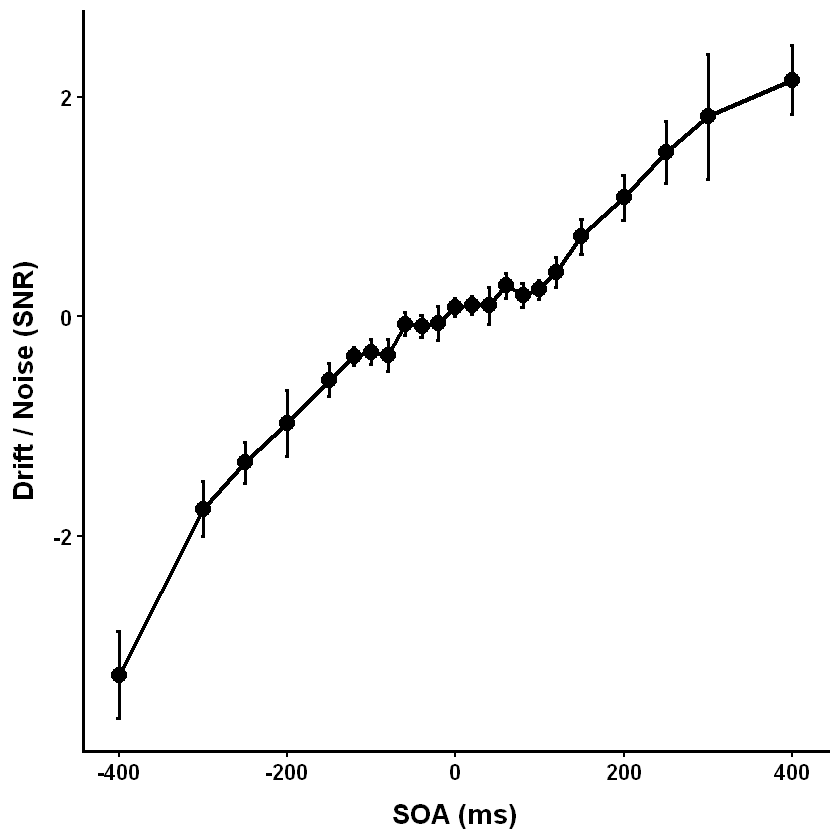

In [5]:
# =========================================================
# Visualize how sensory evidence varies as a function of SOA
# and prior response condition for TOJ task.
# =========================================================

# 1. Calculate summary statistics (Mean and SEM)
summary_resp <- df_resp %>%
  group_by(SOA) %>%
  summarise(
    mean_snr = mean(snr, na.rm = TRUE),
    se_snr = sd(snr, na.rm = TRUE) / sqrt(n()),
    .groups = "drop"
  )

# 2. Create the plot with enhanced visibility for publication
p_resp <- ggplot(summary_resp,
                 aes(x = SOA, y = mean_snr)) +
  # Increase line thickness for better visibility
  geom_line(linewidth = 1.2) +
  # Increase point size for better visibility
  geom_point(size = 4) +
  # Make error bars thicker and more visible
  geom_errorbar(aes(ymin = mean_snr - se_snr,
                    ymax = mean_snr + se_snr),
                width = 5, linewidth = 1) +
  # Define axis labels and legend title (No figure title)
  labs(
    x = "SOA (ms)",
    y = "Drift / Noise (SNR)"
  ) +
  # Use the same professional color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  # Use a clean and consistent theme across all figures
  theme_classic(base_size = 14) +
  theme(
    # Bold and enlarge axis titles
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    # Bold and enlarge axis tick labels
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    # Bold and enlarge legend title and legend text
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    # Keep legend placement consistent across all figures
    legend.position = "top",
    # Make axis lines clearly visible
    axis.line = element_line(linewidth = 1)
  )

# 3. Display the plot
print(p_resp)

In [6]:
friedman.test(
  snr ~ SOA | ID,
  data = df_resp
)


	Friedman rank sum test

data:  snr and SOA and ID
Friedman chi-squared = 299.57, df = 22, p-value < 2.2e-16


###############################################################
## 1-3 Calculating sensory and decisional bias

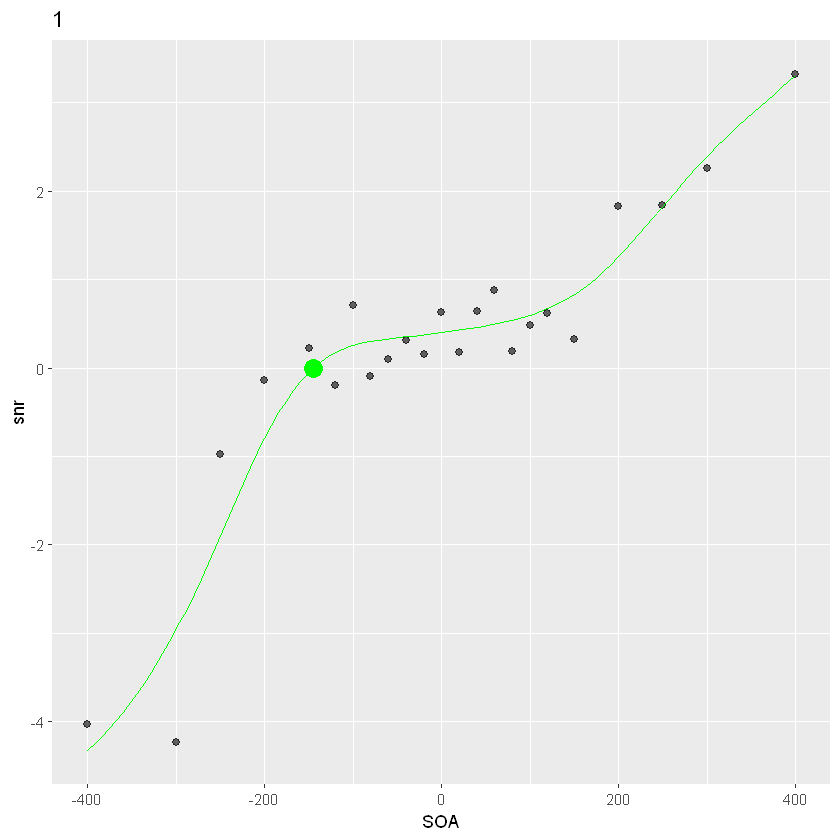

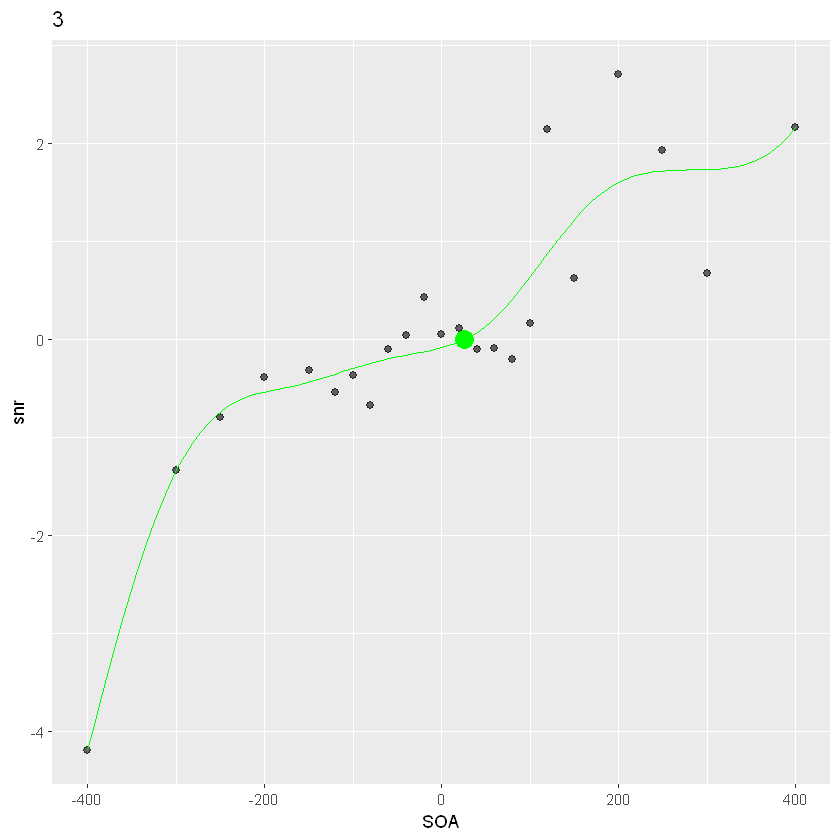

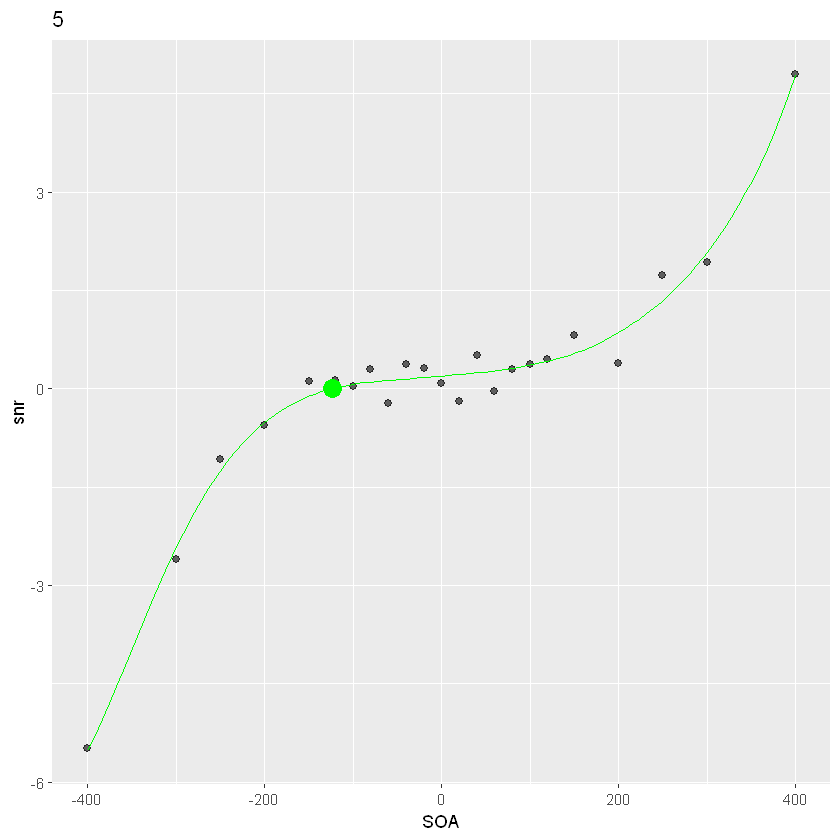

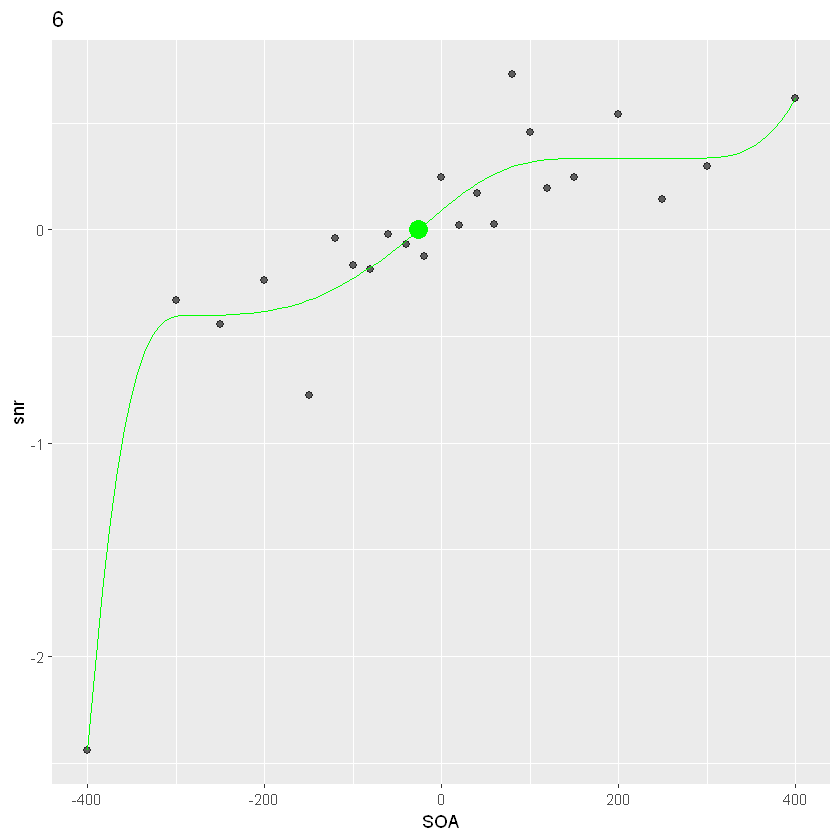

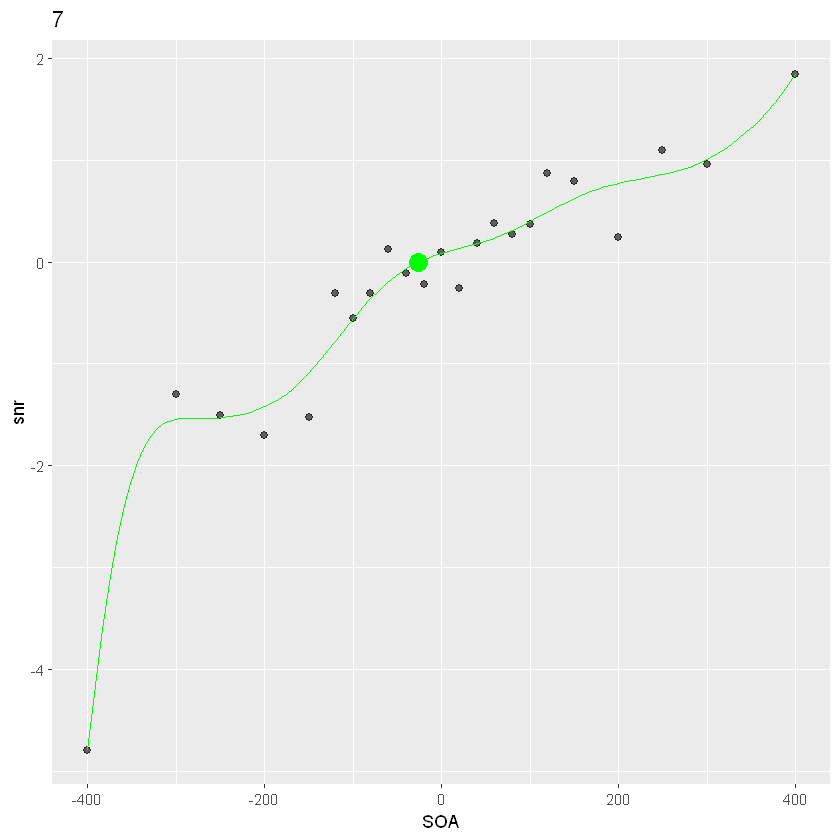

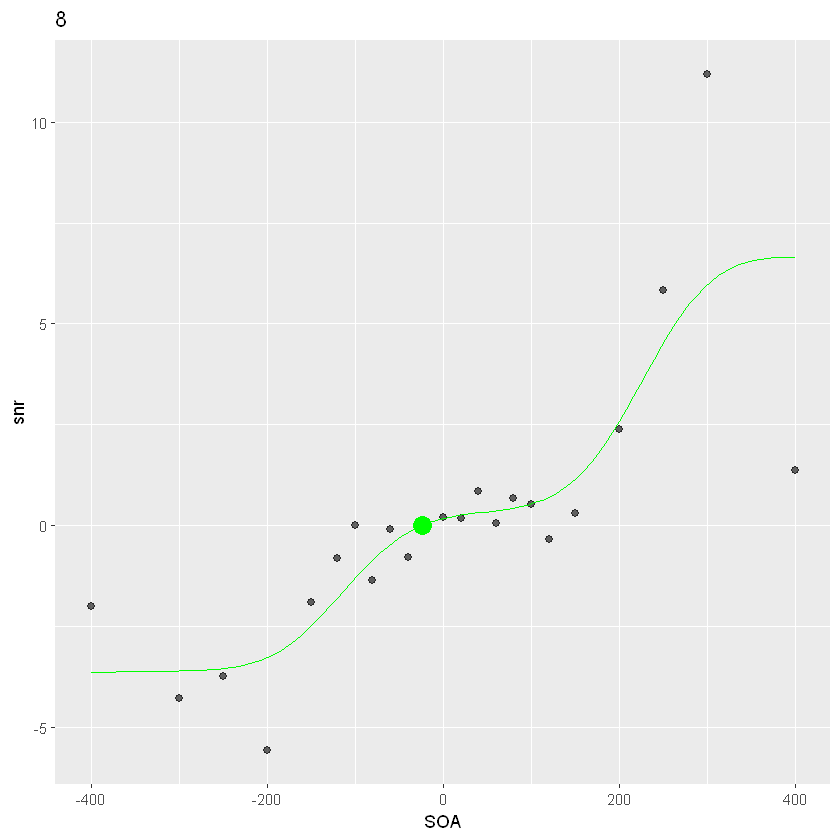

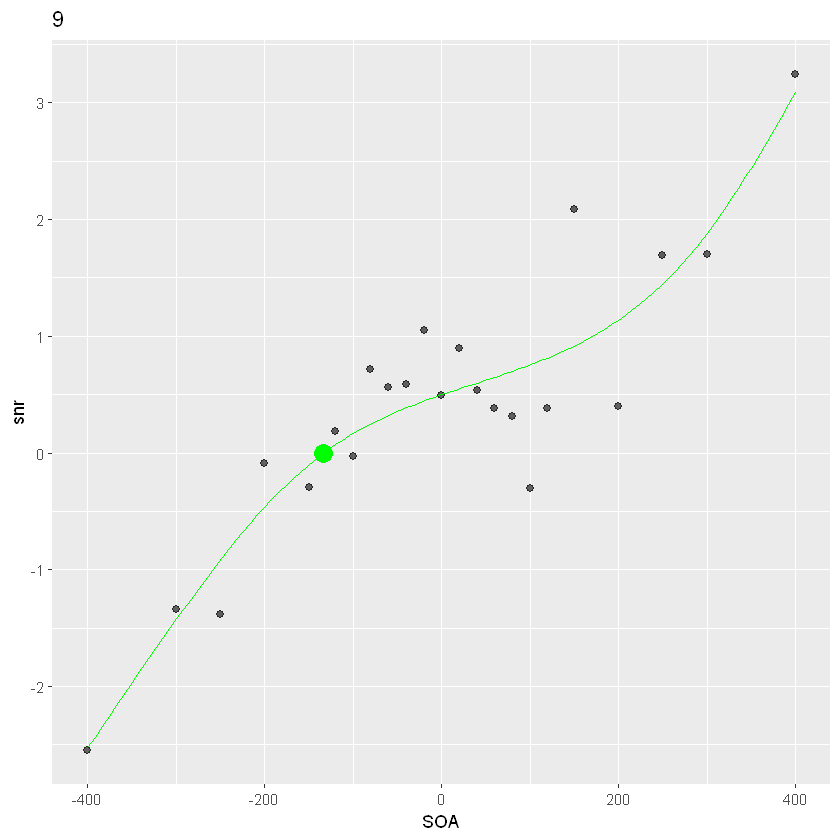

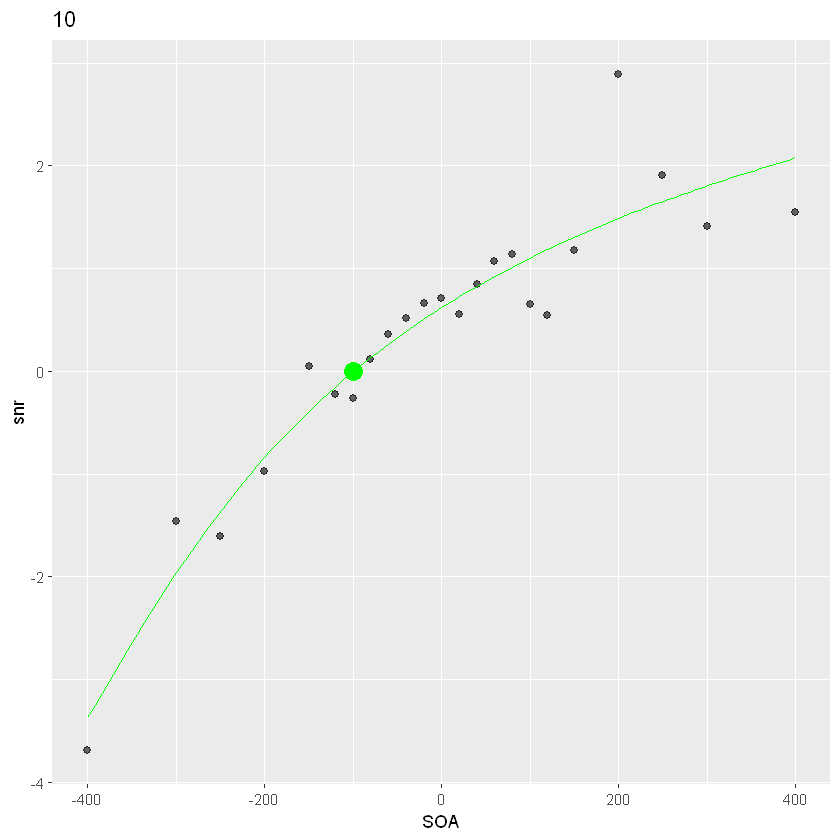

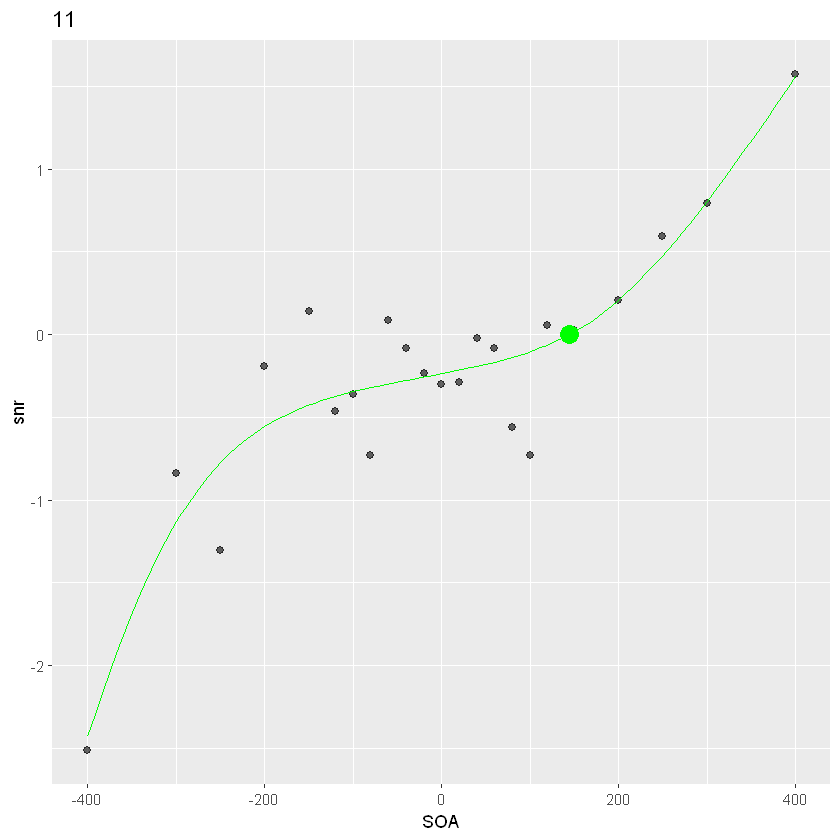

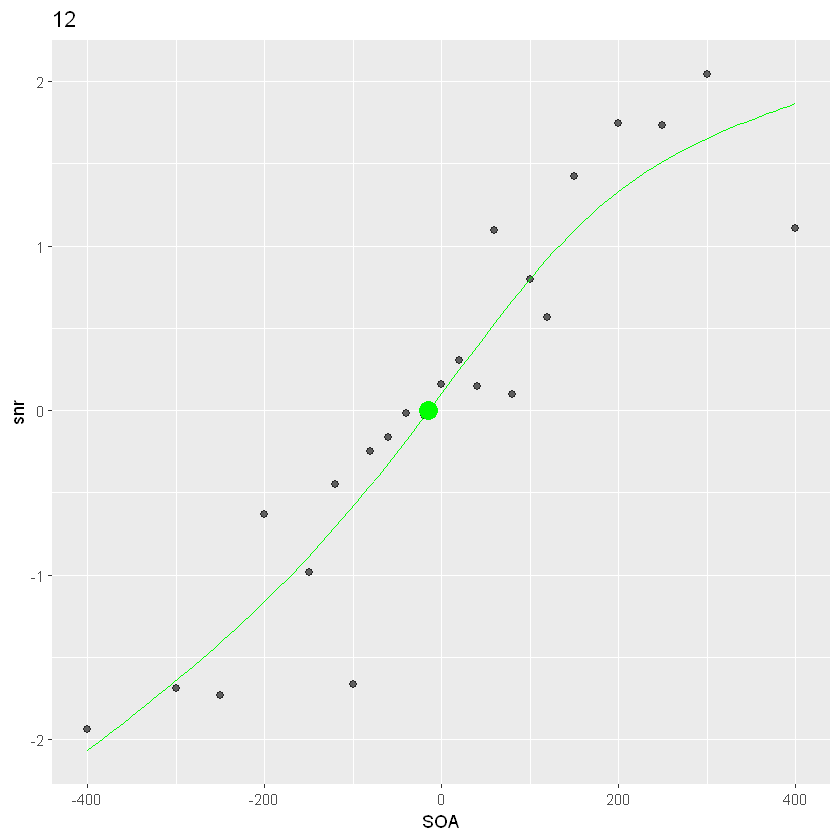

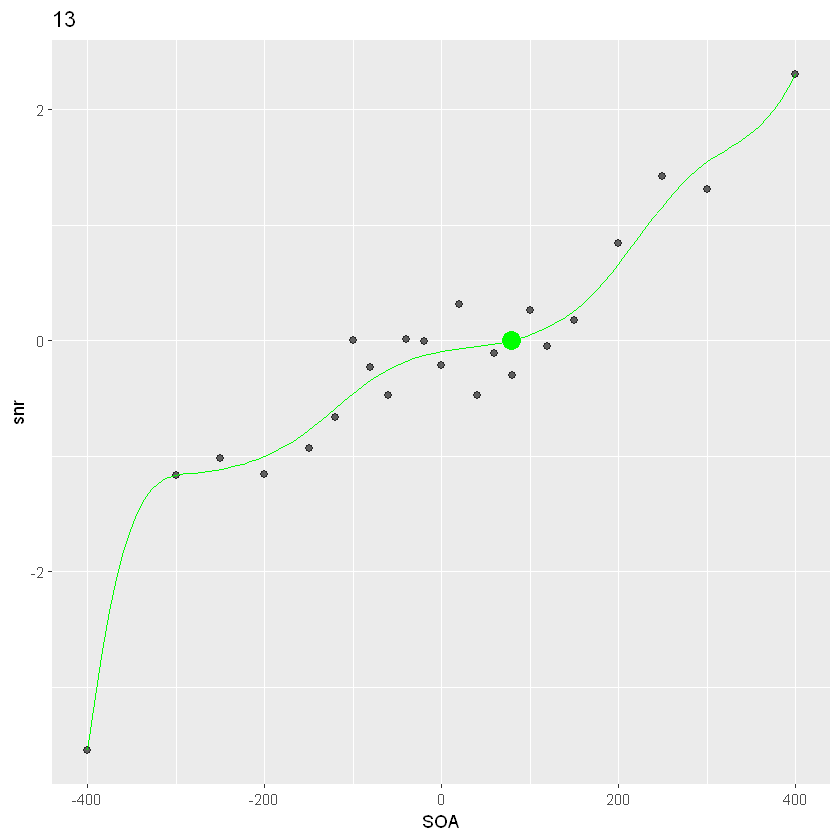

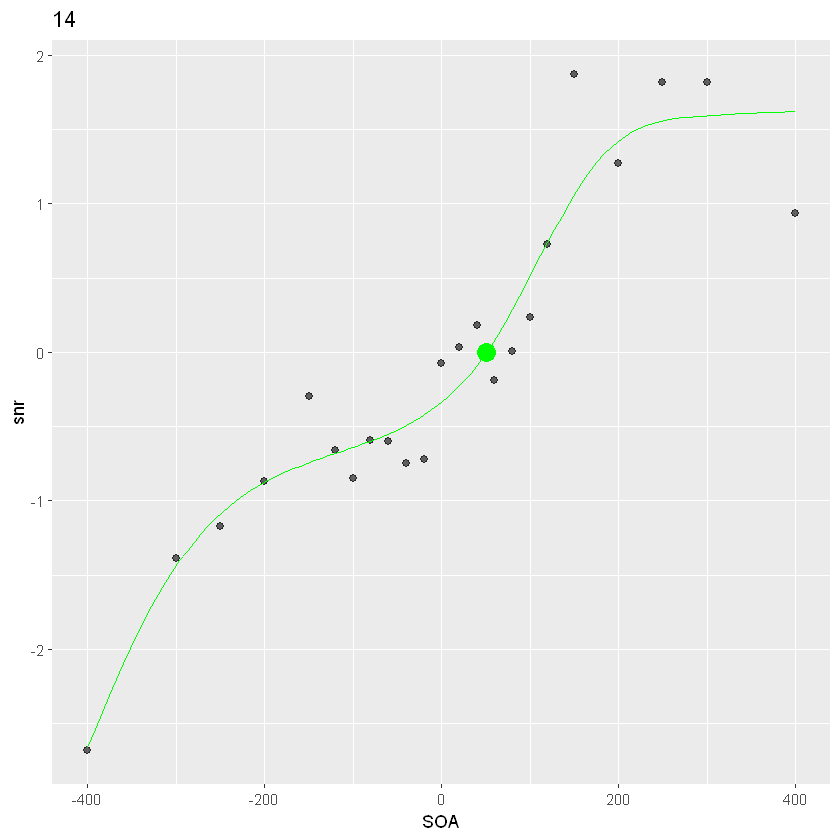

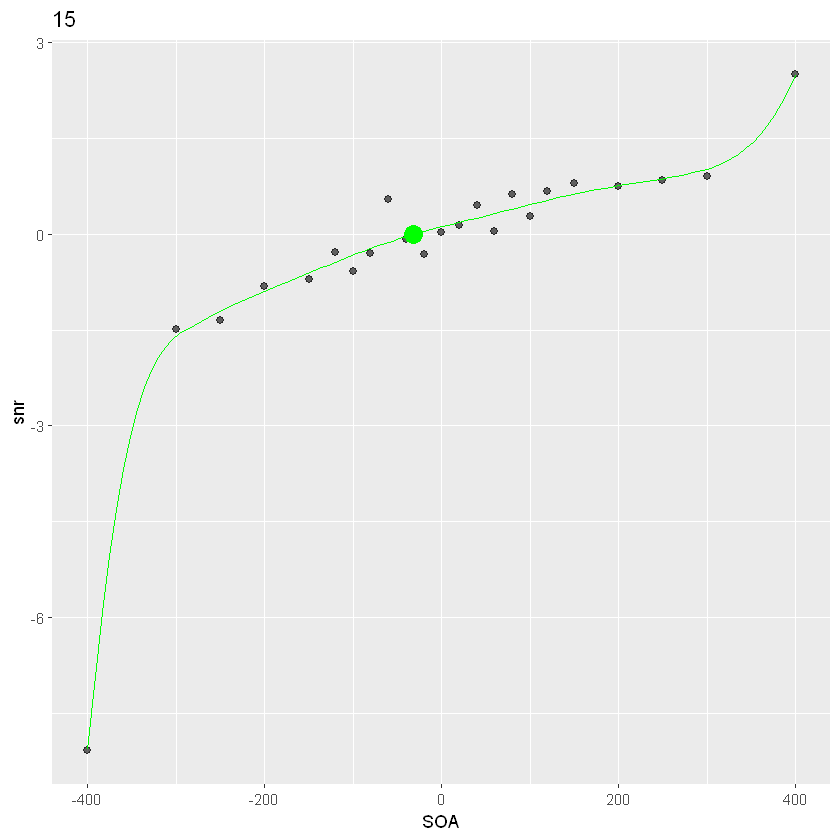

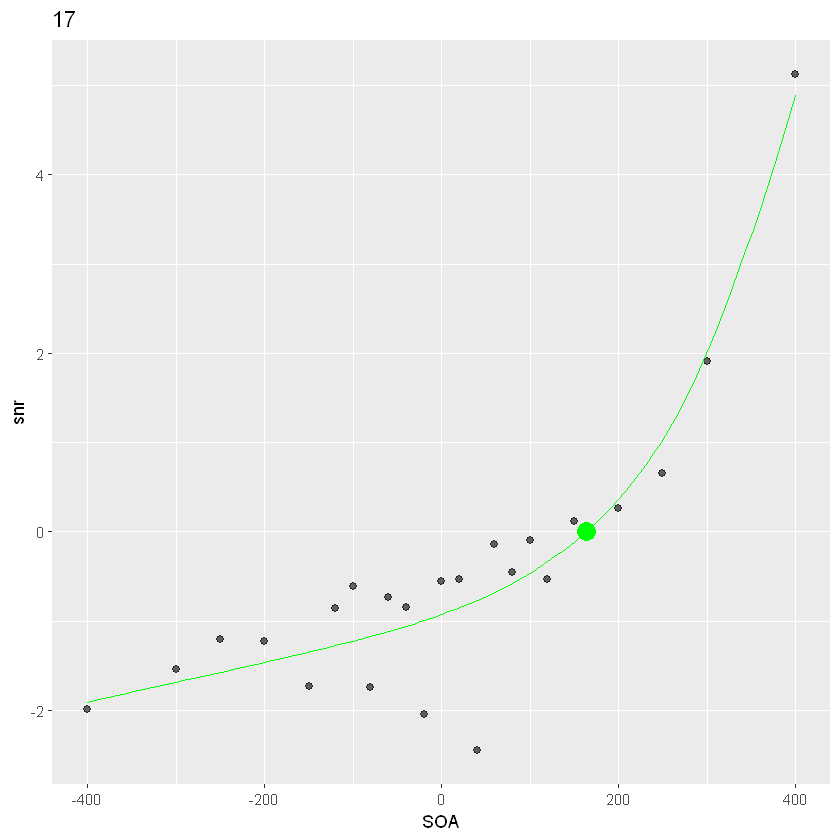

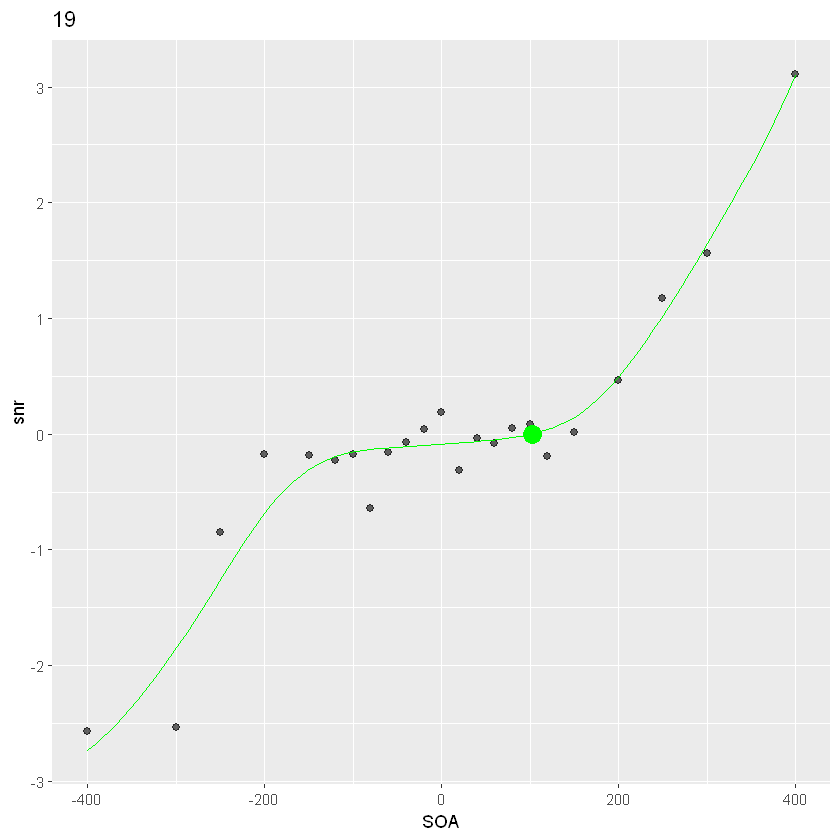

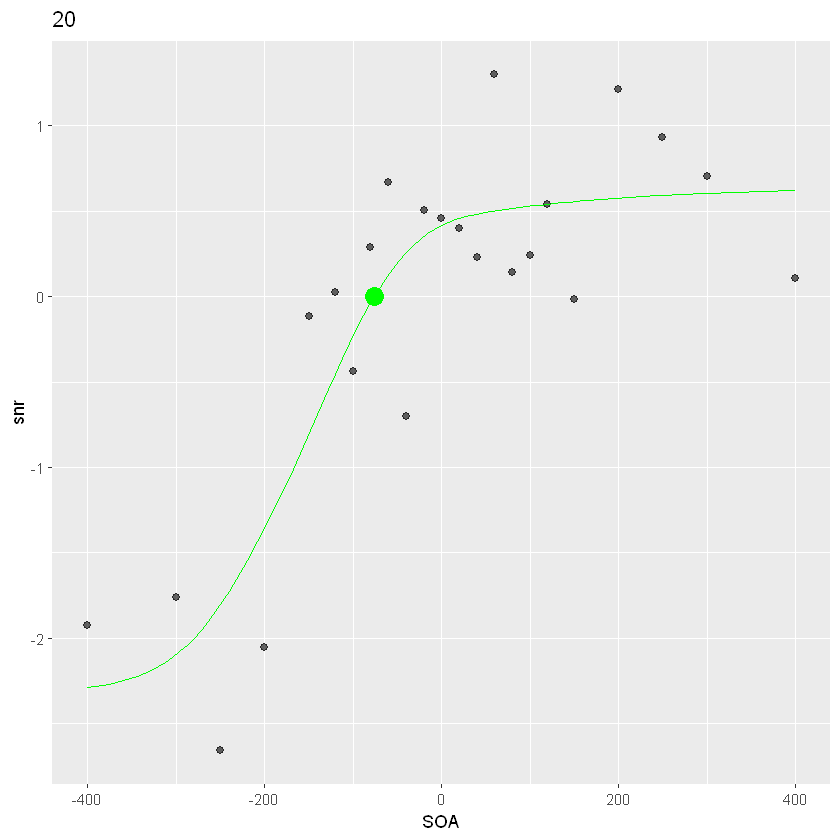

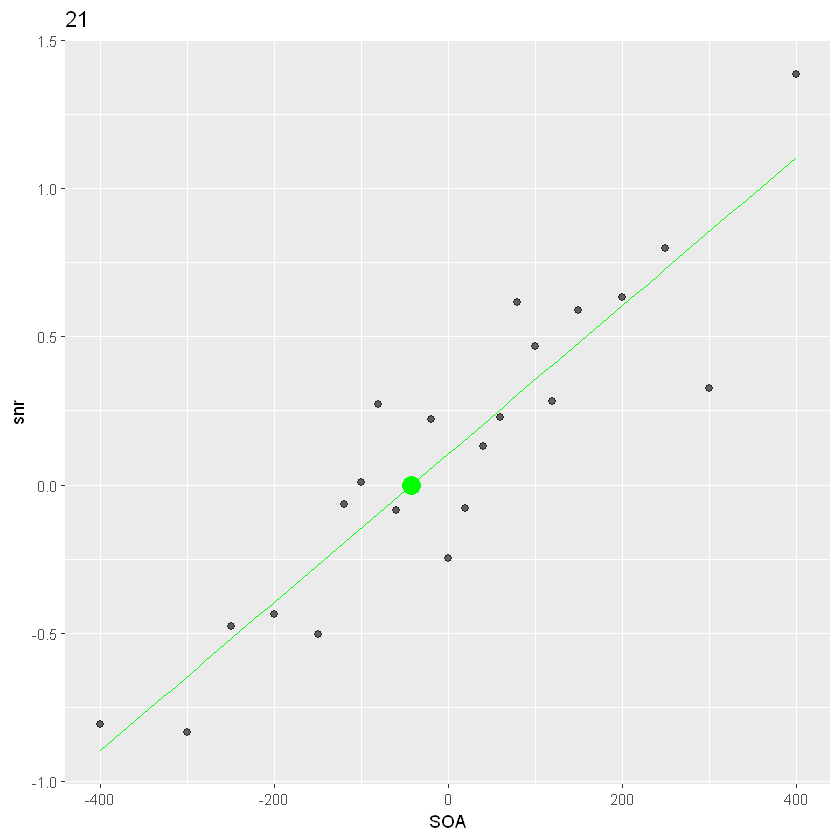

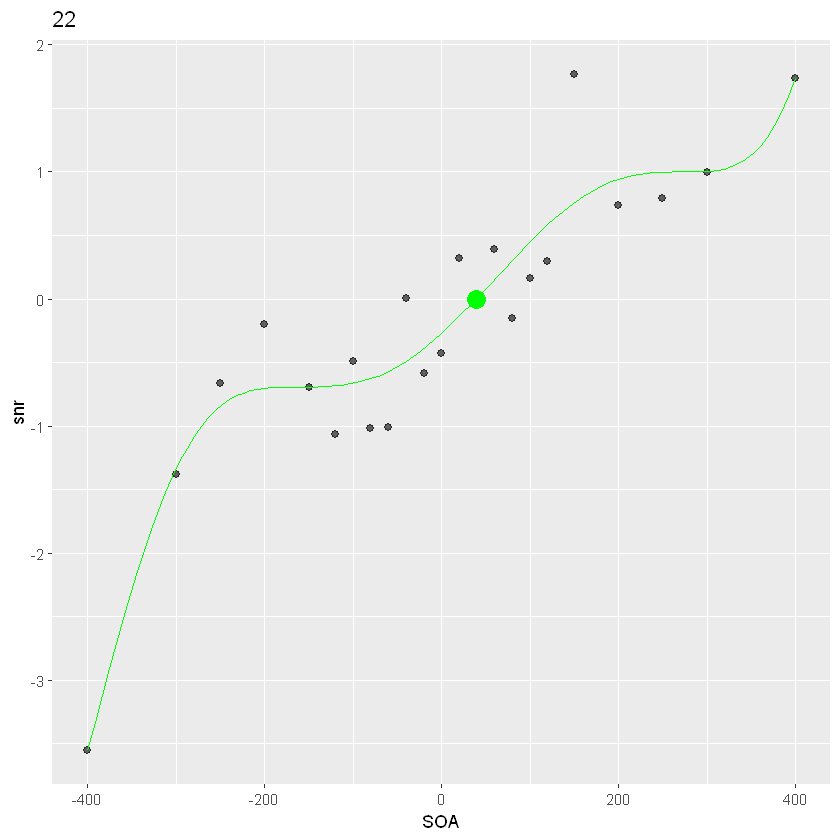

In [3]:
#==============================================================================#
# ESTIMATING LATENT SENSORY BIAS VIA SHAPE-CONSTRAINED ADDITIVE MODELS (SCAM)
# PURPOSE: Fit increasing-constrained splines 
#          to SNR profiles per participant and condition, identifying functions' 
#          roots (zeros) to quantify sensory bias thresholds.

#The zero-crossing point of this function corresponds to
# the SOA at which accumulated sensory evidence is balanced
# between the two response alternatives.
# This value serves as an estimate of sensory bias (PSE-like).
#==============================================================================#

sigmoid_results <- data.frame()

for (participant in unique(df_resp$ID)) {
        df_resp_subset <- df_resp %>% filter(ID == participant)

        model <- scam(snr ~ s(SOA, bs = "mpi"), data = df_resp_subset)
        ff <- function(SOA) {
              predict(model, data.frame(SOA = SOA))
            }
        roots <- findZeros(ff(x)~x)
        
        print(ggplot(df_resp_subset, aes(x = SOA, y = snr)) +
              ggtitle(glue('{participant}')) +
          geom_point(size = 2, alpha = 0.6) + 
          geom_function(fun=ff, color='green') +
          geom_point(data = data.frame(x=roots, y=0), aes(x=x,y=y),size = 5, color='green')
             )

        sigmoid_results <- rbind(sigmoid_results, data.frame(
            ID = participant,
            root = mean(roots$x)))
}

In [17]:
write_xlsx(sigmoid_results,"files/TOJ_sensory_bias_general.xlsx")

In [9]:
df_summary <- df_resp %>%
  group_by(ID) %>%
  summarise(mean_Z = median(Z, na.rm = TRUE),
            .groups = "drop")

In [10]:
write_xlsx (df_summary,"files/TOJ_decision_bias_general.xlsx")

###############################################################\
###############################################################
# 2- Prior response
**List of contents:**\
2-1 Plotting SNR curves\
2-2 Calculating sensory and decisional bias\
2-3 Testing change in SNR root\
2-4 Testing change in relative starting point

In [24]:
df_resp <- read_xlsx("files/TOJ_prior_response_DDM_parameters_clean.xlsx")

# Rename first columns for clarity
colnames(df_resp)[1] <- "ID"
colnames(df_resp)[2] <- "prior_response"

# Recode prior response labels into descriptive factors
df_resp$prior_response <- recode(df_resp$prior_response,
                                 "v" = "visual response",
                                 "a" = "auditory response")
# ---------------------------------------------------------
# Compute Signal-to-Noise Ratio (SNR)
# SNR = drift rate (v) / noise (σ)
# This quantity reflects the quality of sensory evidence
# accumulation and is used as an index of sensory bias.
# ---------------------------------------------------------
df_resp$snr <- df_resp$drift / df_resp$noise

In [25]:
head(df_resp)

ID,prior_response,SOA,drift,noise,bound,Z,t0,snr
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,auditory response,-400,-1.1744794,0.1836824,1,0.5900859,0.0020601840,-6.3940769
1,auditory response,-300,-0.8558164,0.1957634,1,0.1341136,0.0005898535,-4.3716877
1,auditory response,-250,-0.3344227,0.8141396,1,-0.3823029,0.8329775684,-0.4107682
1,auditory response,-200,-0.3223520,0.8055376,1,-0.4590057,0.7923829220,-0.4001700
1,auditory response,-150,-0.3601695,0.9267402,1,0.1995819,1.0442925617,-0.3886413
1,auditory response,-120,-0.3082201,0.5178615,1,-0.7434259,0.9052824332,-0.5951786


###############################################################
## 2-1 Plotting SNR curves

In [26]:
head(df_resp)

ID,prior_response,SOA,drift,noise,bound,Z,t0,snr
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,auditory response,-400,-1.1744794,0.1836824,1,0.5900859,0.0020601840,-6.3940769
1,auditory response,-300,-0.8558164,0.1957634,1,0.1341136,0.0005898535,-4.3716877
1,auditory response,-250,-0.3344227,0.8141396,1,-0.3823029,0.8329775684,-0.4107682
1,auditory response,-200,-0.3223520,0.8055376,1,-0.4590057,0.7923829220,-0.4001700
1,auditory response,-150,-0.3601695,0.9267402,1,0.1995819,1.0442925617,-0.3886413
1,auditory response,-120,-0.3082201,0.5178615,1,-0.7434259,0.9052824332,-0.5951786


In [22]:
summary_resp <- df_resp %>%
  group_by(SOA, prior_response) %>%
  summarise(
    mean_snr = mean(snr, na.rm = TRUE),
    se_snr = sd(snr, na.rm = TRUE) / sqrt(n()),
    .groups = "drop"
  )

In [23]:
df_predicted = data.frame()
for (participant in unique(df_resp$ID)) {
    for (condition in unique(df_resp$prior_response)) {
        df_resp_subset <- df_resp %>% filter(ID == participant, prior_response == condition)

        model <- scam(snr ~ s(SOA, bs = "mpi"), data = df_resp_subset)
        ff <- function(SOA) {
              predict(model, data.frame(SOA = SOA))
            }
        df <- data.frame(ID=participant, prior_response=condition, SOA = -400:400, snr=ff(-400:400))
        df_predicted <- rbind(df_predicted, df)
}}

In [70]:
df_predicted_summary <- df_predicted %>%
  group_by(prior_response, SOA) %>%
  summarise(
    mean_snr = mean(snr),
    se = sd(snr) / sqrt(n()),
    .groups = "drop"
  )

png 
  2

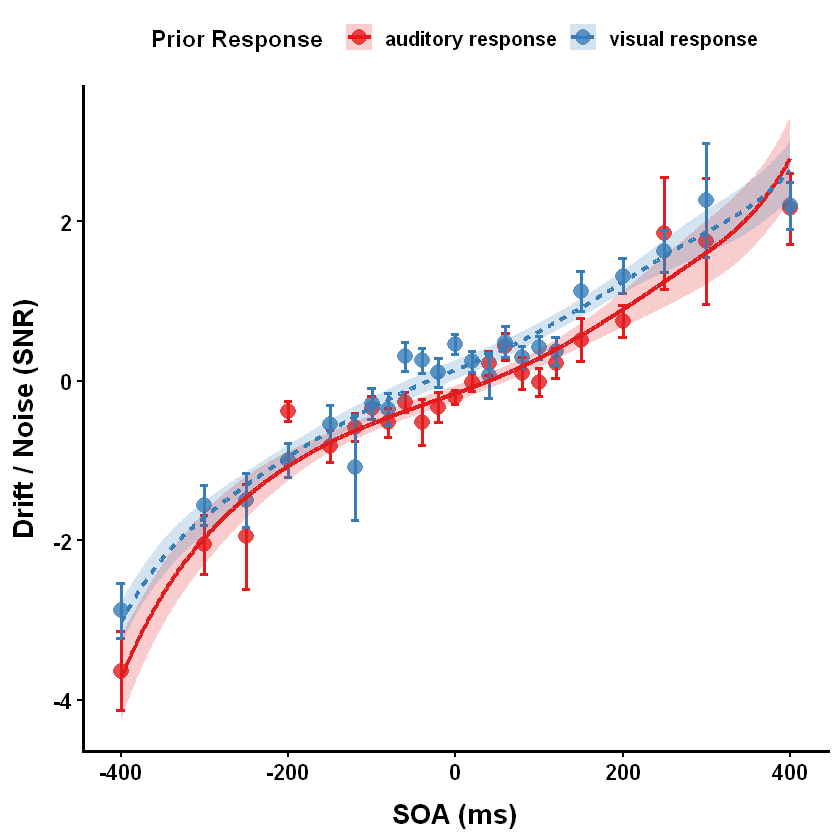

In [71]:
# save as PDF
pdf(file="figures/TOJ_prior_response_snr.pdf", width = 10, height = 8)  

# Create the plot with publication-style formatting
p_toj_prior_resp <- ggplot() +
  # Plot observed data points
  geom_point(
    data = summary_resp,
    aes(x = SOA, y = mean_snr, color = prior_response),
    alpha = 0.8,
    size = 4,
    shape = 16
  ) +

  # Add error bars for observed data
  geom_errorbar(
    data = summary_resp,
    aes(
      x = SOA,
      ymin = mean_snr - se_snr,
      ymax = mean_snr + se_snr,
      color = prior_response
    ),
    width = 10,
    linewidth = 1
  ) +

  # Add shaded ribbon around fitted values
  geom_ribbon(
    data = df_predicted_summary,
    aes(
      x = SOA,
      ymin = mean_snr - se,
      ymax = mean_snr + se,
      fill = prior_response,
      group = prior_response
    ),
    alpha = 0.22,
    color = NA
  ) +

  # Plot fitted curves
  geom_line(
    data = df_predicted_summary,
    aes(
      x = SOA,
      y = mean_snr,
      color = prior_response,
      linetype = prior_response,
      group = prior_response
    ),
    linewidth = 1.2
  ) +

  # Define labels
  labs(
    x = "SOA (ms)",
    y = "Drift / Noise (SNR)",
    color = "Prior Response",
    linetype = "Prior Response",
    fill = "Prior Response"
  ) +

  # Use a clean theme consistent with previous figures
  theme_classic(base_size = 14) +
  theme(
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    legend.position = "top",
    axis.line = element_line(linewidth = 1)
  ) +

  # Use the same color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  scale_fill_brewer(palette = "Set1")
p_toj_prior_resp
dev.off()
# 3. Display the plot
print(p_toj_prior_resp)

###############################################################
## 2-2 Calculating sensory and decisional bias

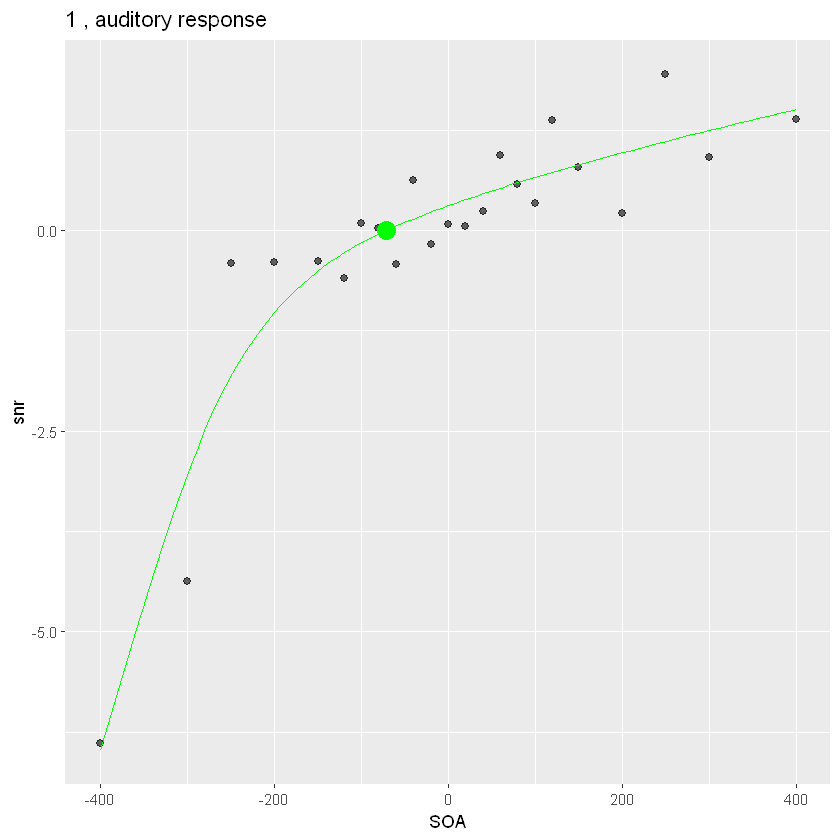

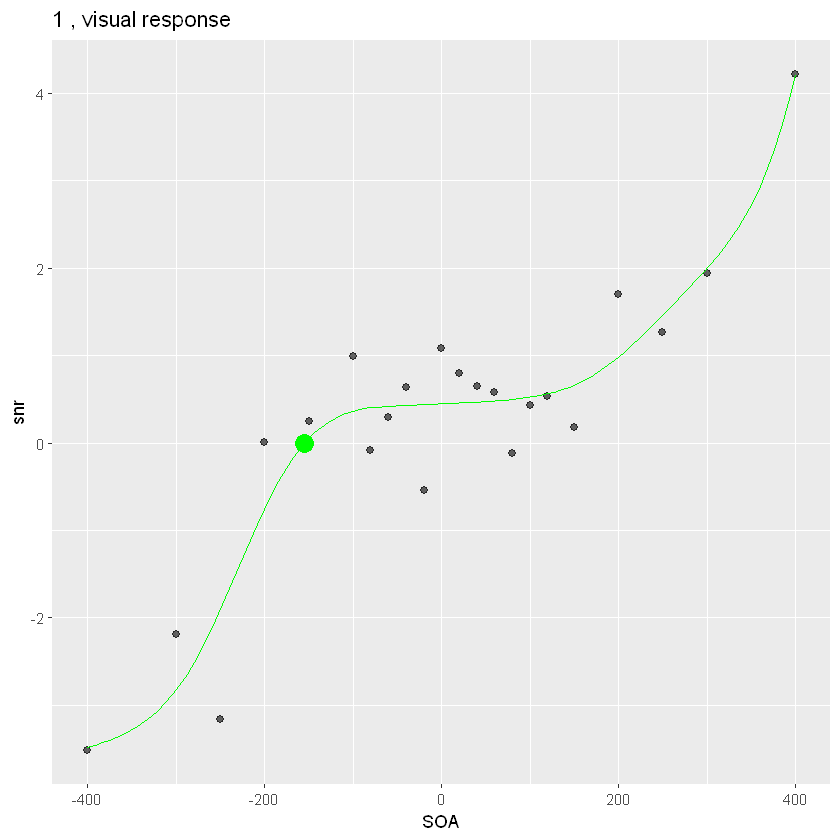

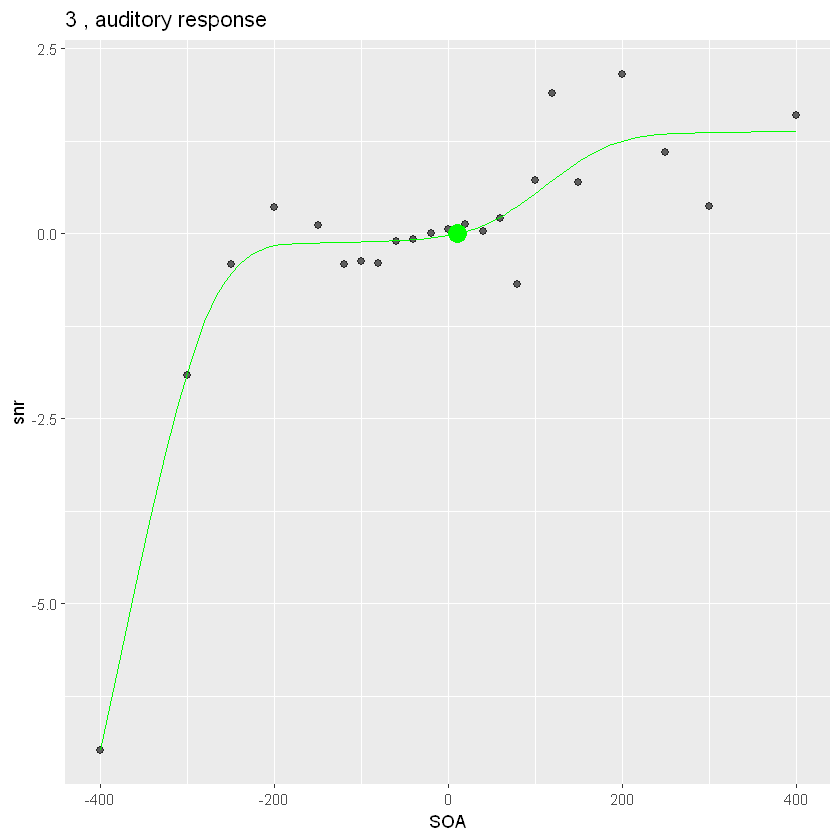

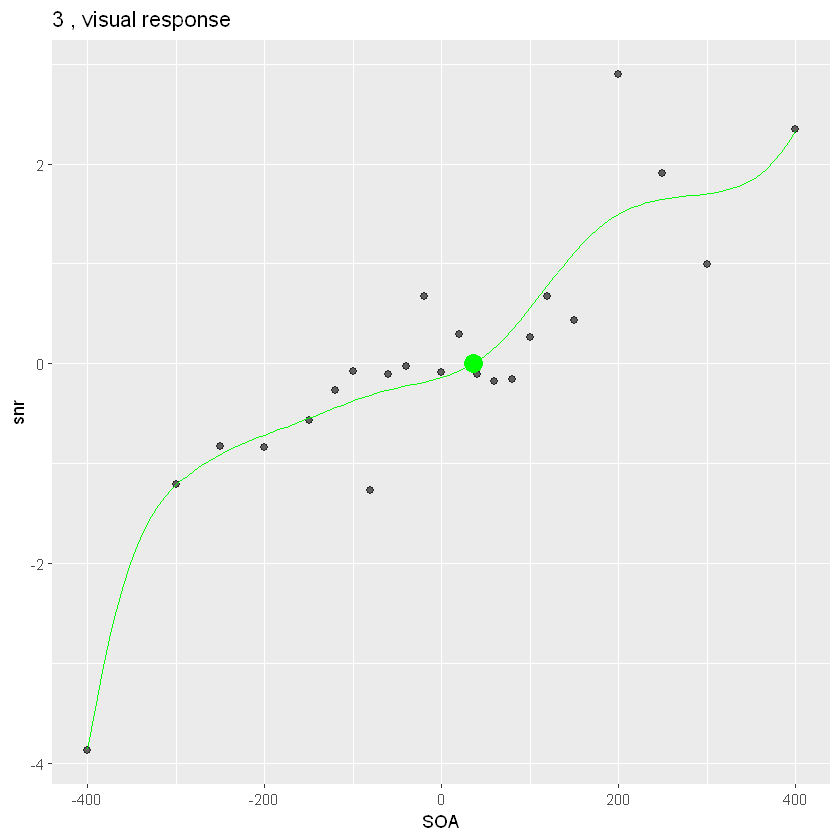

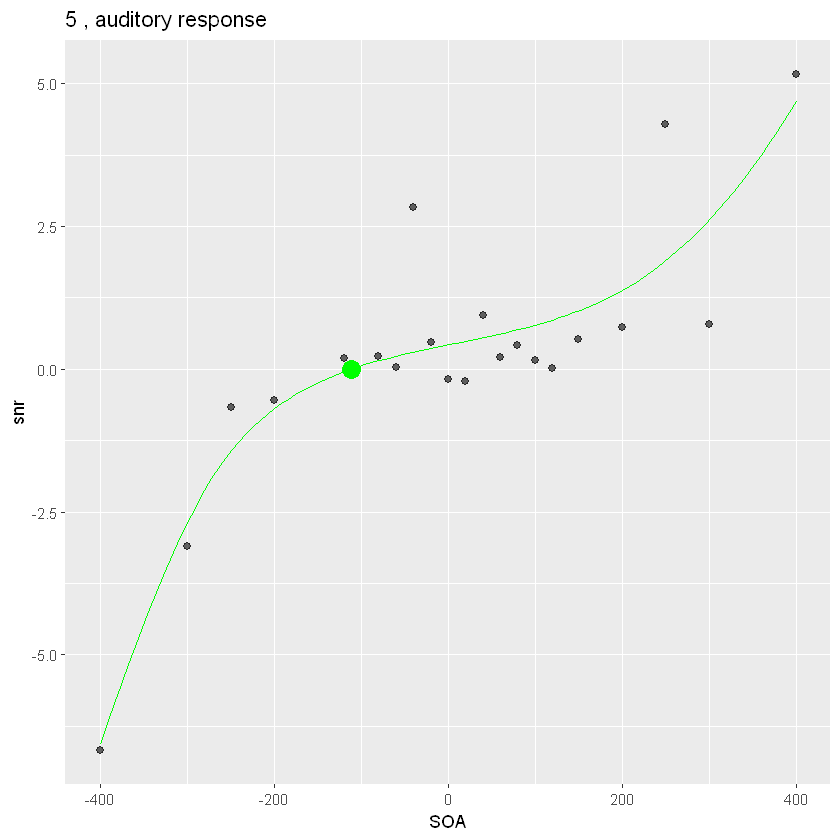

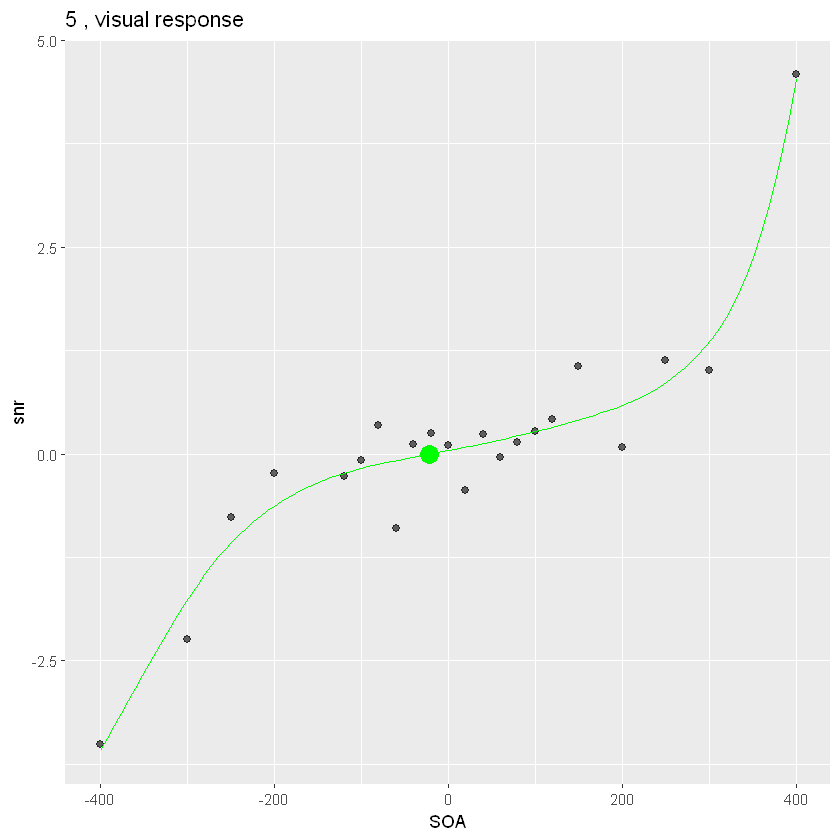

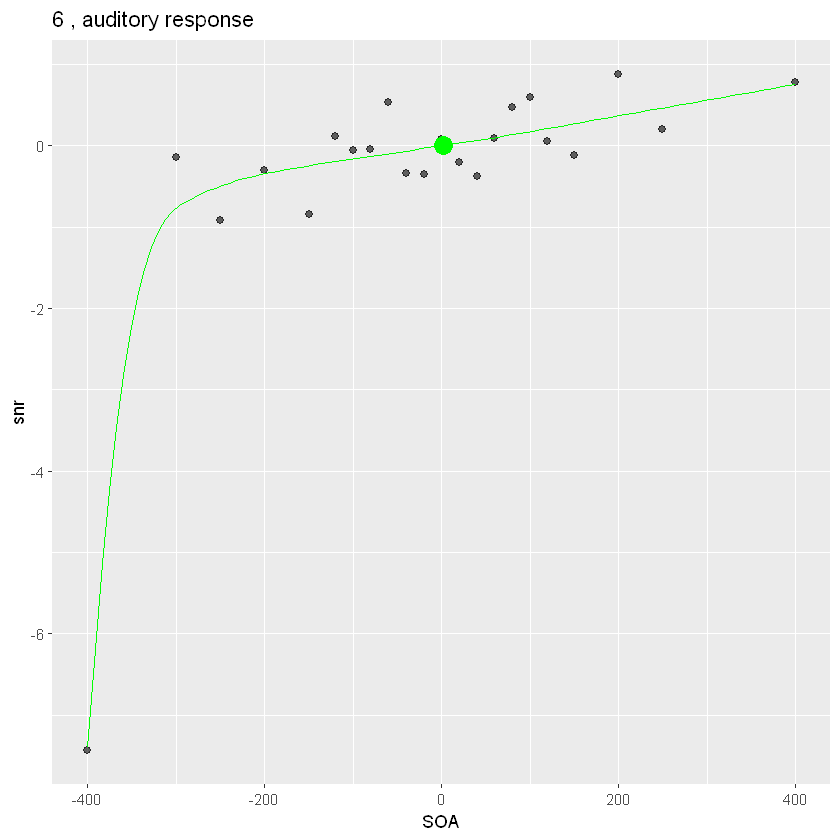

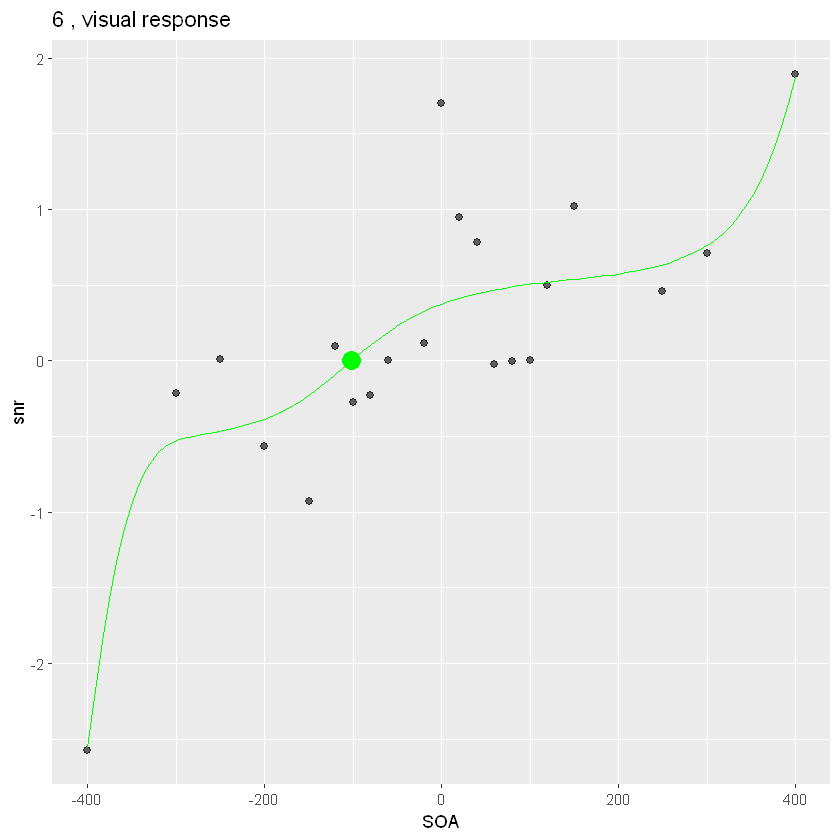

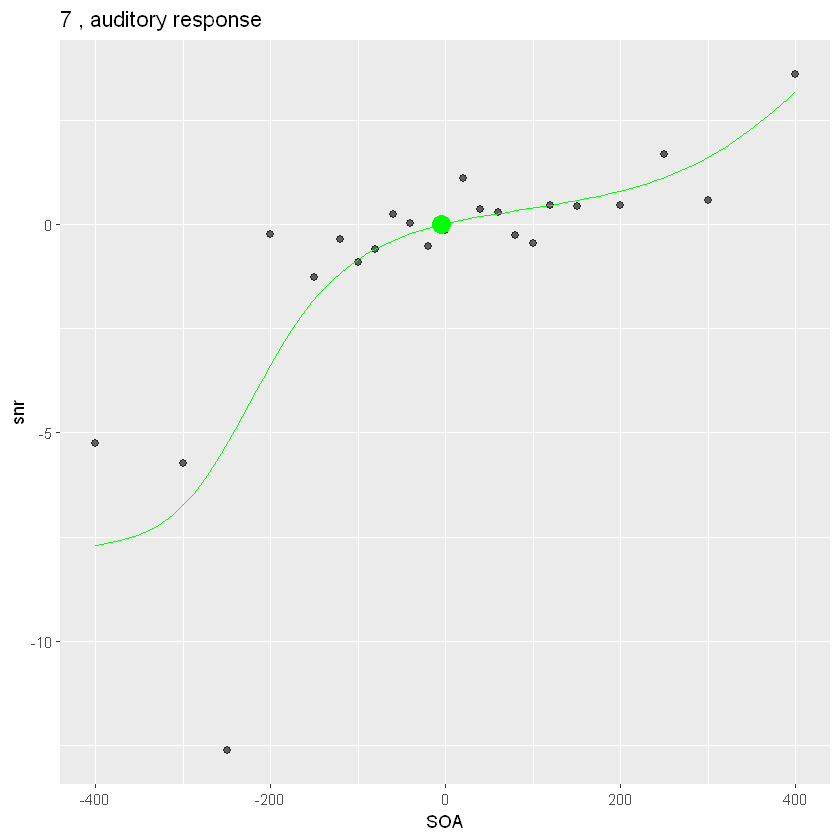

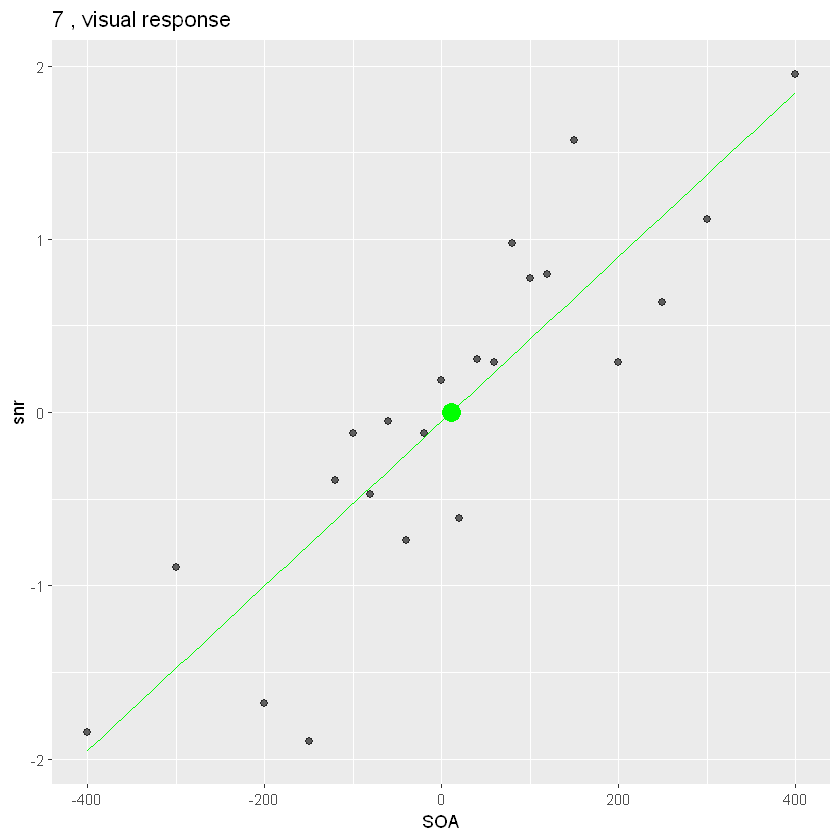

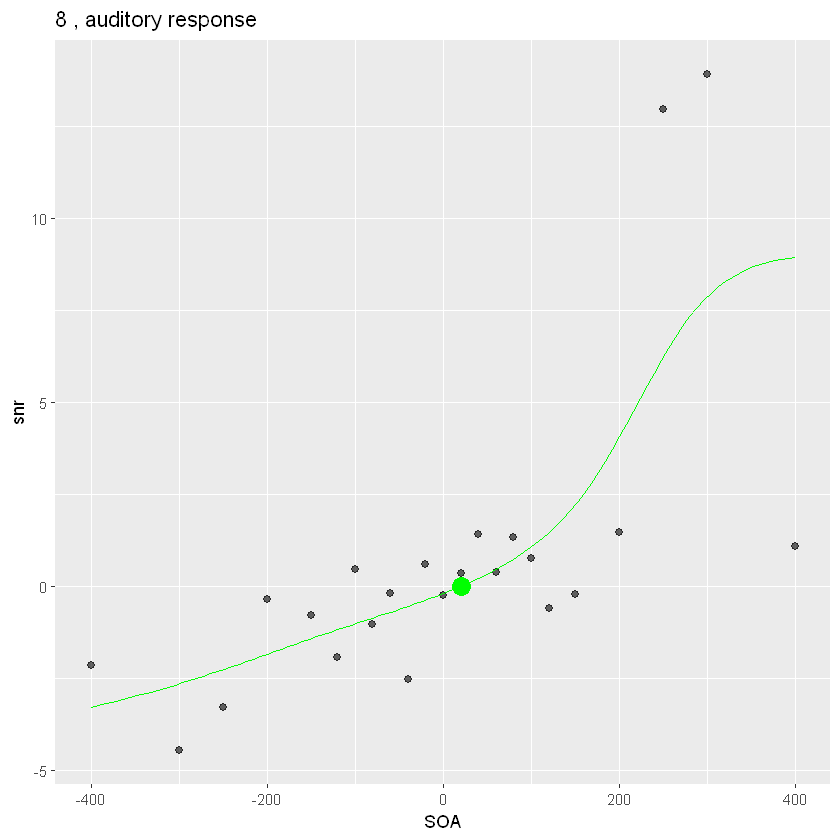

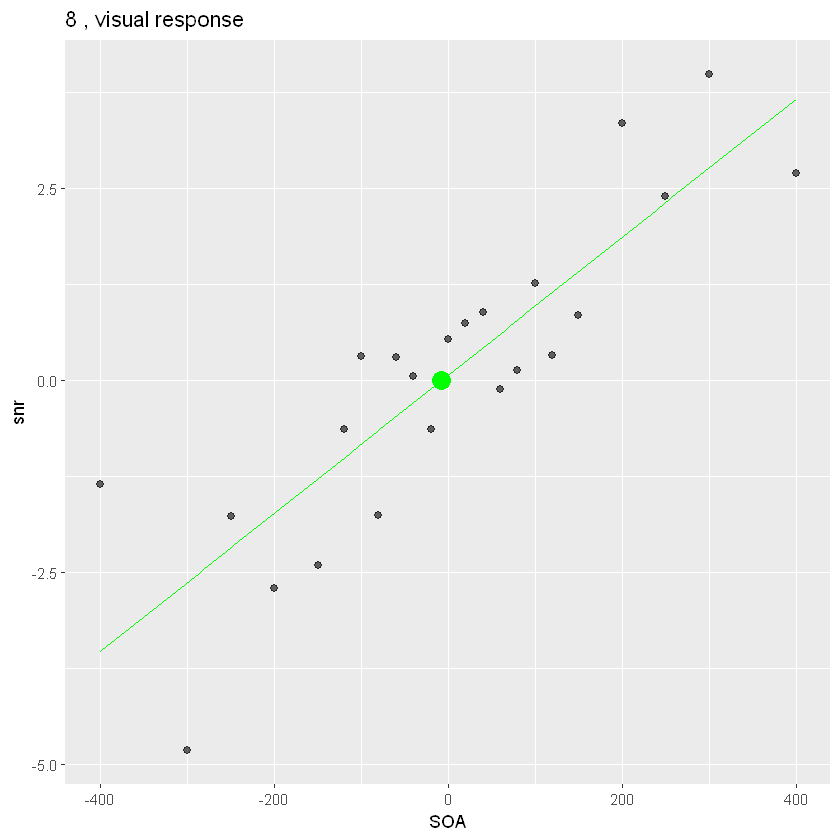

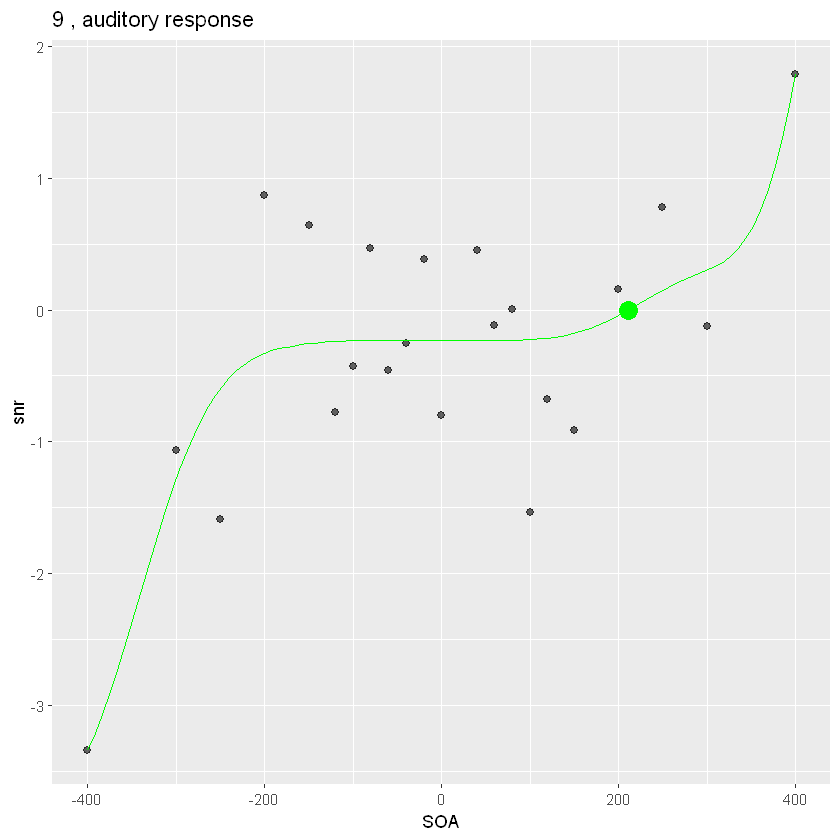

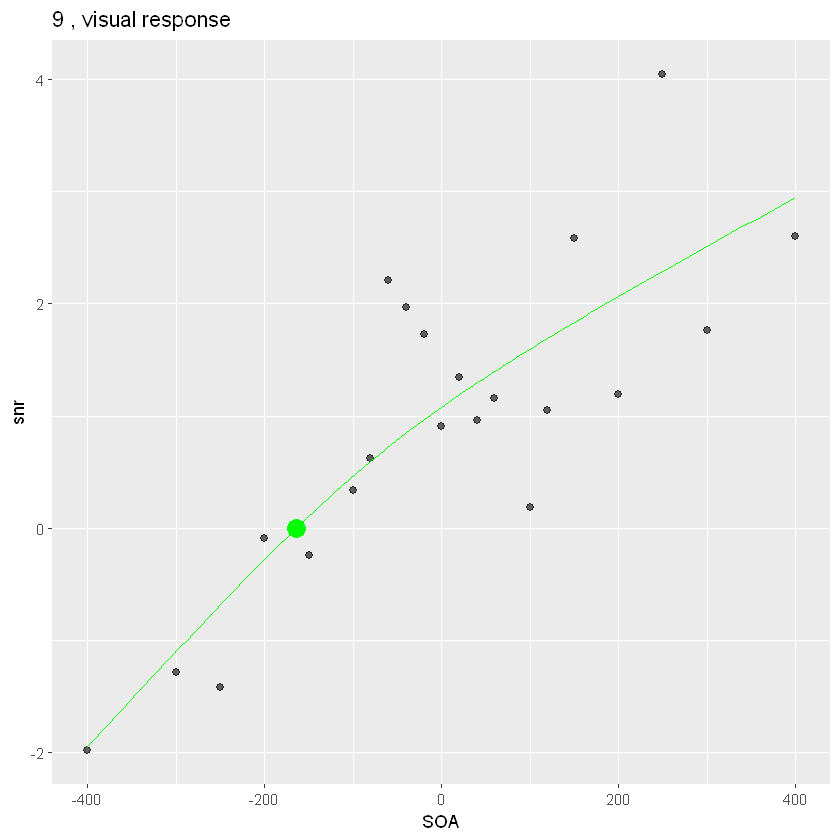

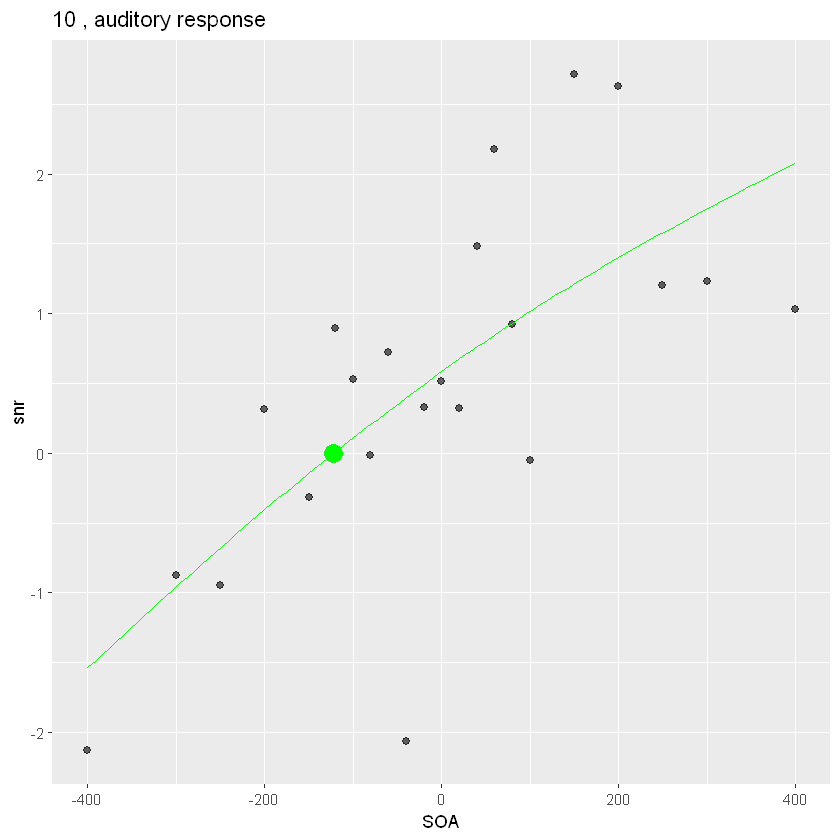

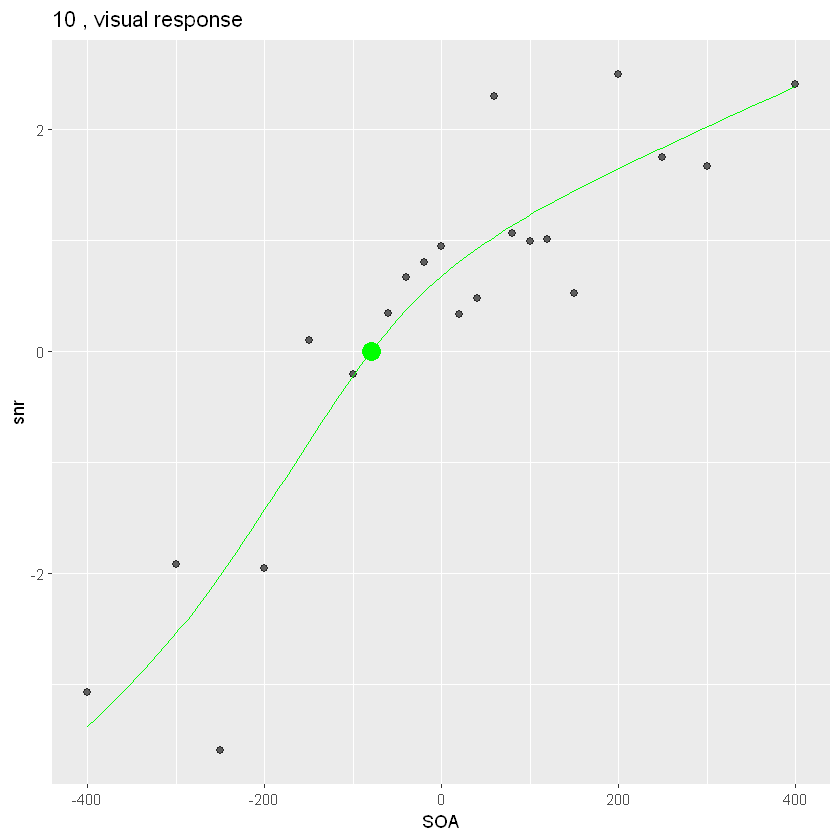

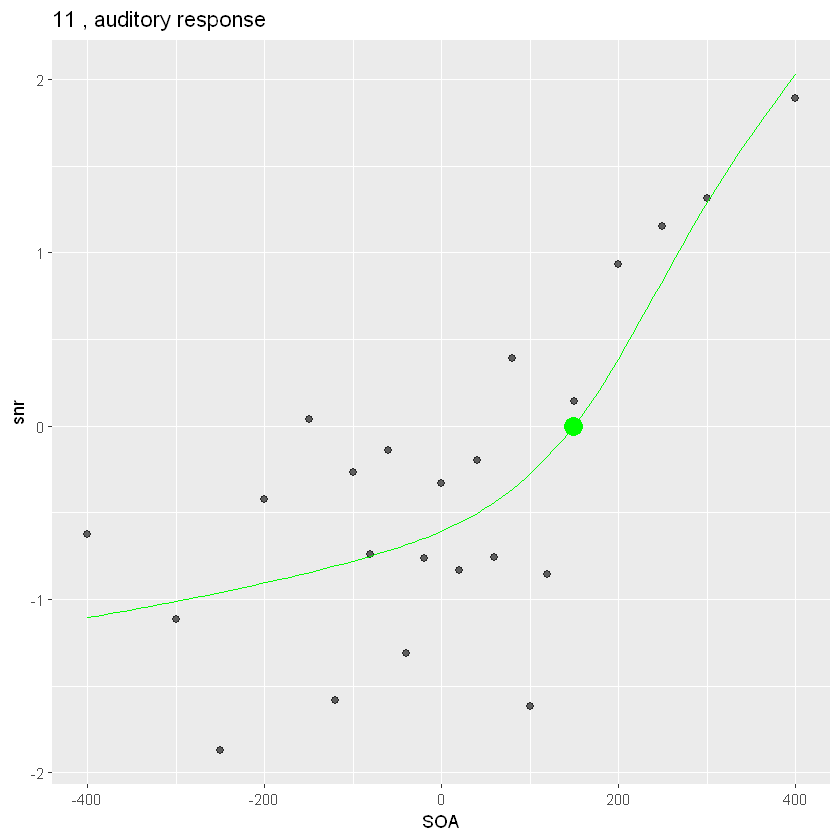

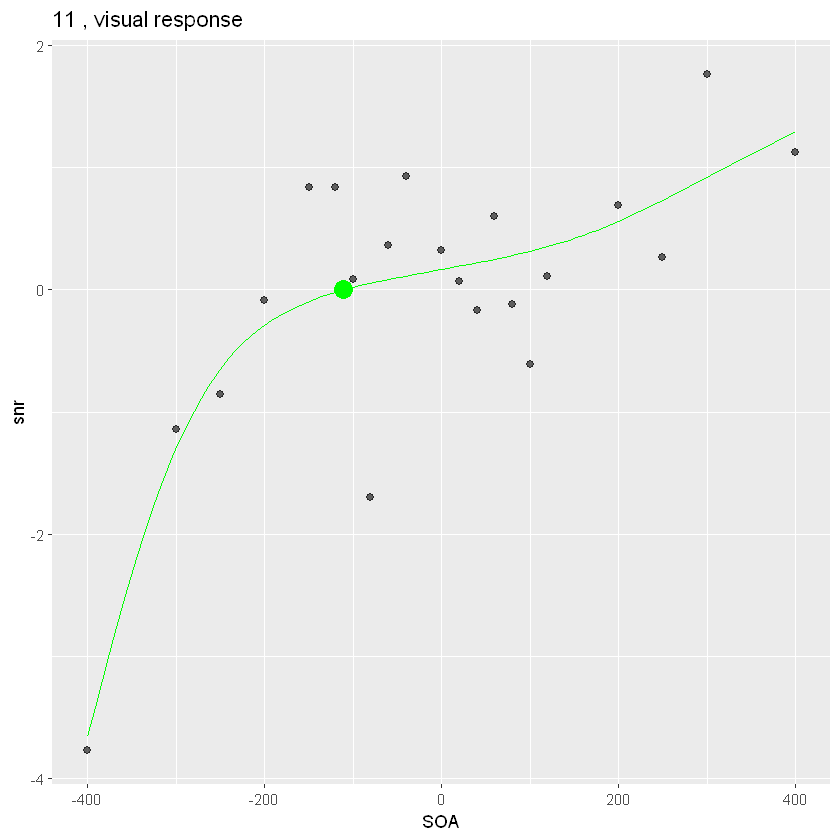

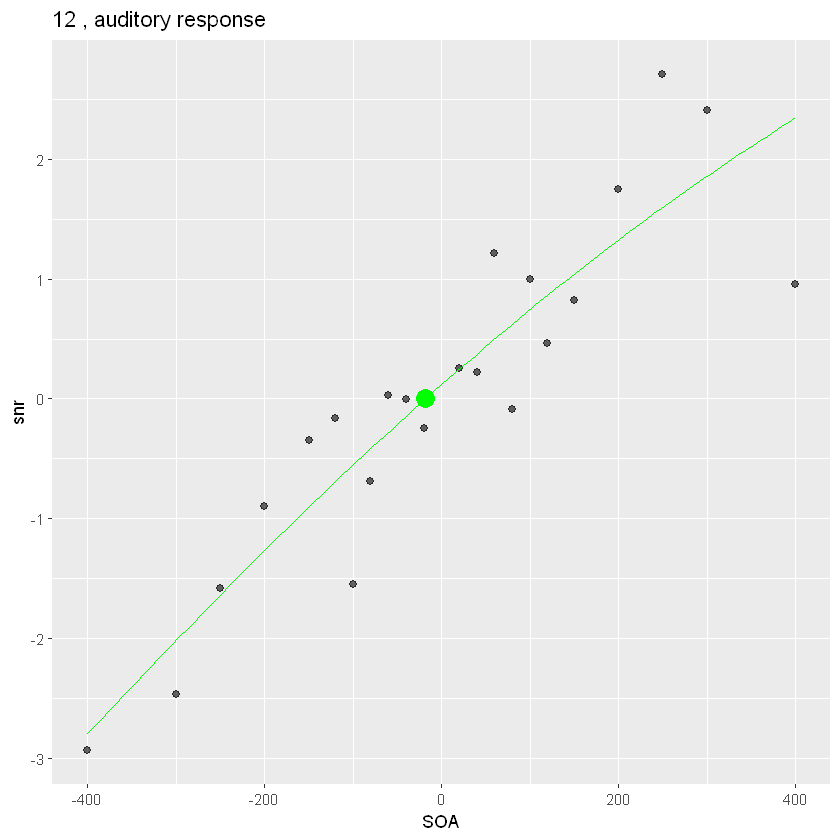

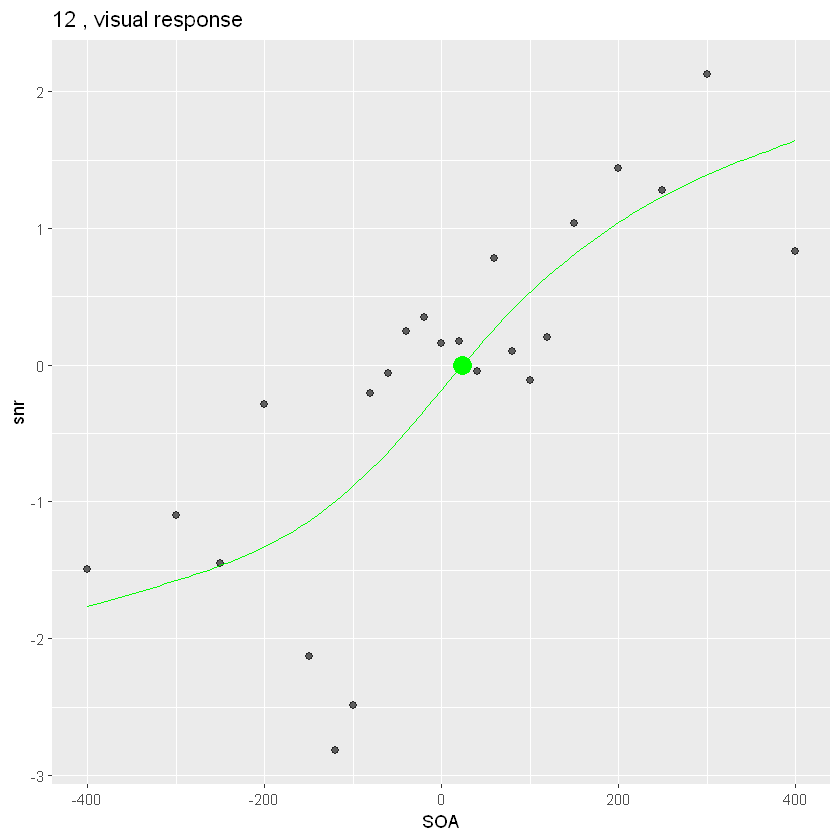

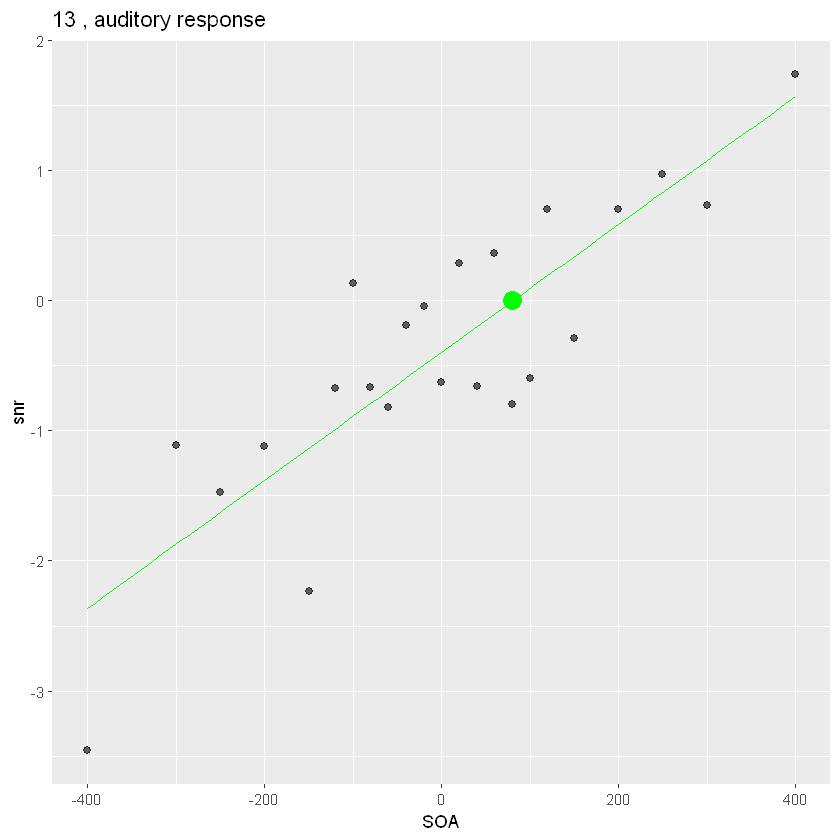

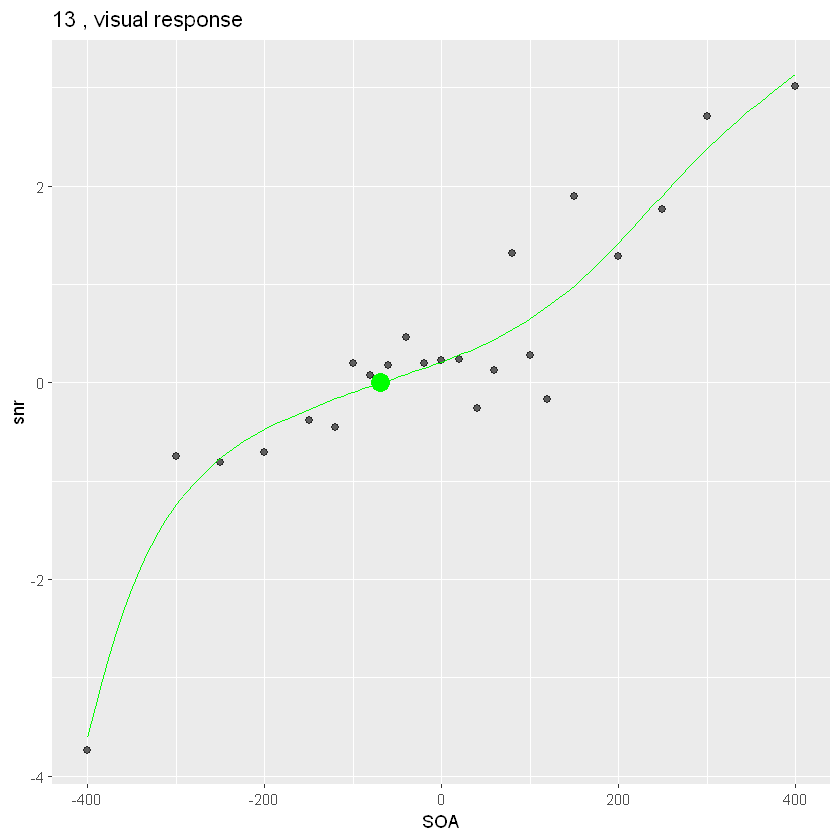

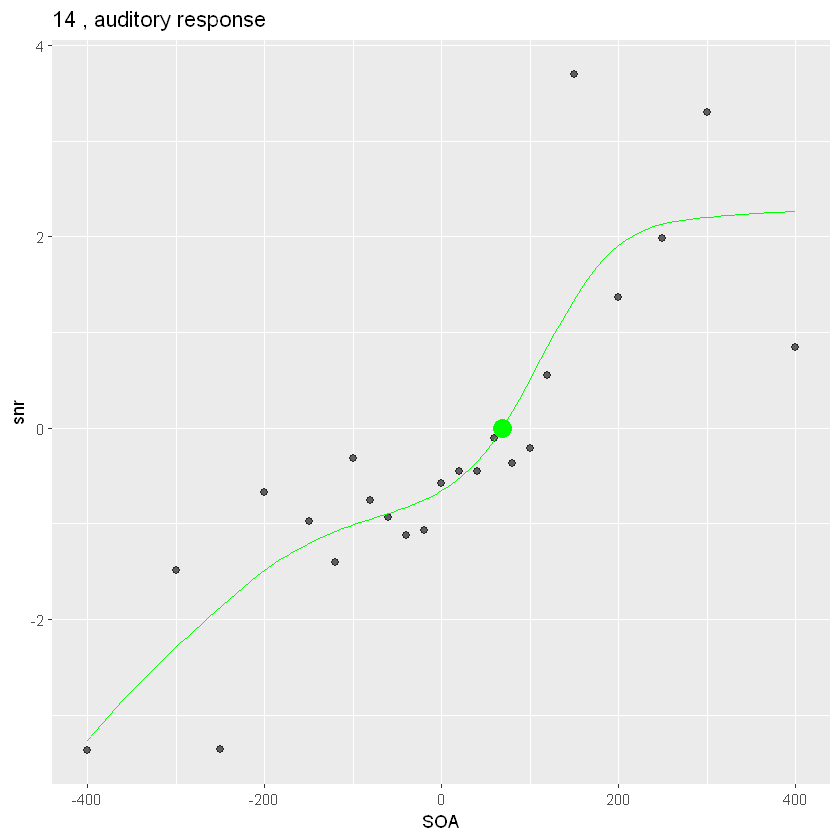

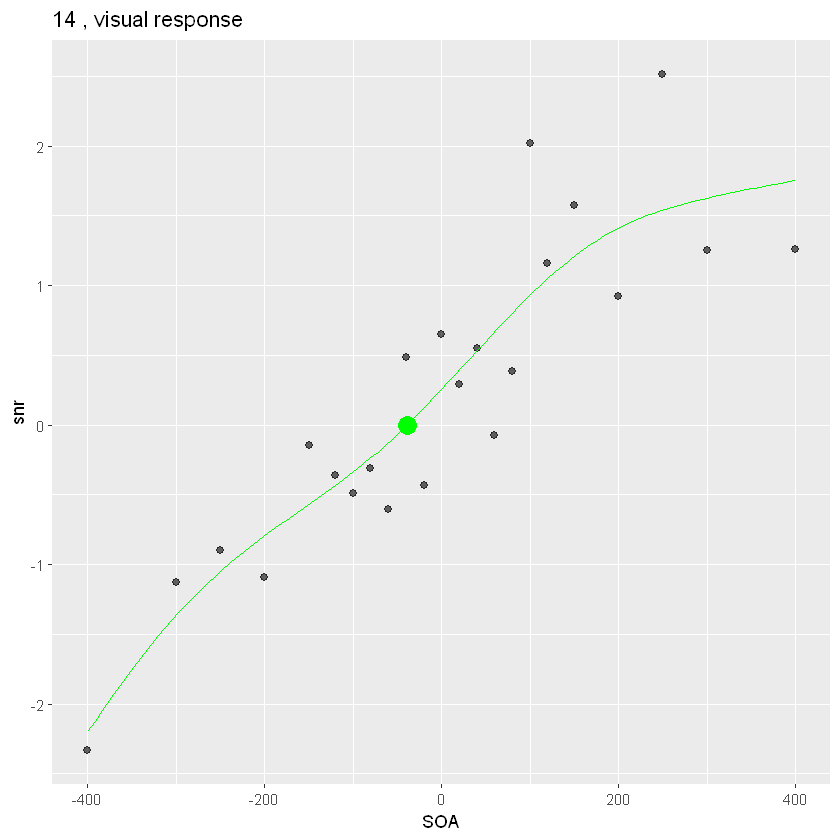

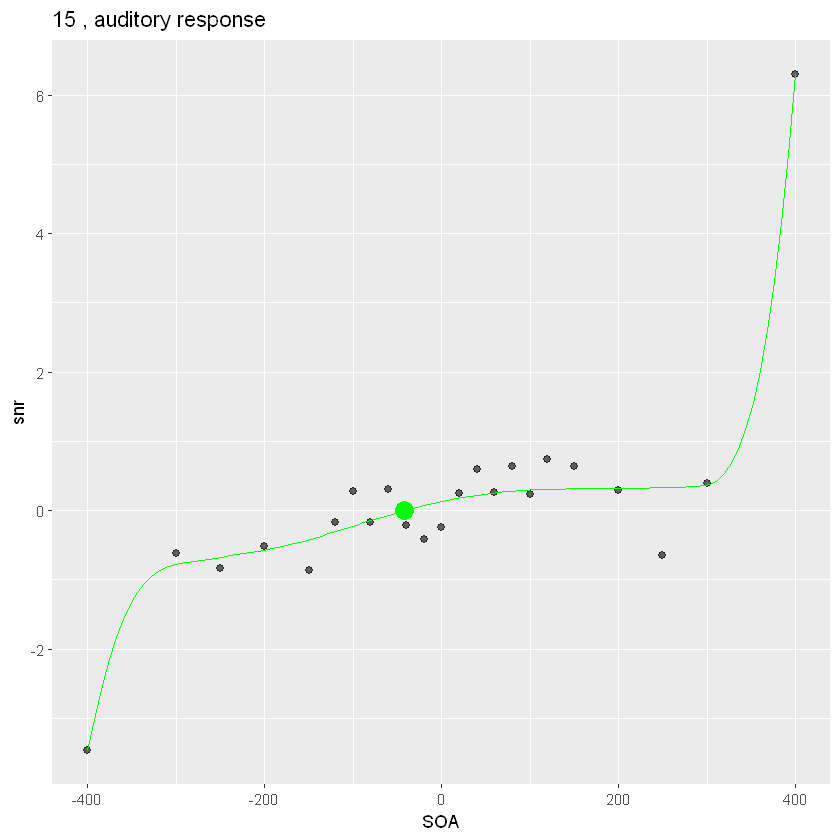

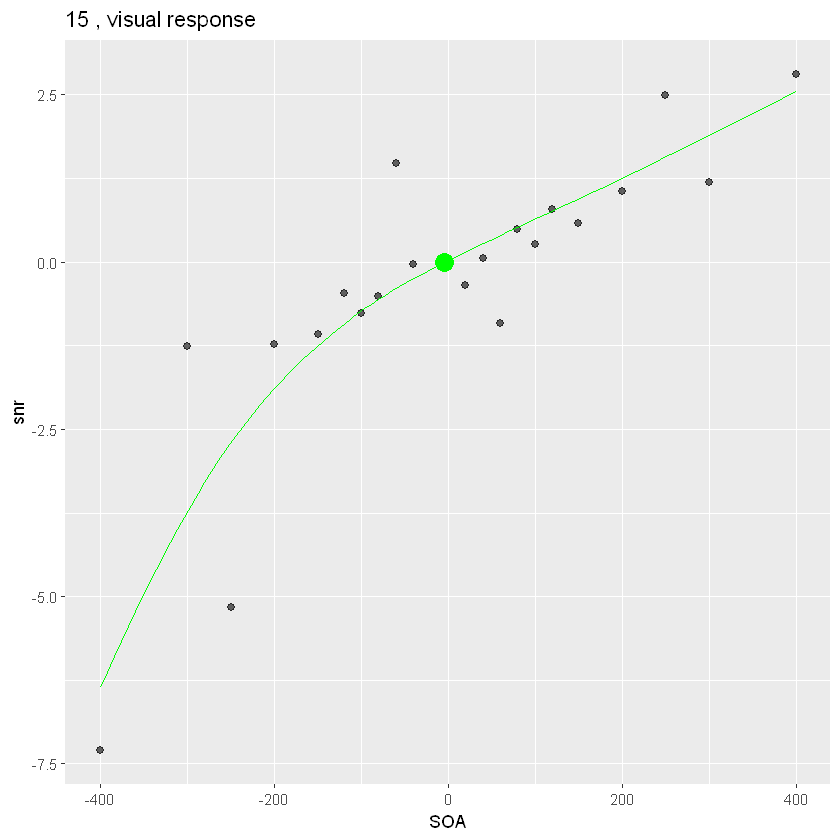

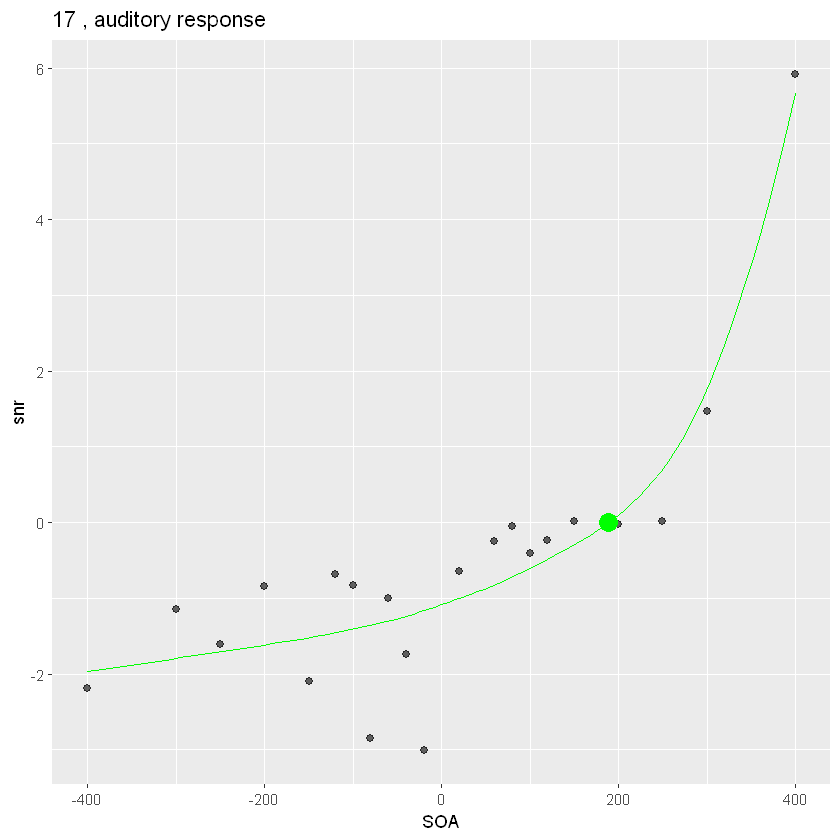

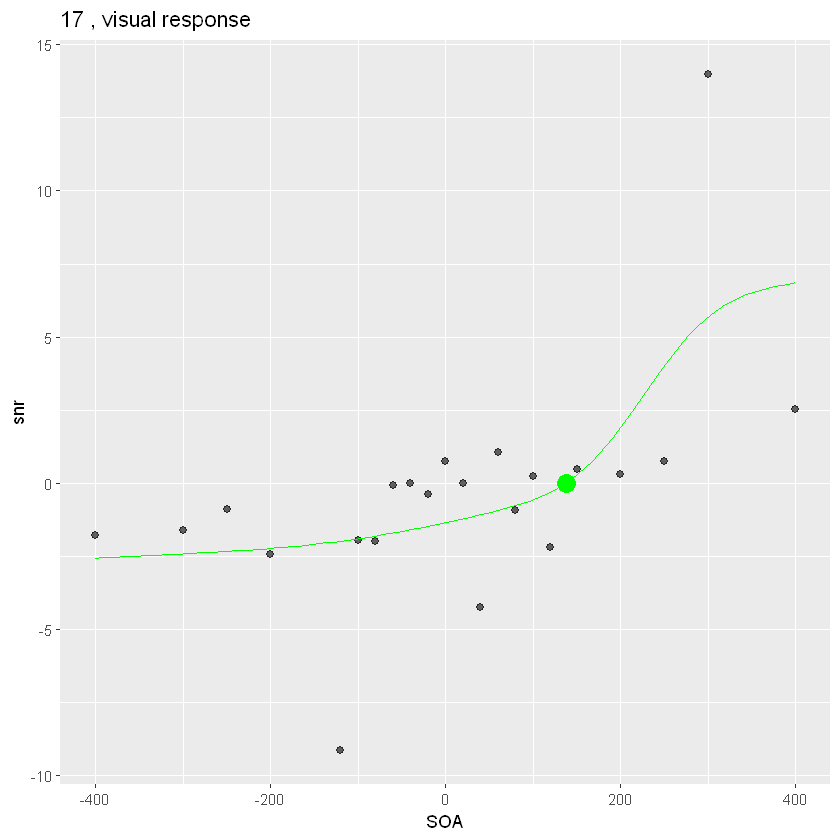

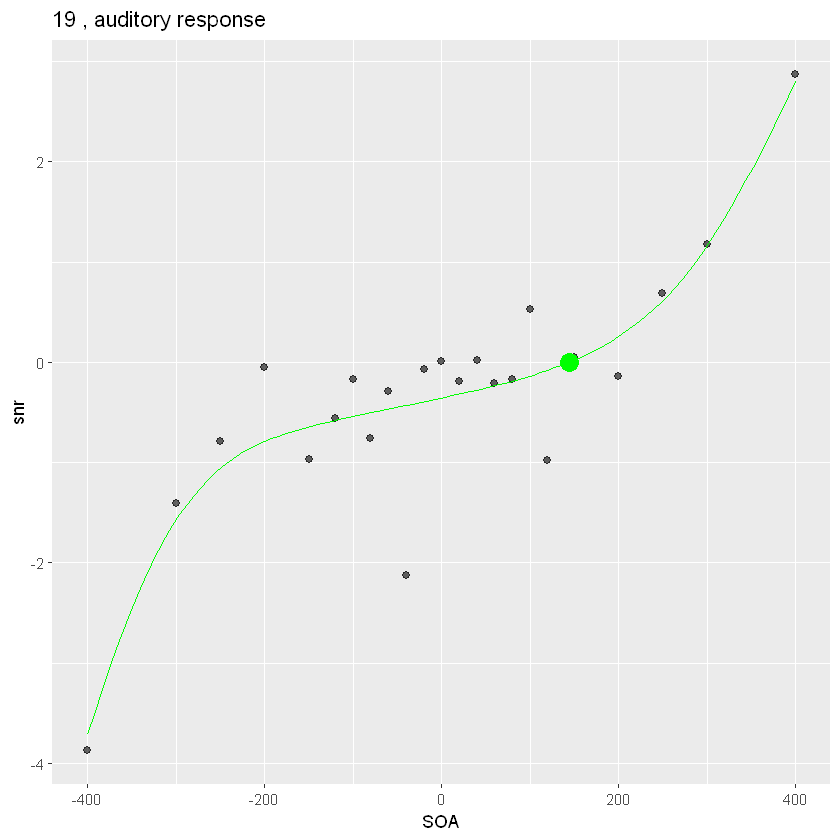

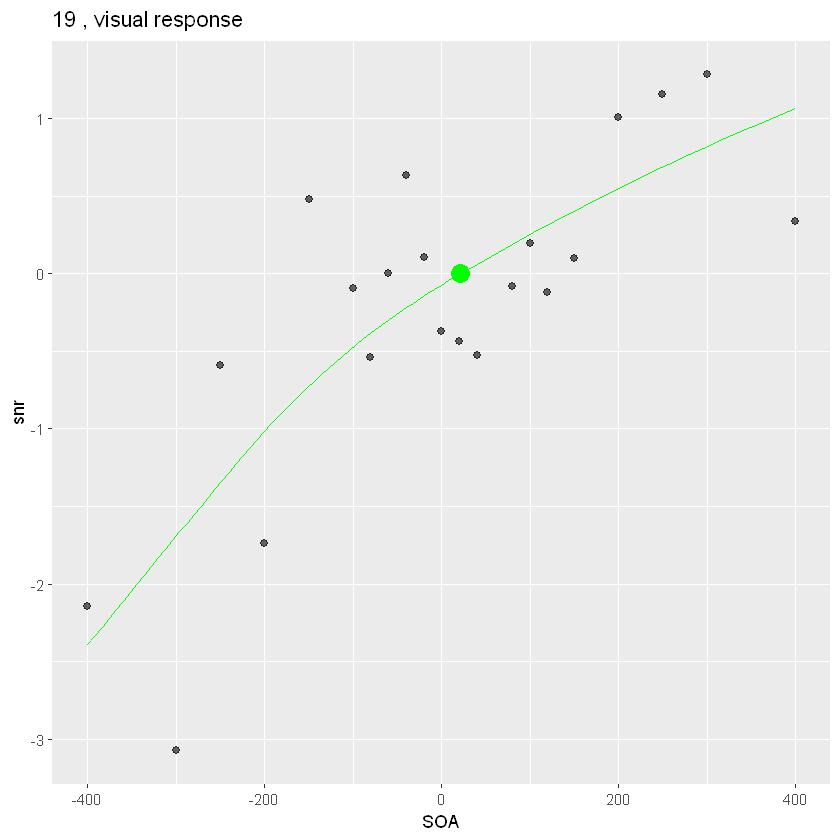

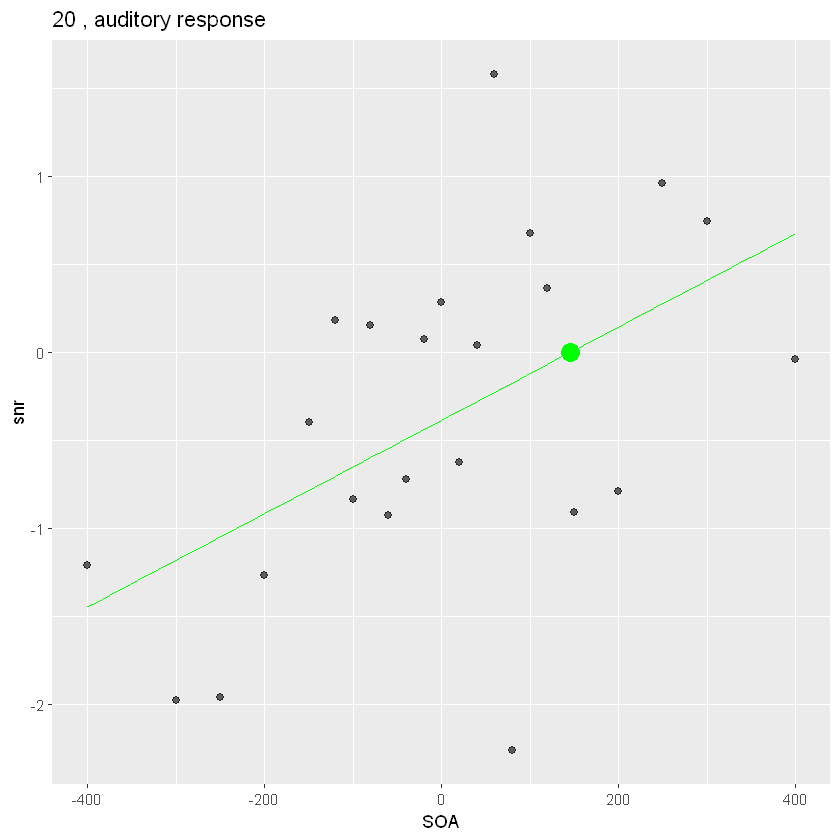

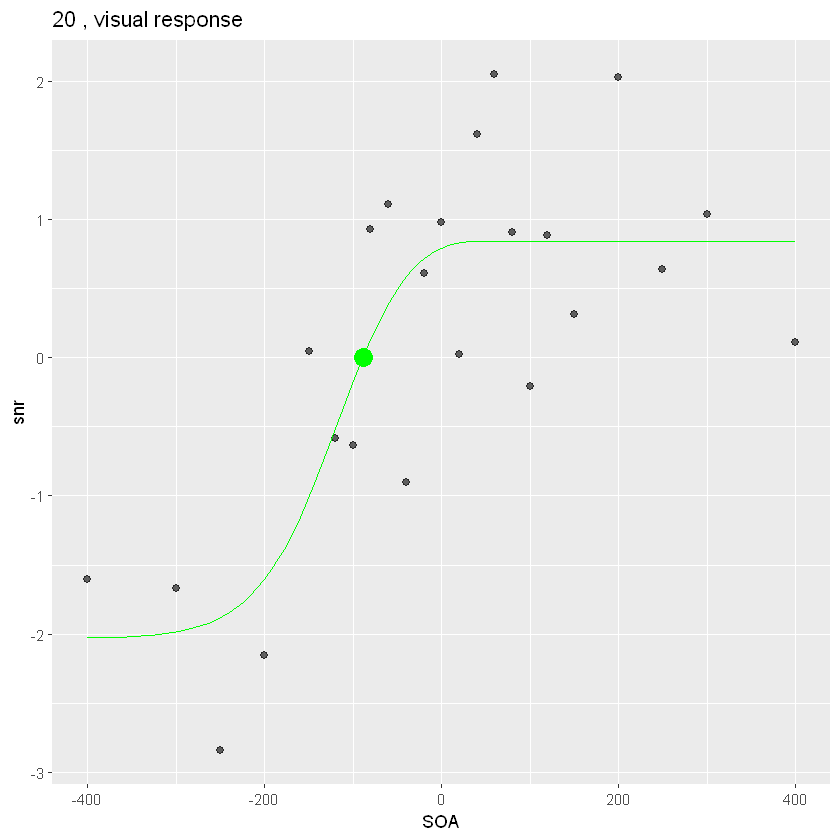

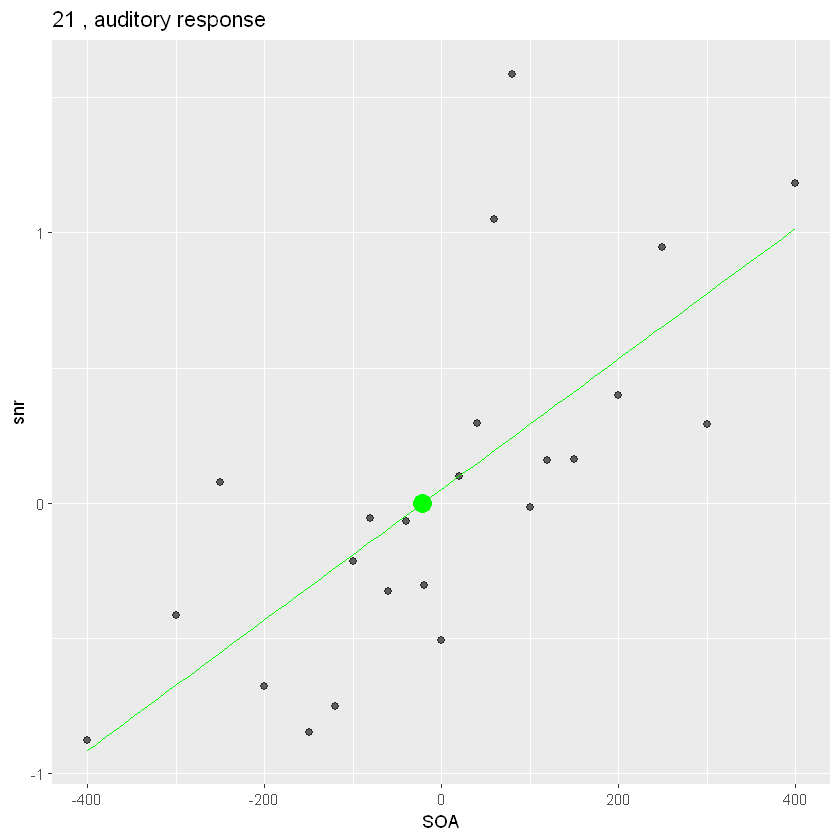

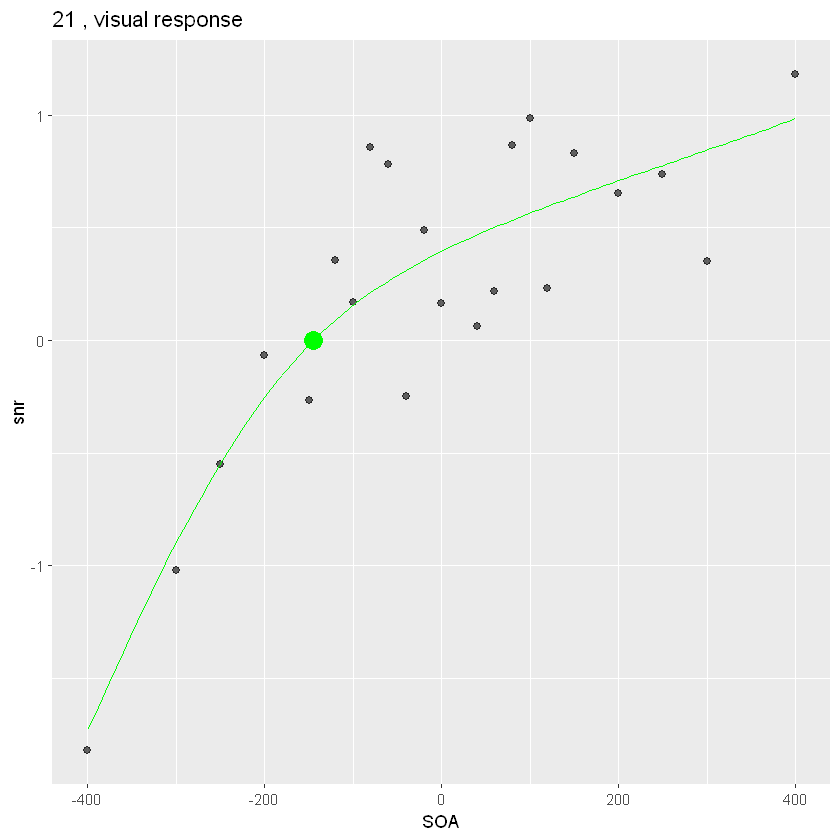

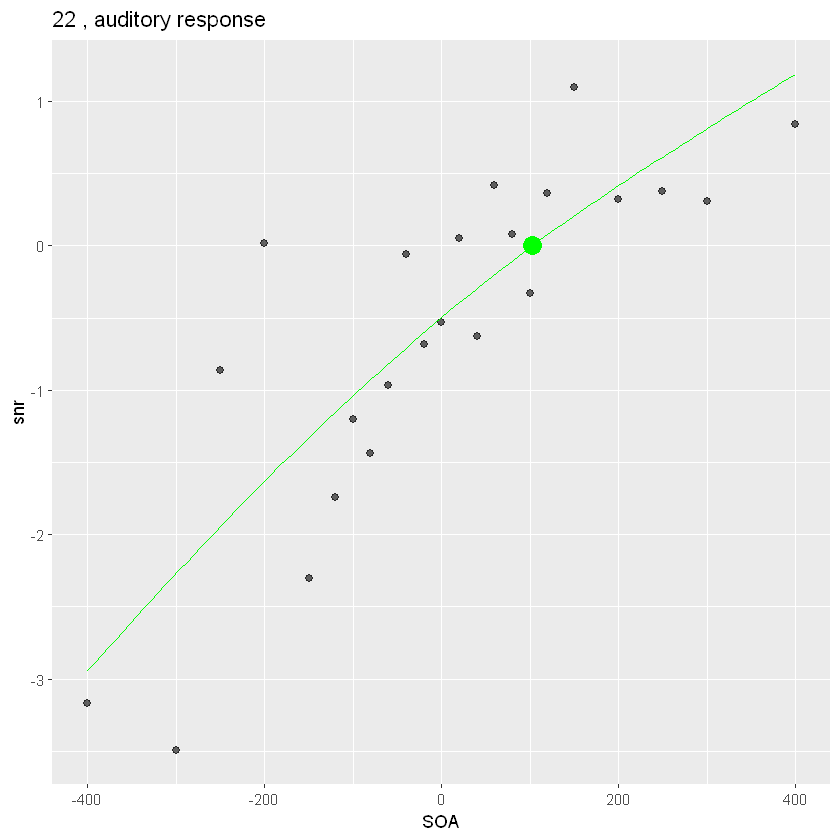

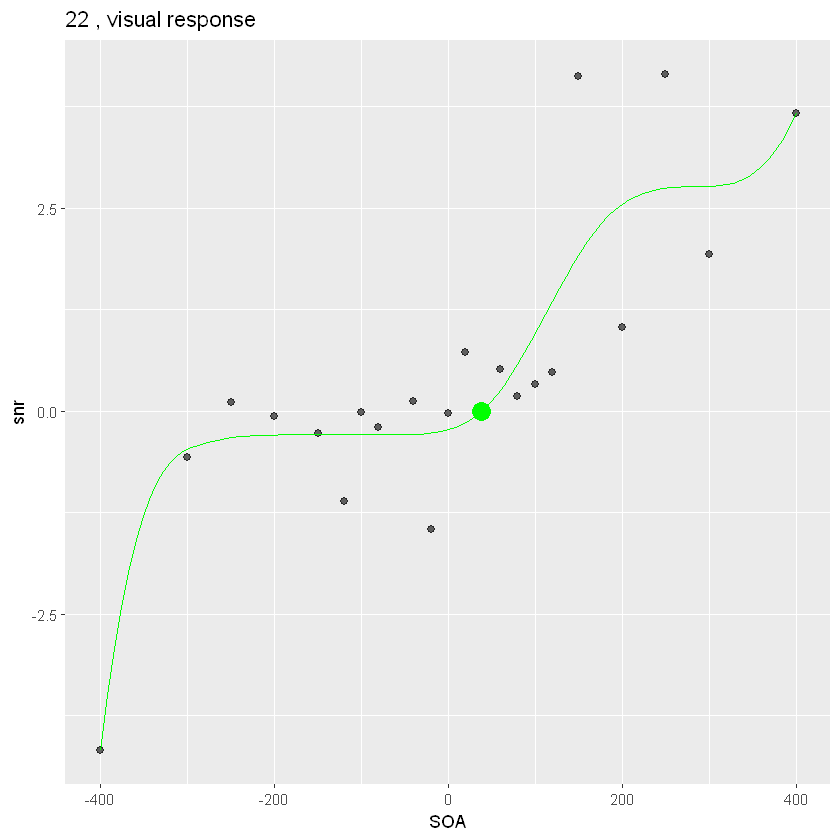

In [11]:
#==============================================================================#
# ESTIMATING LATENT SENSORY BIAS VIA SHAPE-CONSTRAINED ADDITIVE MODELS (SCAM)
# PURPOSE: Fit increasing-constrained splines
#          to SNR profiles per participant and condition, identifying functions' 
#          roots (zeros) to quantify sensory bias thresholds.

#The zero-crossing point of this function corresponds to
# the SOA at which accumulated sensory evidence is balanced
# between the two response alternatives.
# This value serves as an estimate of sensory bias (PSE-like).
#==============================================================================#

sigmoid_results <- data.frame()

for (participant in unique(df_resp$ID)) {
    for (condition in unique(df_resp$prior_response)) {
        df_resp_subset <- df_resp %>% filter(ID == participant, prior_response == condition)

        model <- scam(snr ~ s(SOA, bs = "mpi"), data = df_resp_subset)
        ff <- function(SOA) {
              predict(model, data.frame(SOA = SOA))
            }
        roots <- findZeros(ff(x)~x)
        
        print(ggplot(df_resp_subset, aes(x = SOA, y = snr)) +
              ggtitle(glue('{participant} , {condition}')) +
          geom_point(size = 2, alpha = 0.6) + 
          geom_function(fun=ff, color='green') +
          geom_point(data = data.frame(x=roots, y=0), aes(x=x,y=y),size = 5, color='green')
             )

        sigmoid_results <- rbind(sigmoid_results, data.frame(
            ID = participant,
            prior_response = condition,
            root = mean(roots$x)))
  }
}

In [13]:
write_xlsx(sigmoid_results,"files/TOJ_prior_response_sensory_bias.xlsx")

In [12]:
# ---------------------------------------------------------
# Decision bias is quantified using the relative starting
# point (z/a). This parameter reflects the bias in the
# decision process toward one response boundary.
# ---------------------------------------------------------

df_summary <- df_resp %>%
  group_by(ID, prior_response) %>%
  summarise(mean_Z = median(Z, na.rm = TRUE),
            .groups = "drop")

write_xlsx (df_summary,"files/TOJ_prior_response_decision_bias.xlsx")

###############################################################
## 2-3 Testing change in SNR root

In [27]:
sigmoid_results <- read_xlsx("files/TOJ_prior_response_sensory_bias.xlsx")

In [28]:
sigmoid_results2 <- sigmoid_results %>% group_by(ID) %>% summarise(
    diff = root[prior_response == "visual response"] - root[prior_response == "auditory response"],
    .groups = "drop"
  )
head(sigmoid_results2)

ID,diff
<dbl>,<dbl>
1,-84.0175
3,25.4523
5,90.0846
6,-103.7588
7,15.8442
8,-28.2295


In [29]:
#summary
sigmoid_results %>% group_by(prior_response) %>%  get_summary_stats(root)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory response,root,18,-121.987,211.340,15.468,-20.601,133.764,154.365,112.409,40.722,100.648,23.723,50.051
visual response,root,18,-164.427,137.383,-30.165,-98.609,18.759,117.368,83.108,-40.003,80.320,18.932,39.942


In [30]:
sigmoid_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-375.767,90.085,-74.631,-123.26,23.05,146.31,122.657,-80.725,121.419,28.619,60.38


In [31]:
#identify outlier
dd <- sigmoid_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>
9,-375.7672,TRUE,FALSE


In [32]:
#Removing outliers data
sigmoid_results <- sigmoid_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
sigmoid_results2 <- sigmoid_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [33]:
# normality
sigmoid_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9366269,0.2535084


Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the ggpubr package.
  Please report the issue at <https://github.com/kassambara/ggpubr/issues>."
Warning message:
"The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the ggpubr package.
  Please report the issue at <https://github.com/kassambara/ggpubr/issues>."


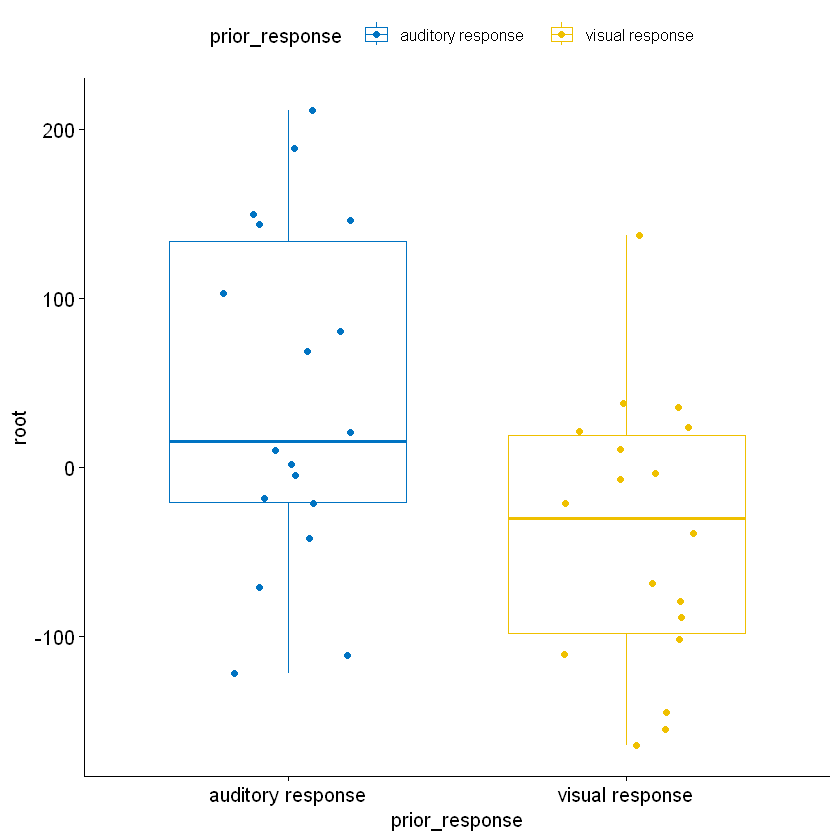

In [34]:
#plot
ggboxplot(
  sigmoid_results, x = "prior_response", y = "root",
  color = "prior_response", palette = "jco", add = "jitter"
  )

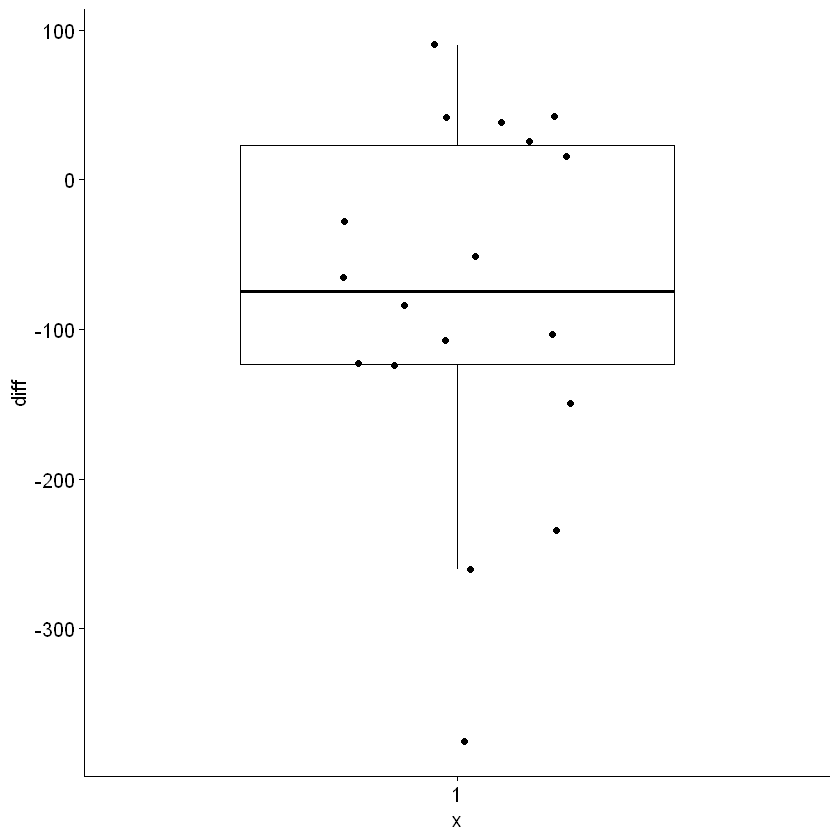

In [35]:
ggboxplot(
  sigmoid_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [36]:
sigmoid_results %>% t_test(root ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,80.72491,root,auditory response,visual response,18,18,2.820709,0.0118,17,20.34482,141.105,T-test,two.sided


In [37]:
sigmoid_results %>% cohens_d(root ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,root,auditory response,visual response,0.6648476,18,18,moderate


###############################################################
## 2-4 Testing change in relative starting point

In [38]:
df_summary <- read_xlsx("files/TOJ_prior_response_decision_bias.xlsx")

In [39]:
df_summary2 <- df_summary %>% group_by(ID) %>% summarise(
    diff = mean_Z[prior_response == "visual response"] - mean_Z[prior_response == "auditory response"],
    .groups = "drop"
  )
head(df_summary2)

ID,diff
<dbl>,<dbl>
1,0.22868054
3,0.02369460
5,-0.02145905
6,0.02914601
7,0.09660879
8,0.31781192


In [40]:
df_summary %>% group_by(prior_response) %>%  get_summary_stats(mean_Z)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory response,mean_Z,18,-0.325,0.517,-0.063,-0.208,0.142,0.351,0.254,-0.004,0.245,0.058,0.122
visual response,mean_Z,18,-0.148,0.456,0.233,0.043,0.297,0.254,0.170,0.182,0.188,0.044,0.093


In [41]:
df_summary2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-0.257,0.617,0.178,0.025,0.296,0.27,0.224,0.187,0.244,0.057,0.121


In [42]:
#identify outlier
dd <- df_summary2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [43]:
#Removing outliers data
df_summary <- df_summary %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
df_summary2 <- df_summary2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [44]:
# normality
df_summary2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9534101,0.4809836


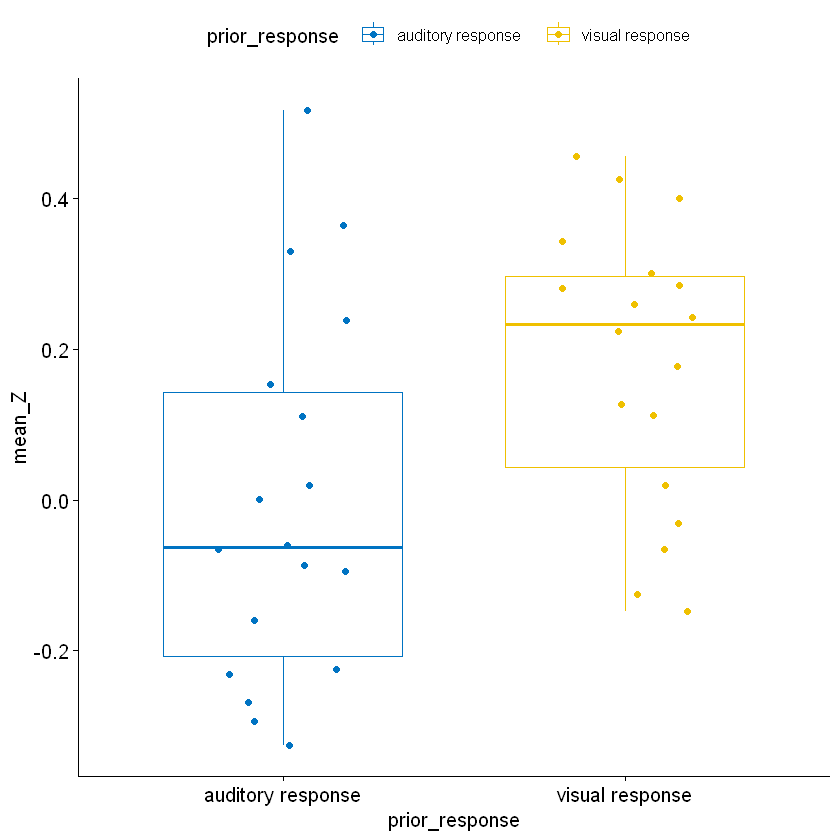

In [45]:
#plot
ggboxplot(
  df_summary, x = "prior_response", y = "mean_Z",
  color = "prior_response", palette = "jco", add = "jitter"
  )

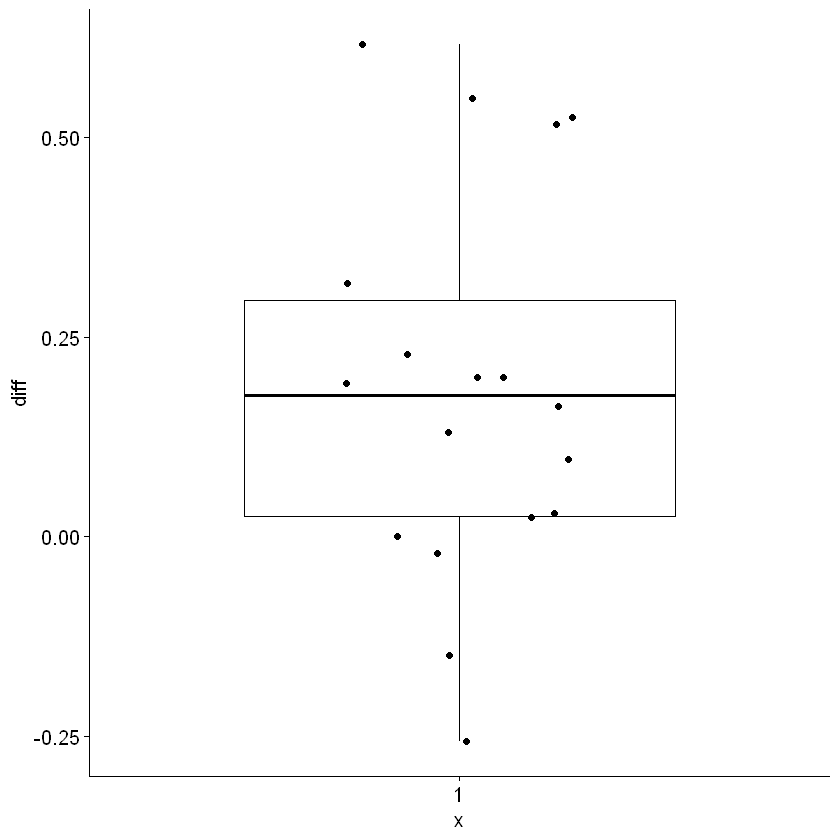

In [46]:
ggboxplot(
  df_summary2, y = "diff", palette = "jco", add = "jitter"
  )

In [47]:
df_summary %>% t_test(mean_Z ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-0.1867295,mean_Z,auditory response,visual response,18,18,-3.250925,0.0047,17,-0.3079149,-0.06554406,T-test,two.sided


In [48]:
df_summary %>% cohens_d(mean_Z ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,mean_Z,auditory response,visual response,-0.7662504,18,18,moderate


###############################################################\
###############################################################
# 3- Prior stimulus
**List of contents:**\
3-1 Plotting SNR curves\
3-2 Calculating sensory and decisional bias\
3-3 Testing change in SNR root\
3-4 Testing change in relative starting point

In [51]:
# =========================================================
# Load DDM parameter estimates (prior stimulus model)
# =========================================================

df_stim <- read_xlsx("files/TOJ_prior_stimulus_DDM_parameters_clean.xlsx")

colnames(df_stim)[1] <- "ID"
colnames(df_stim)[2] <- "prior_stimulus"

df_stim$prior_stimulus <- recode(df_stim$prior_stimulus,
                                 "visual_leading" = "visual leading",
                                 "auditory_leading" = "auditory leading")

# Compute sensory evidence strength
df_stim$snr <- df_stim$drift / df_stim$noise

###############################################################
## 3-1 Plotting SNR curves

In [52]:
head(df_stim)

ID,prior_stimulus,SOA,drift,noise,bound,Z,t0,snr
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,auditory leading,-400,-1.22436404,0.1887488,1,0.71684762,0.004738435,-6.48673867
1,auditory leading,-300,-1.09444654,0.4543366,1,-0.07217972,0.545719026,-2.40888927
1,auditory leading,-250,-0.68518424,0.7768741,1,-0.12720377,0.744587841,-0.88197593
1,auditory leading,-200,0.05178986,0.9202096,1,-0.39017786,0.780359255,0.05628051
1,auditory leading,-150,-0.34299740,0.8900781,1,0.19021245,1.020131491,-0.38535651
1,auditory leading,-120,0.16293002,0.6710971,1,-0.75212576,0.927282291,0.24278159


In [82]:
summary_stim <- df_stim %>%
  group_by(SOA, prior_stimulus) %>%
  summarise(
    mean_snr = mean(snr, na.rm = TRUE),
    se_snr = sd(snr, na.rm = TRUE) / sqrt(n()),
    .groups = "drop"
  )

In [83]:
df_predicted = data.frame()
for (participant in unique(df_stim$ID)) {
    for (condition in unique(df_stim$prior_stimulus)) {
        df_stim_subset <- df_stim %>% filter(ID == participant, prior_stimulus == condition)

        model <- scam(snr ~ s(SOA, bs = "mpi"), data = df_stim_subset)
        ff <- function(SOA) {
              predict(model, data.frame(SOA = SOA))
            }
        df <- data.frame(ID=participant, prior_stimulus=condition, SOA = -400:400, snr=ff(-400:400))
        df_predicted <- rbind(df_predicted, df)
}}

In [84]:
df_predicted_summary <- df_predicted %>%
  group_by(prior_stimulus, SOA) %>%
  summarise(
    mean_snr = mean(snr),
    se = sd(snr) / sqrt(n()),
    .groups = "drop"
  )

png 
  2

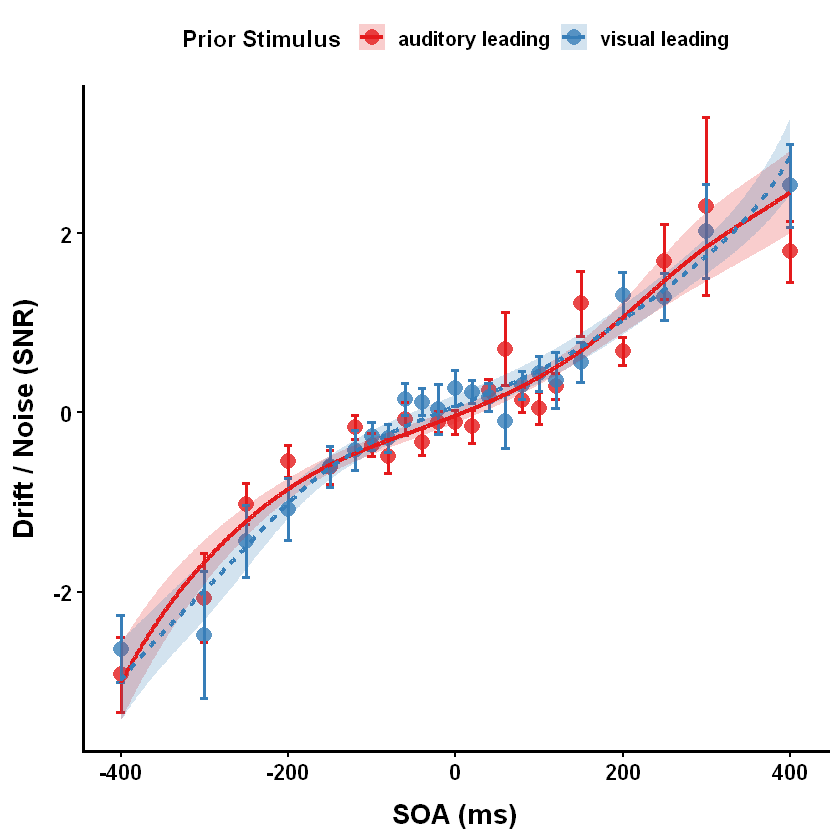

In [85]:
# save as PDF
pdf(file="figures/TOJ_prior_stimulus_snr.pdf", width = 10, height = 8)  

# Create the plot with publication-style formatting
p_toj_prior_stim <- ggplot() +
  # Plot observed data points
  geom_point(
    data = summary_stim,
    aes(x = SOA, y = mean_snr, color = prior_stimulus),
    alpha = 0.8,
    size = 4,
    shape = 16
  ) +

  # Add error bars for observed data
  geom_errorbar(
    data = summary_stim,
    aes(
      x = SOA,
      ymin = mean_snr - se_snr,
      ymax = mean_snr + se_snr,
      color = prior_stimulus
    ),
    width = 10,
    linewidth = 1
  ) +

  # Add shaded ribbon around fitted values
  geom_ribbon(
    data = df_predicted_summary,
    aes(
      x = SOA,
      ymin = mean_snr - se,
      ymax = mean_snr + se,
      fill = prior_stimulus,
      group = prior_stimulus
    ),
    alpha = 0.22,
    color = NA
  ) +

  # Plot fitted curves
  geom_line(
    data = df_predicted_summary,
    aes(
      x = SOA,
      y = mean_snr,
      color = prior_stimulus,
      linetype = prior_stimulus,
      group = prior_stimulus
    ),
    linewidth = 1.2
  ) +

  # Define labels
  labs(
    x = "SOA (ms)",
    y = "Drift / Noise (SNR)",
    color = "Prior Stimulus",
    linetype = "Prior Stimulus",
    fill = "Prior Stimulus"
  ) +

  # Use a clean theme consistent with previous figures
  theme_classic(base_size = 14) +
  theme(
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    legend.position = "top",
    axis.line = element_line(linewidth = 1)
  ) +

  # Use the same color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  scale_fill_brewer(palette = "Set1")
p_toj_prior_stim
dev.off()
# 3. Display the plot
print(p_toj_prior_stim)

###############################################################
## 3-2 Calculating sensory and decisional bias

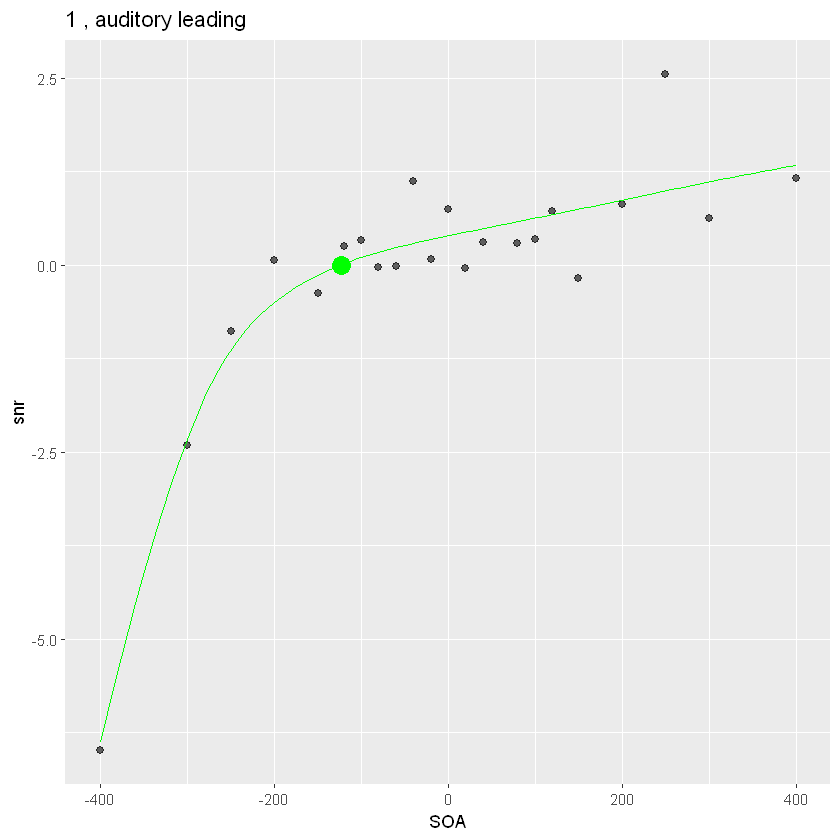

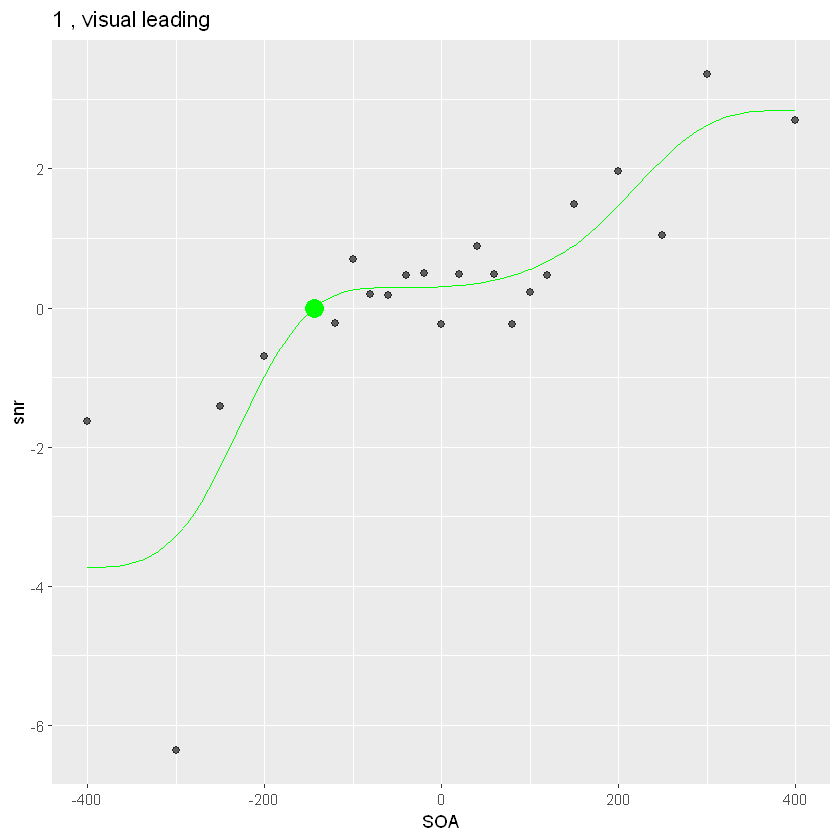

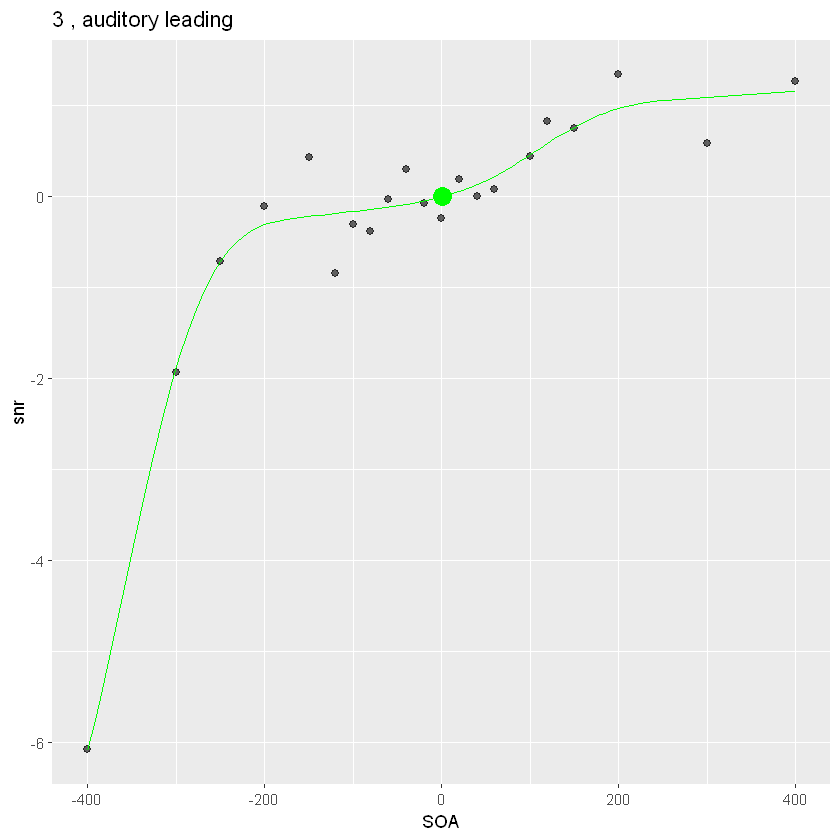

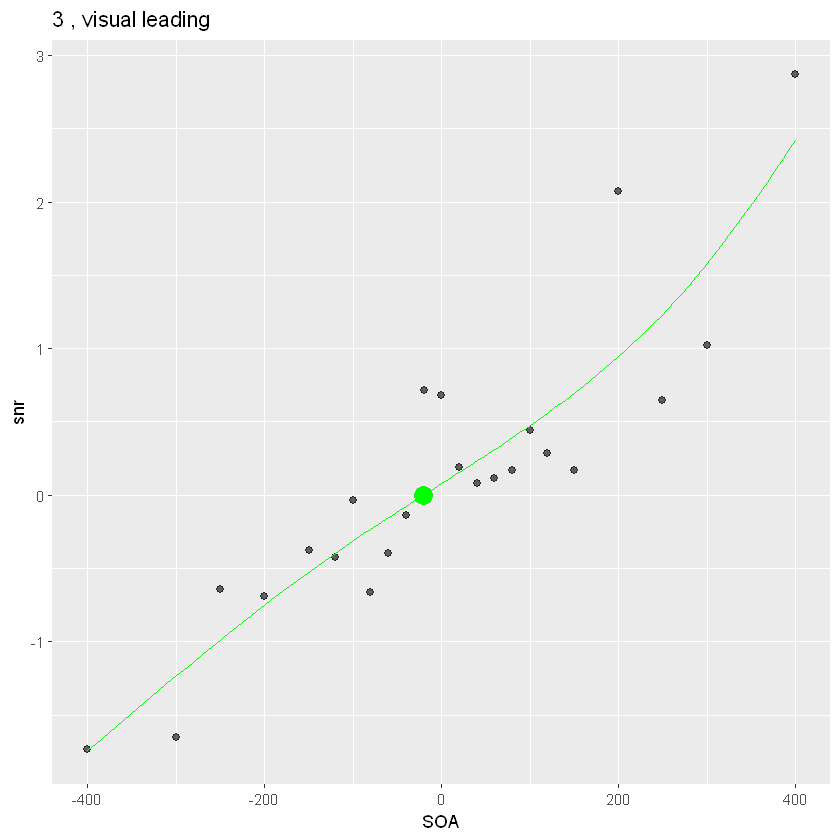

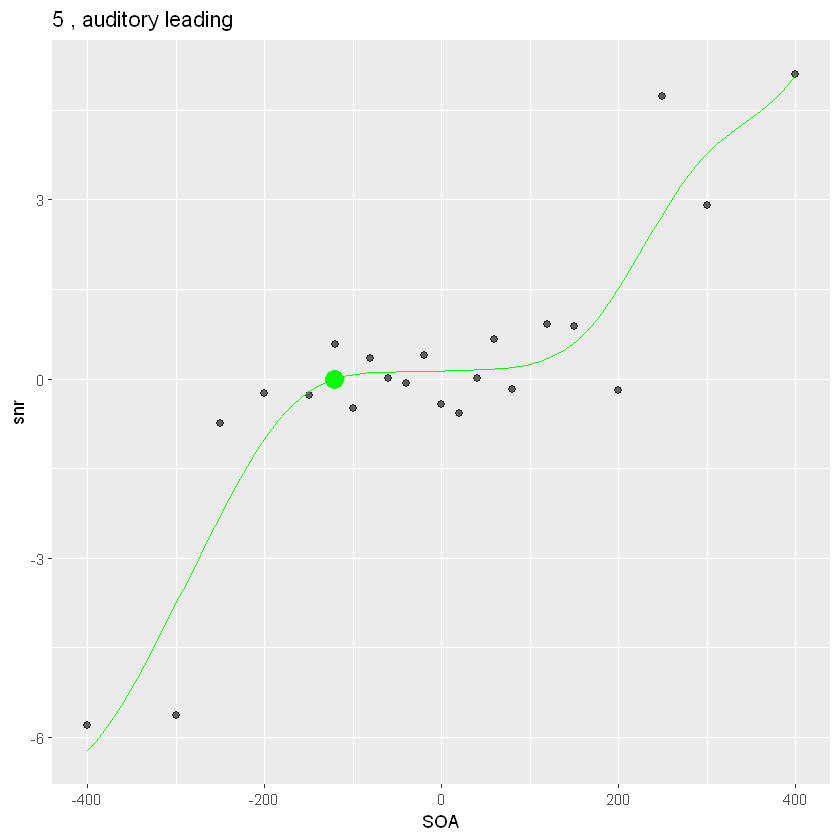

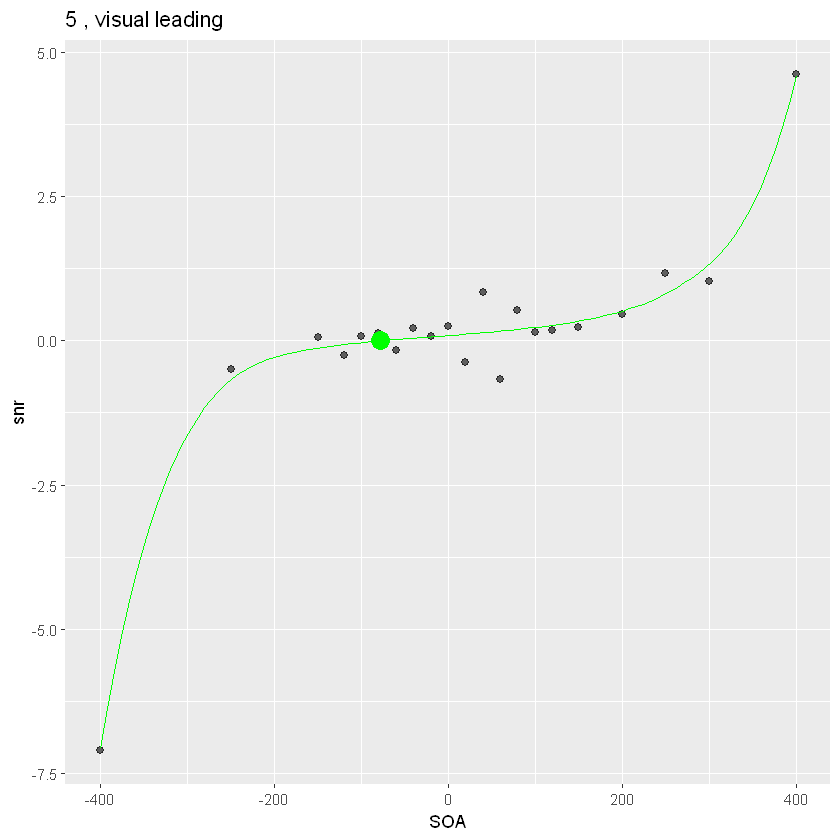

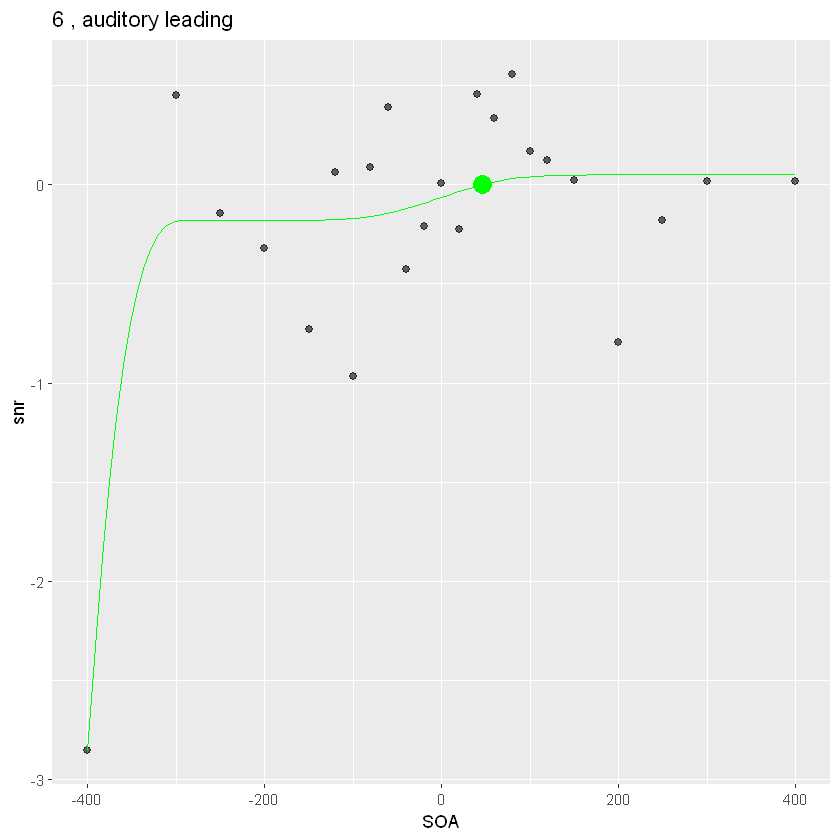

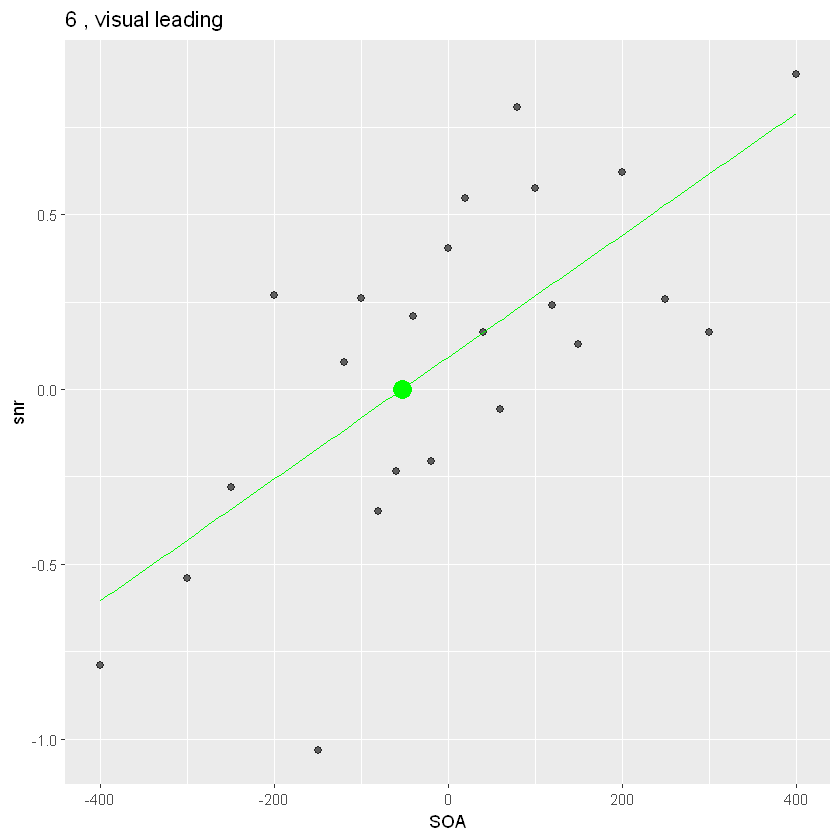

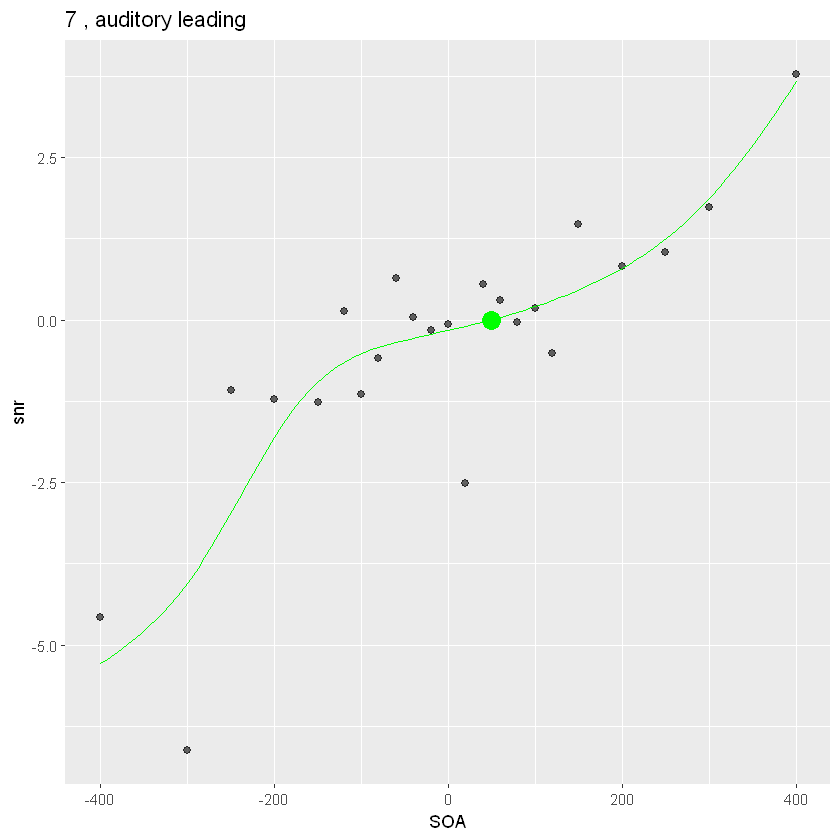

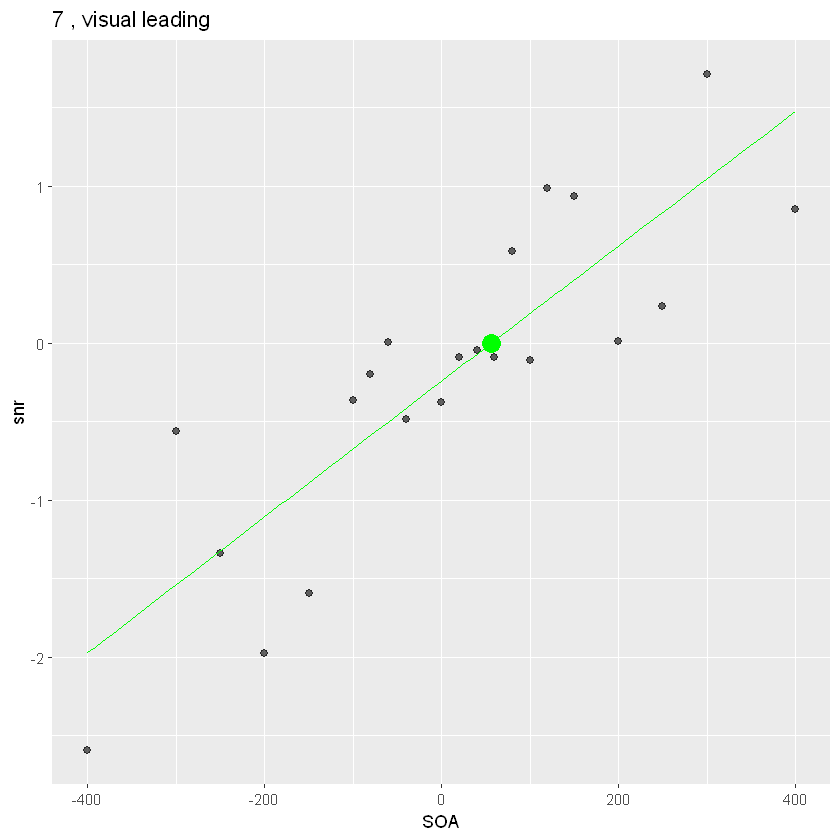

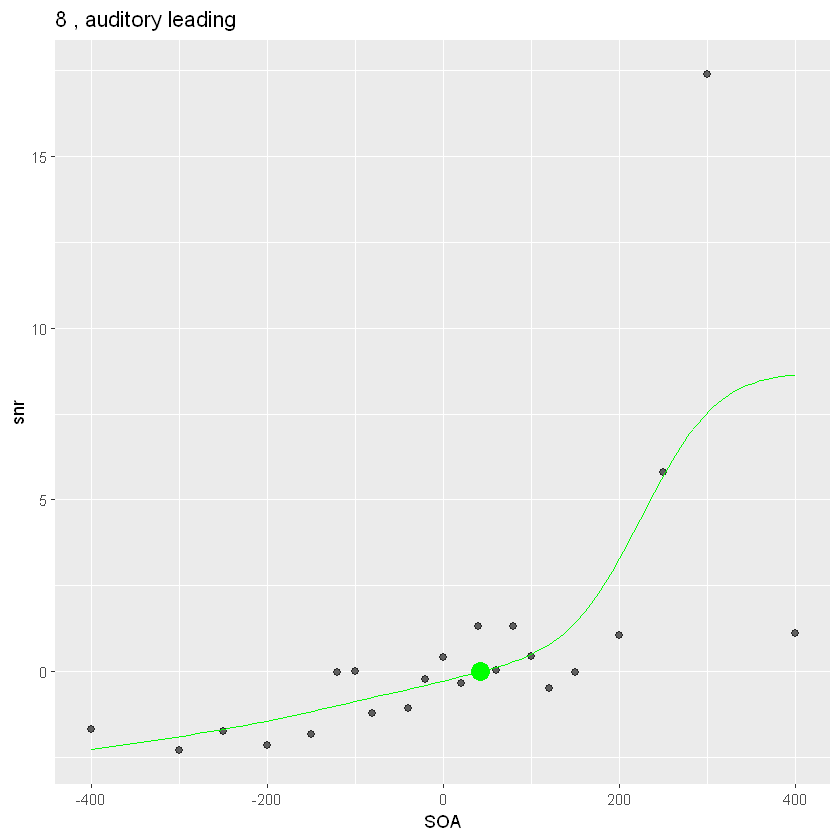

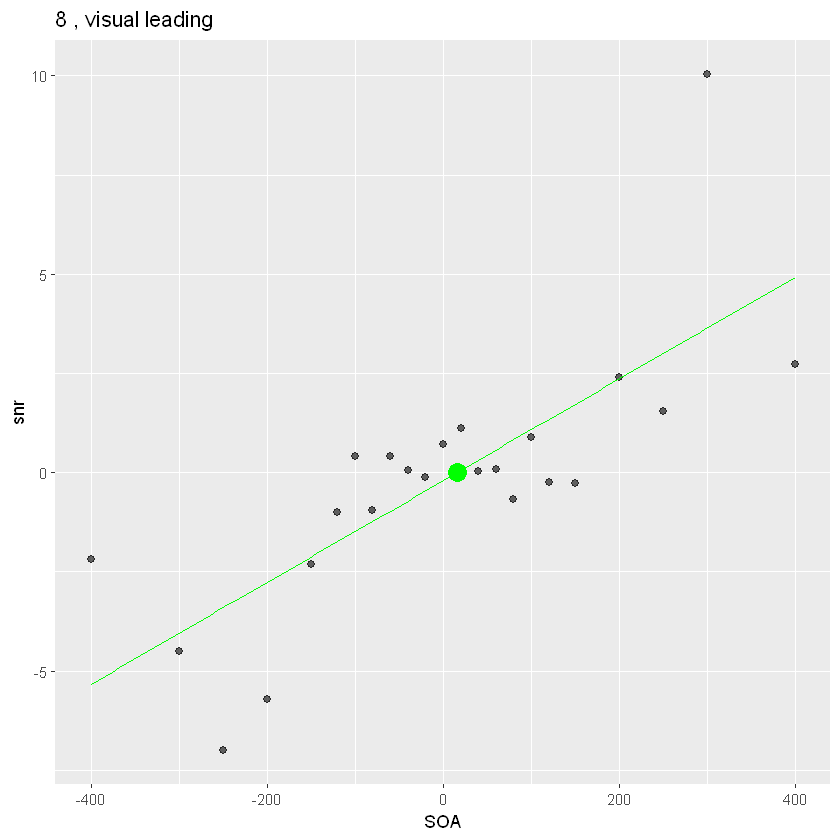

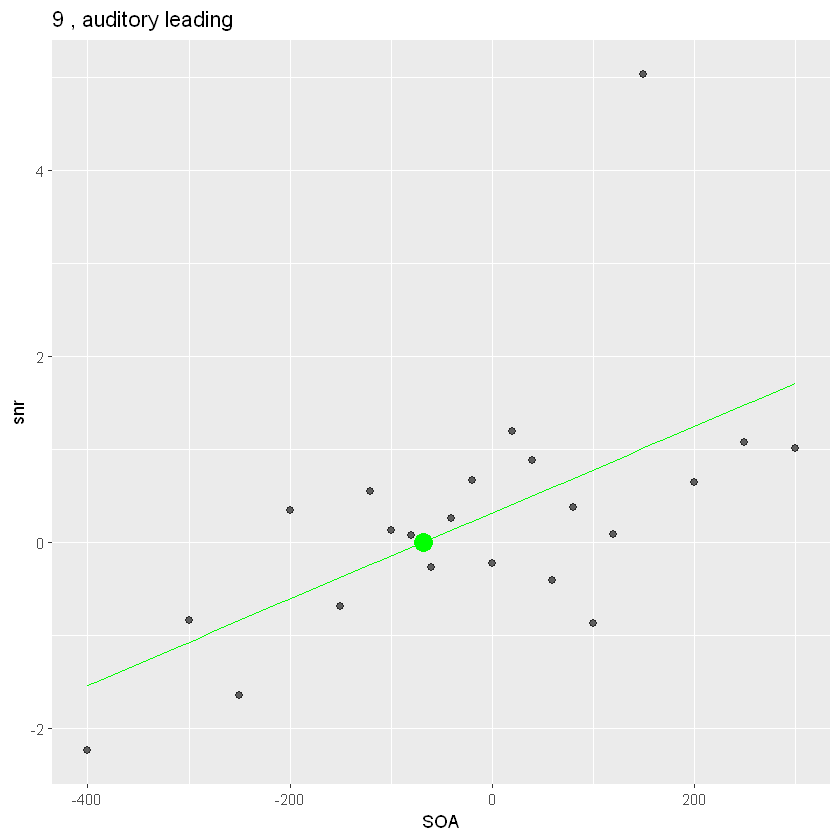

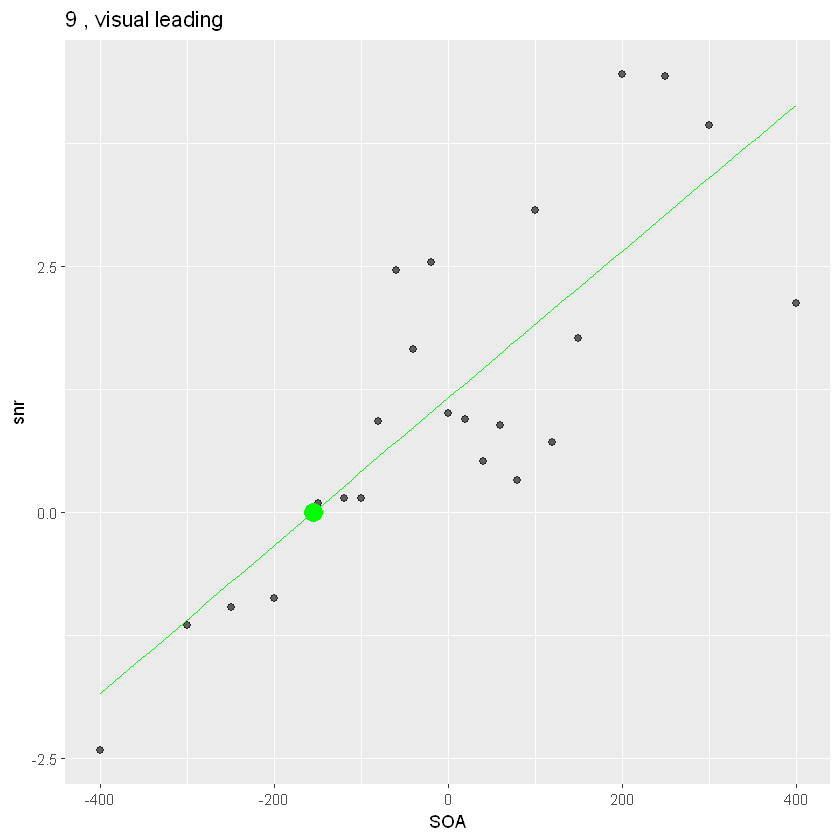

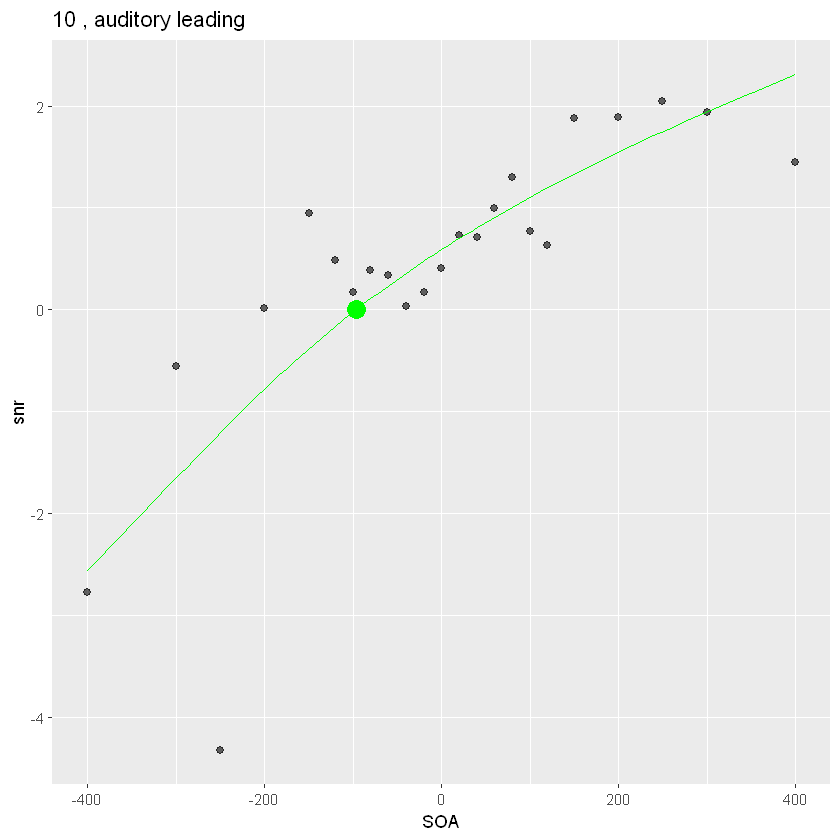

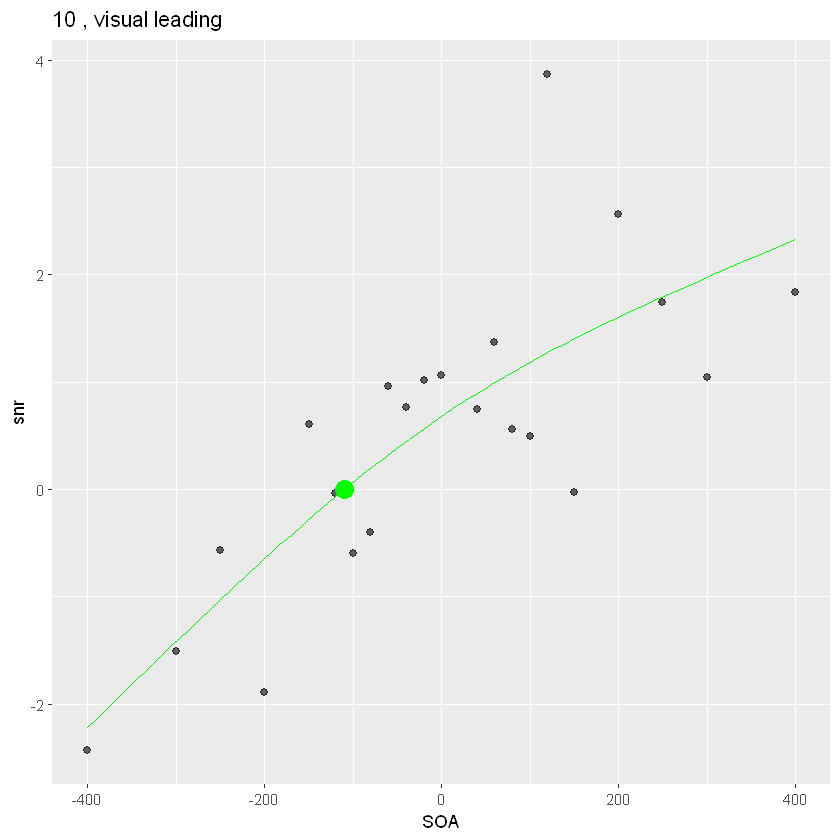

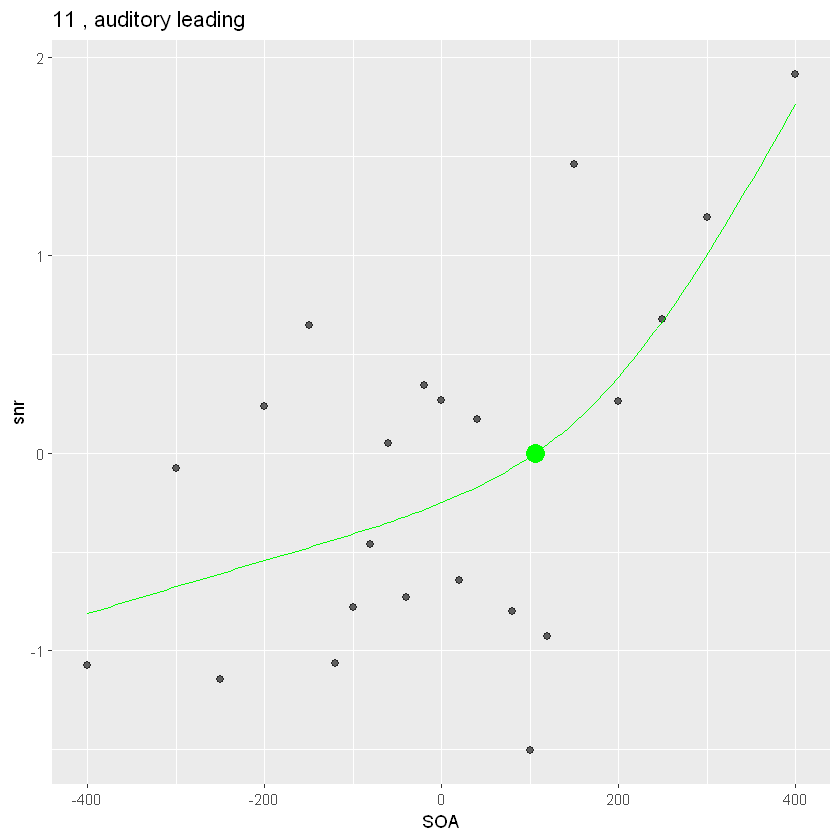

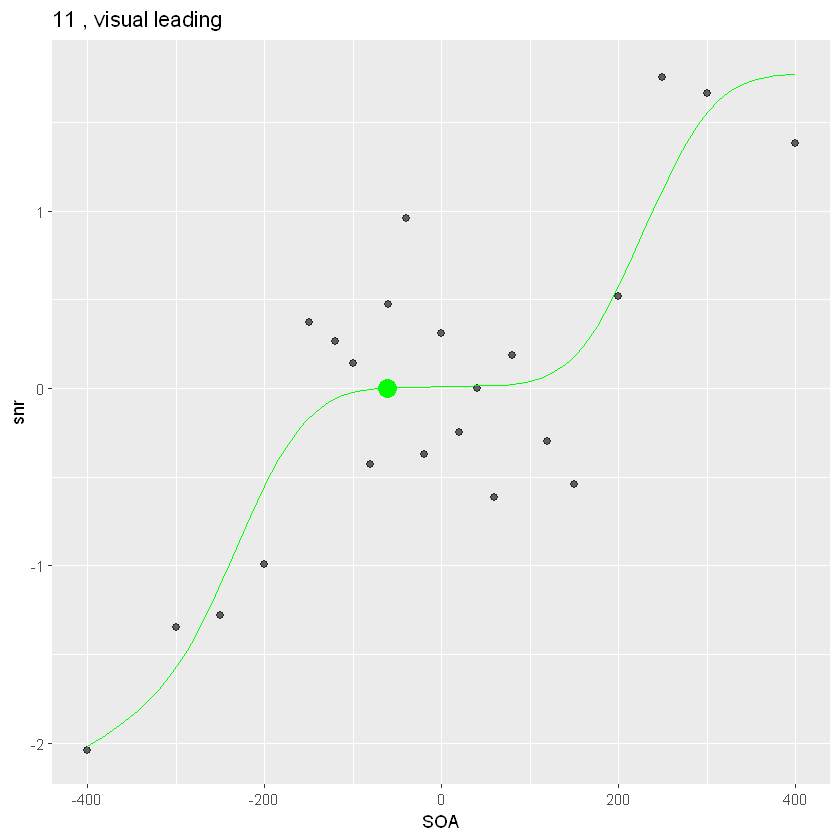

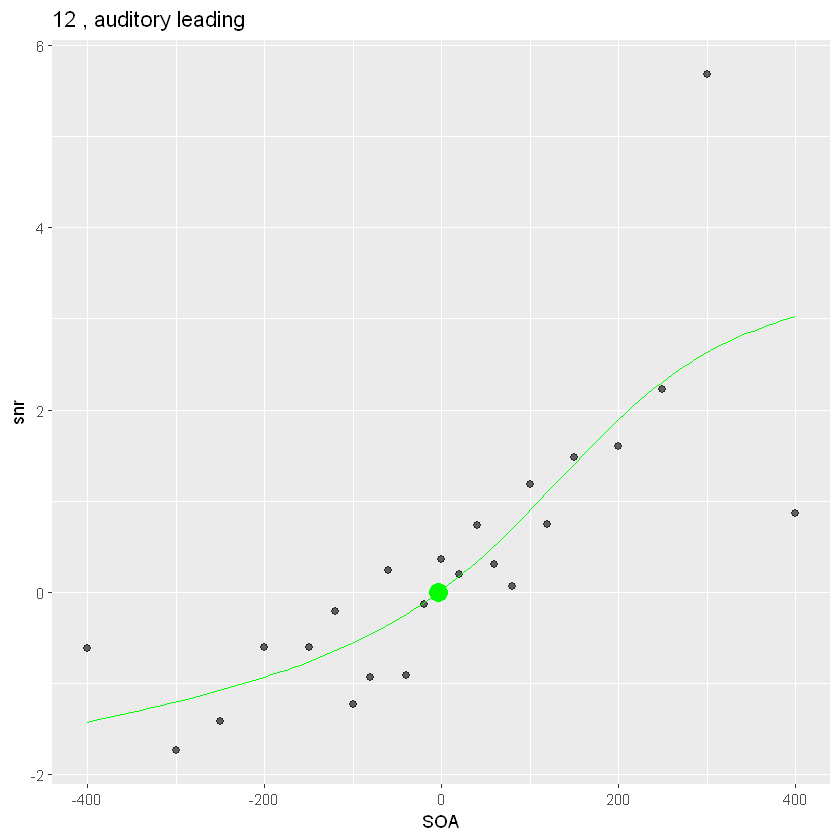

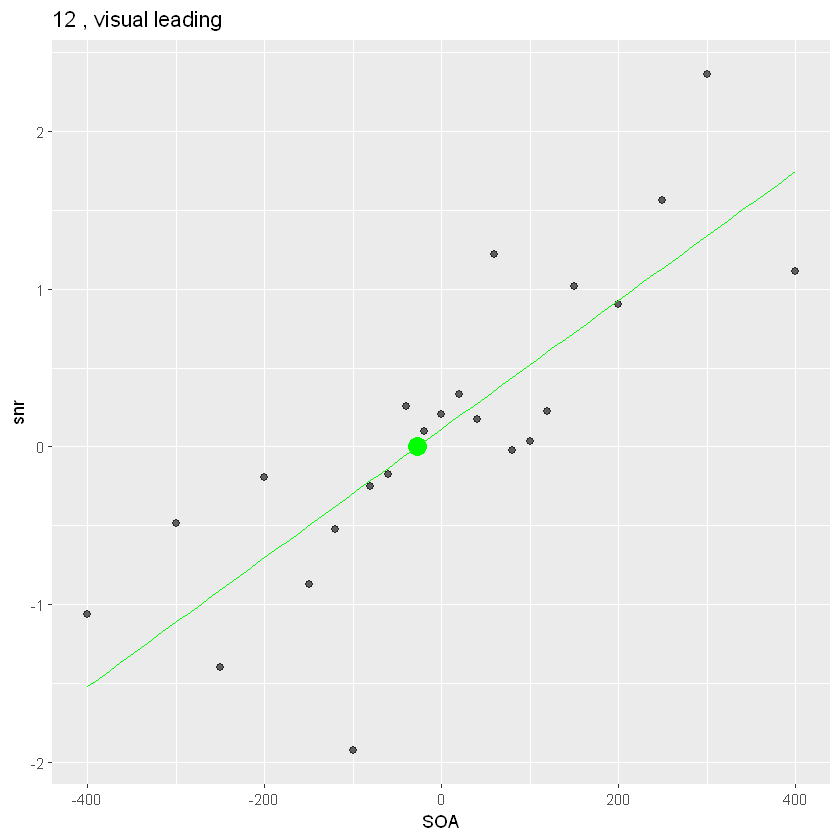

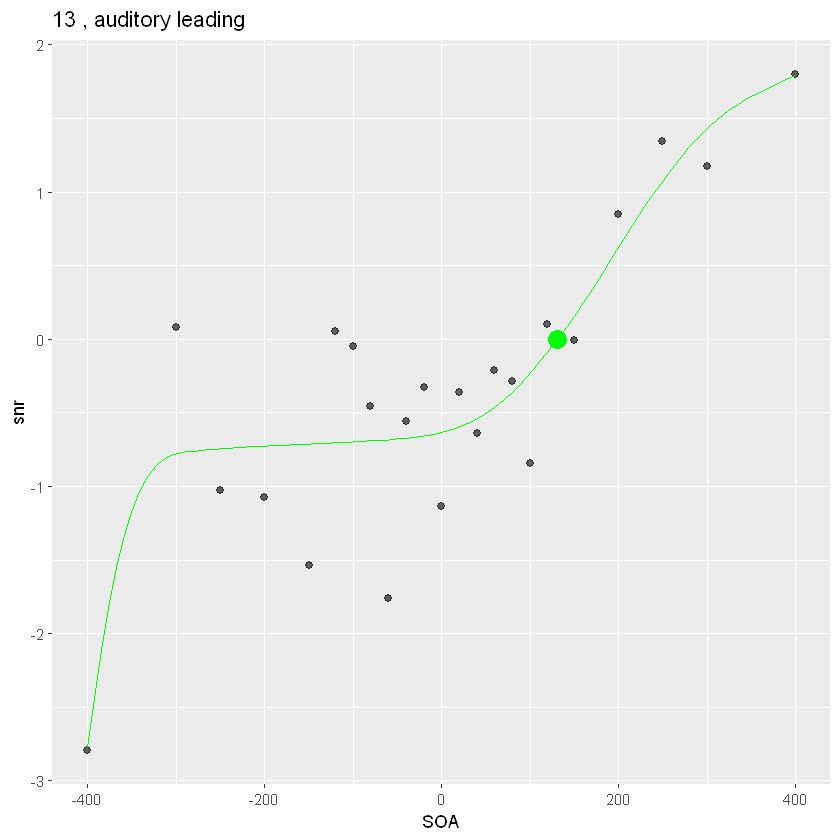

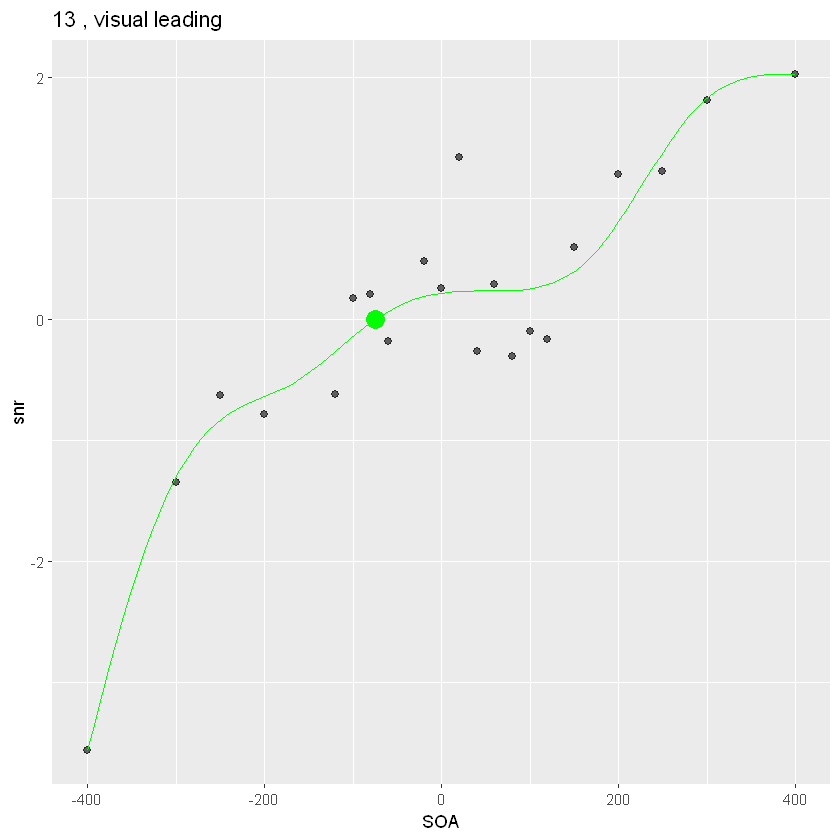

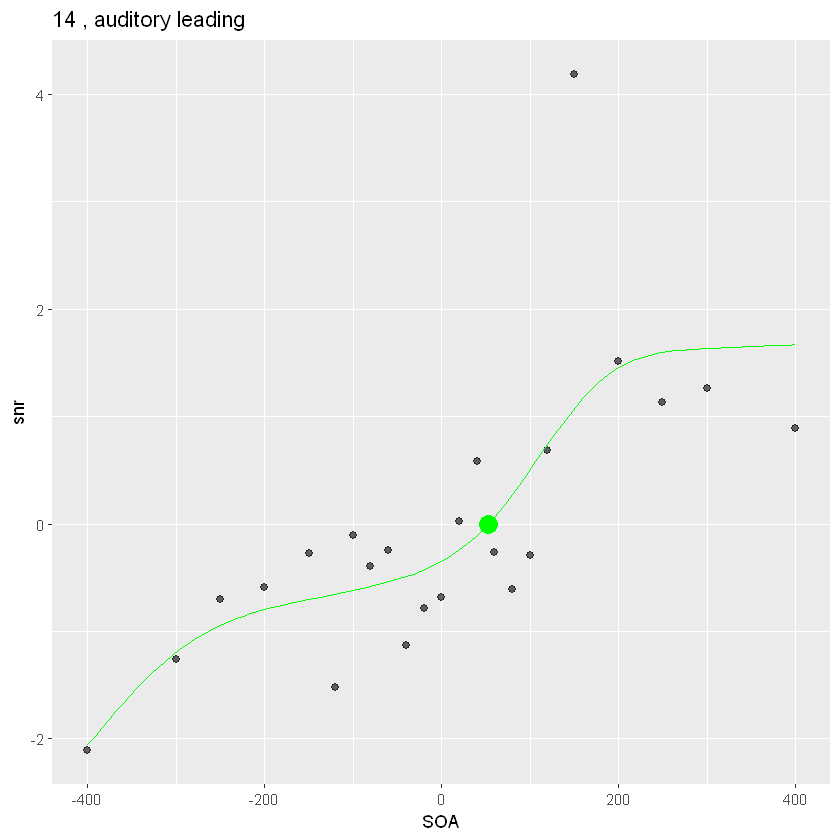

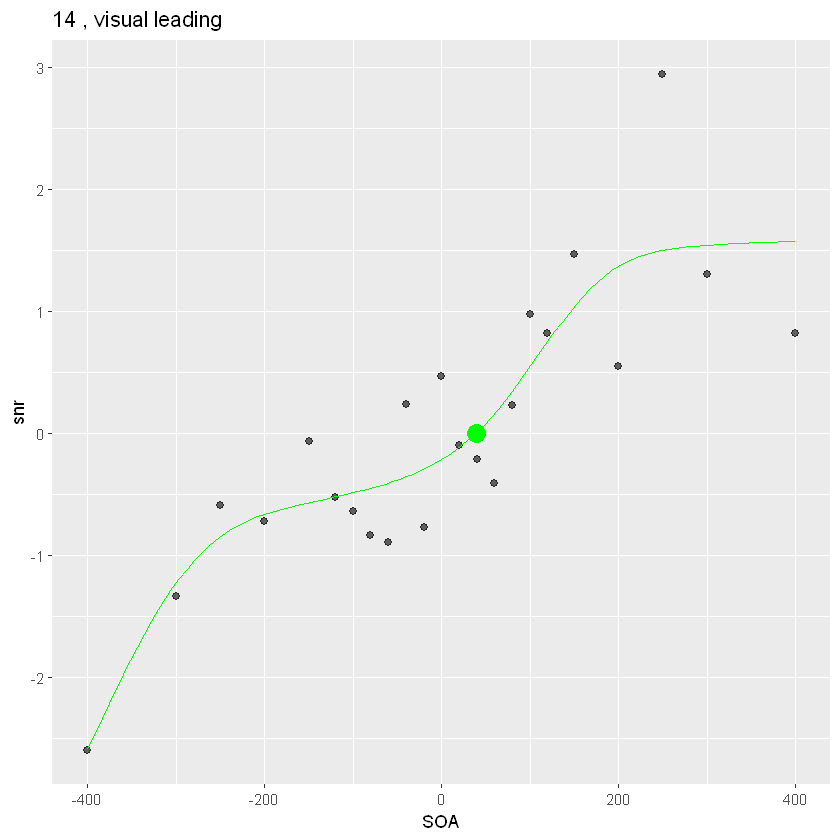

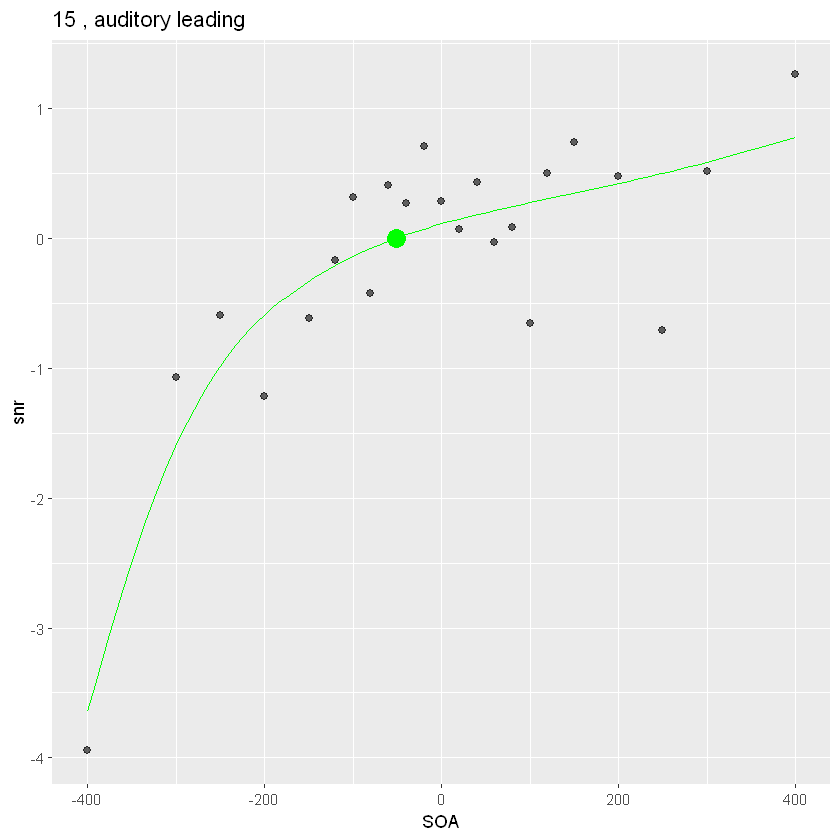

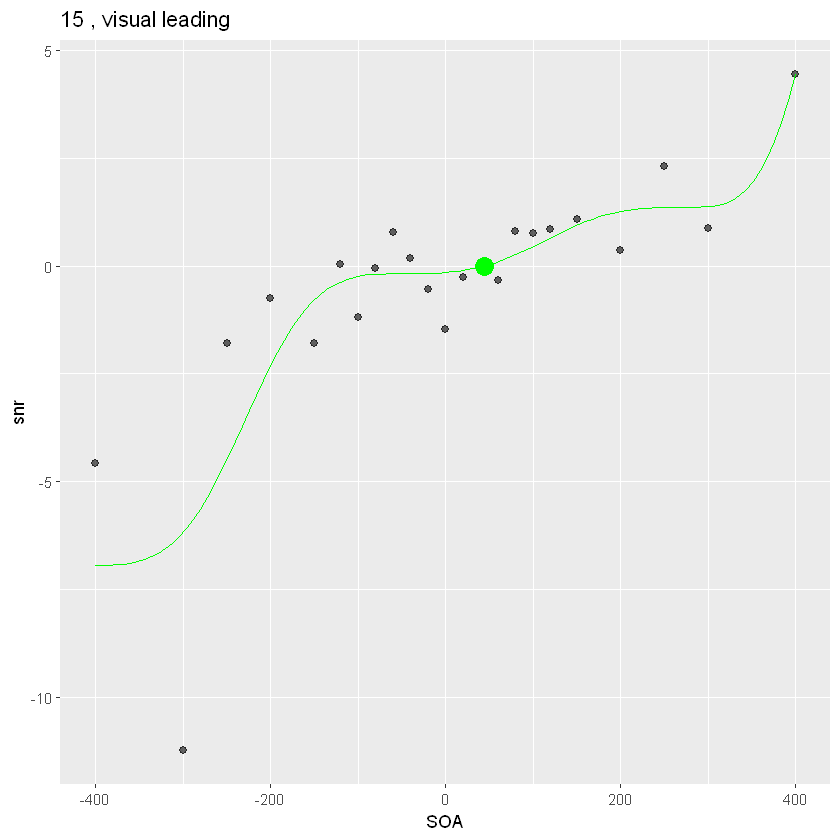

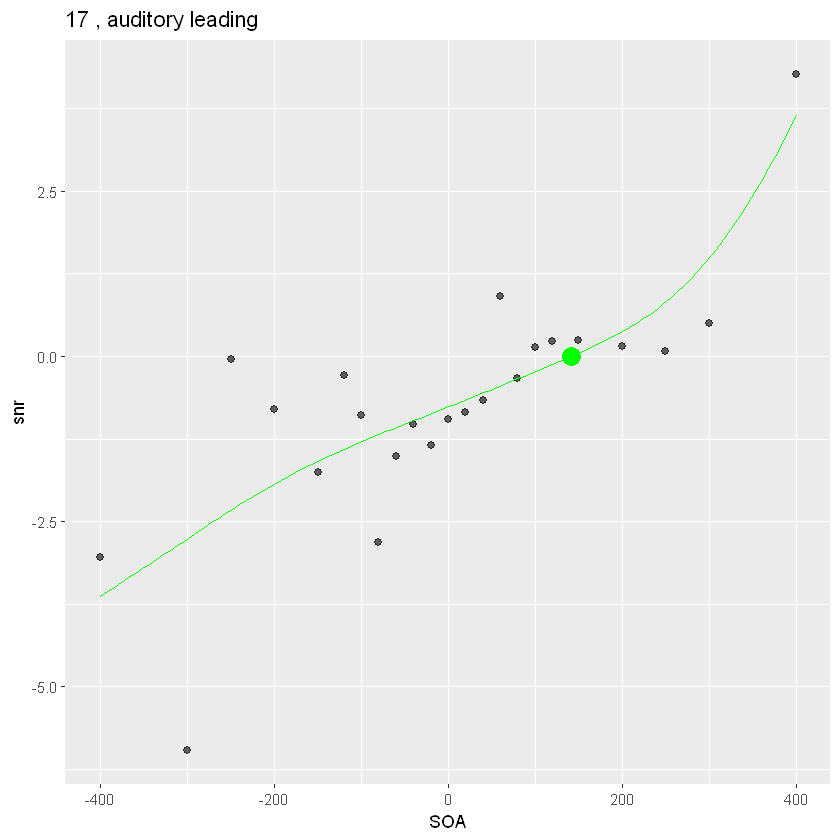

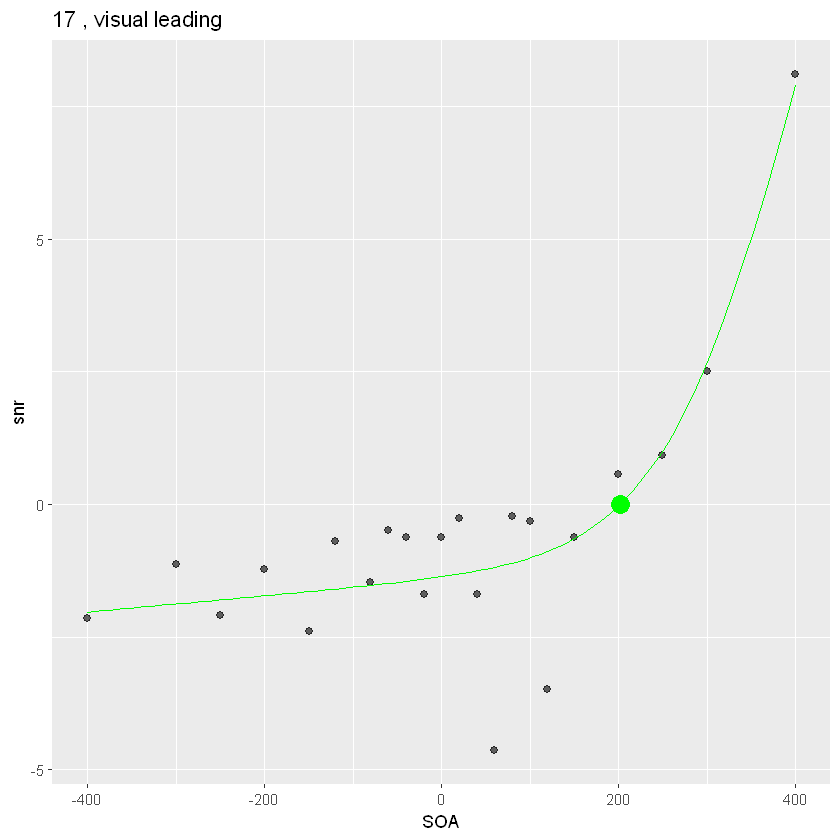

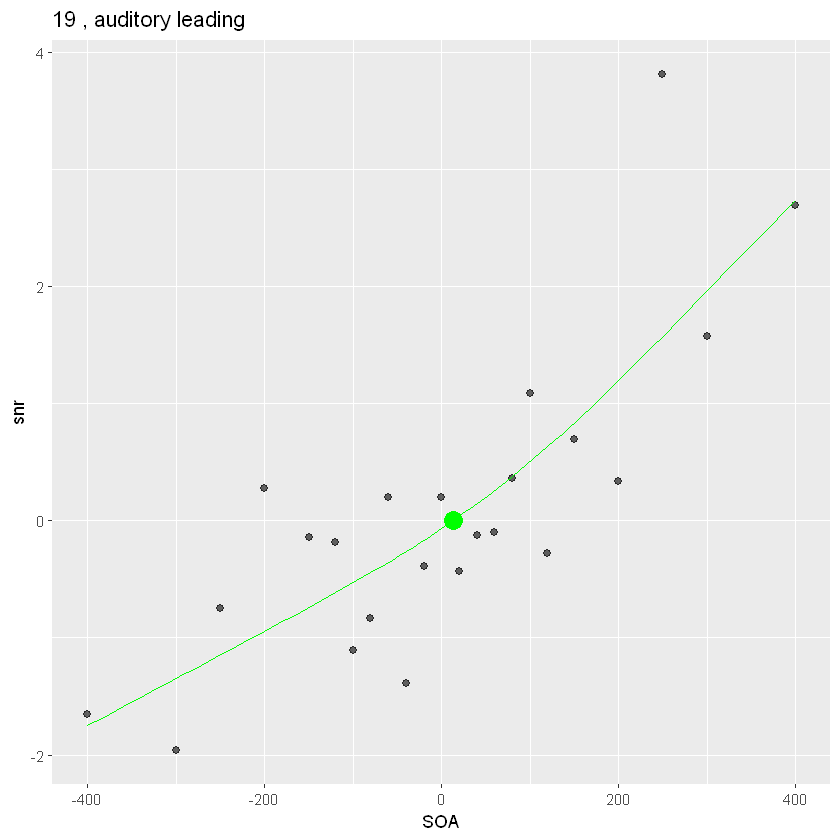

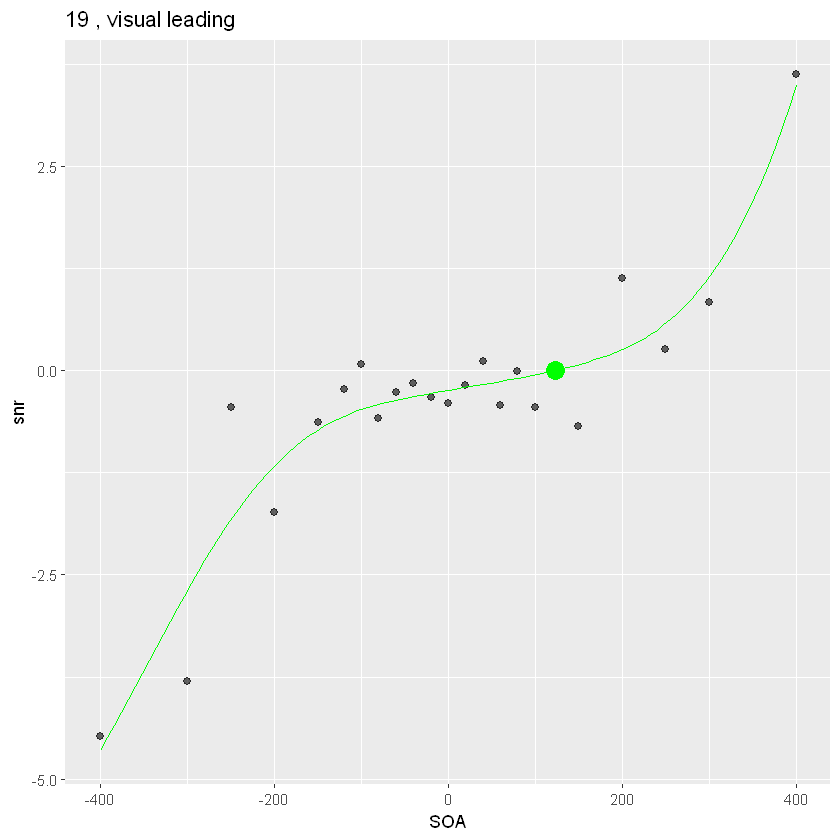

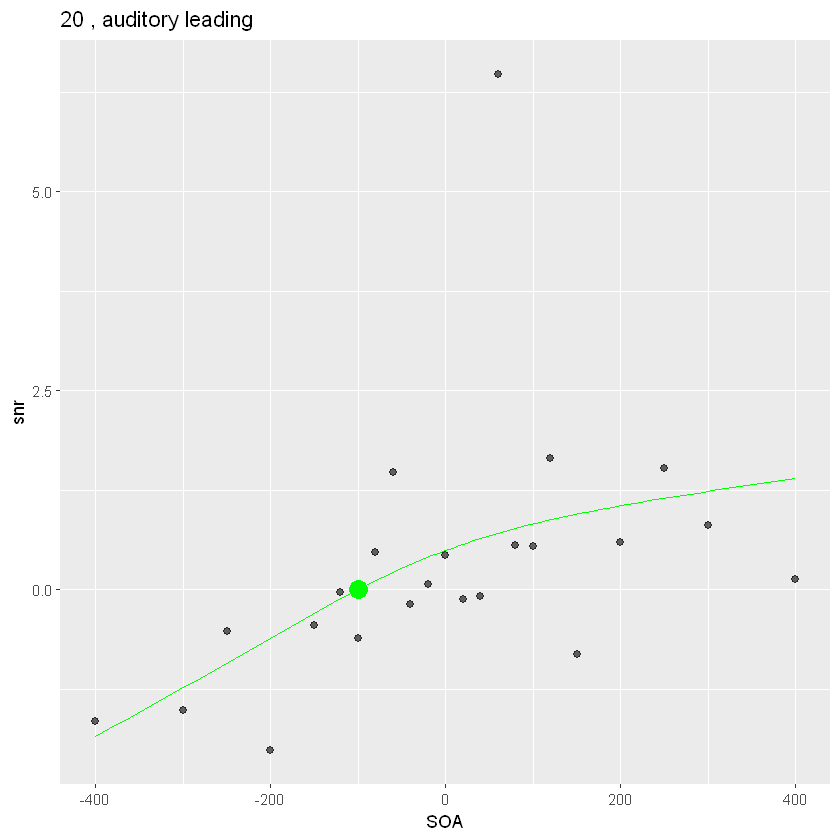

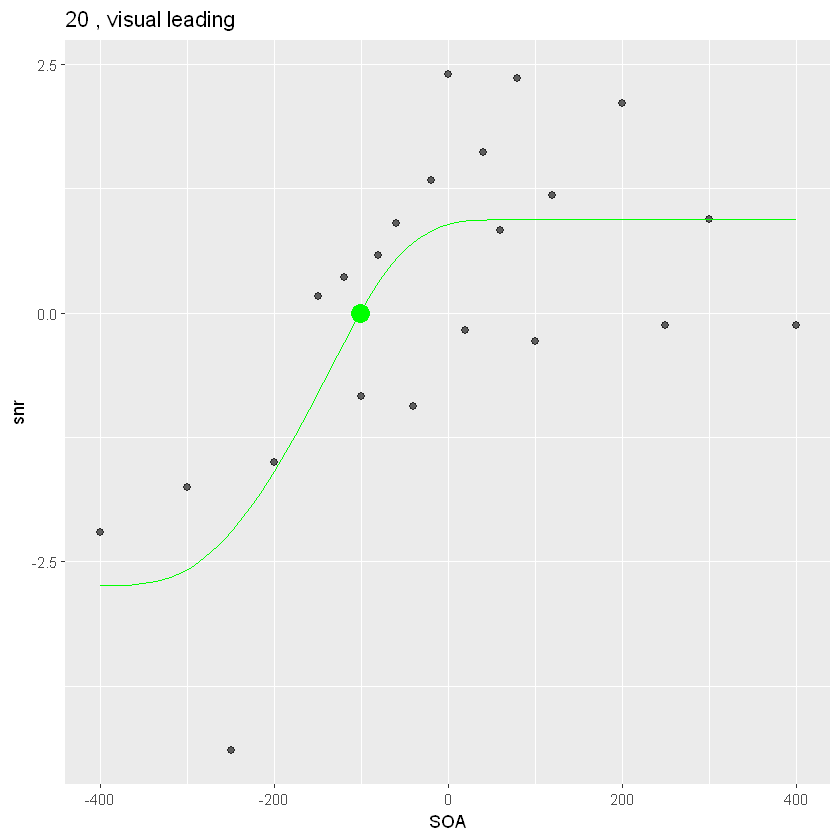

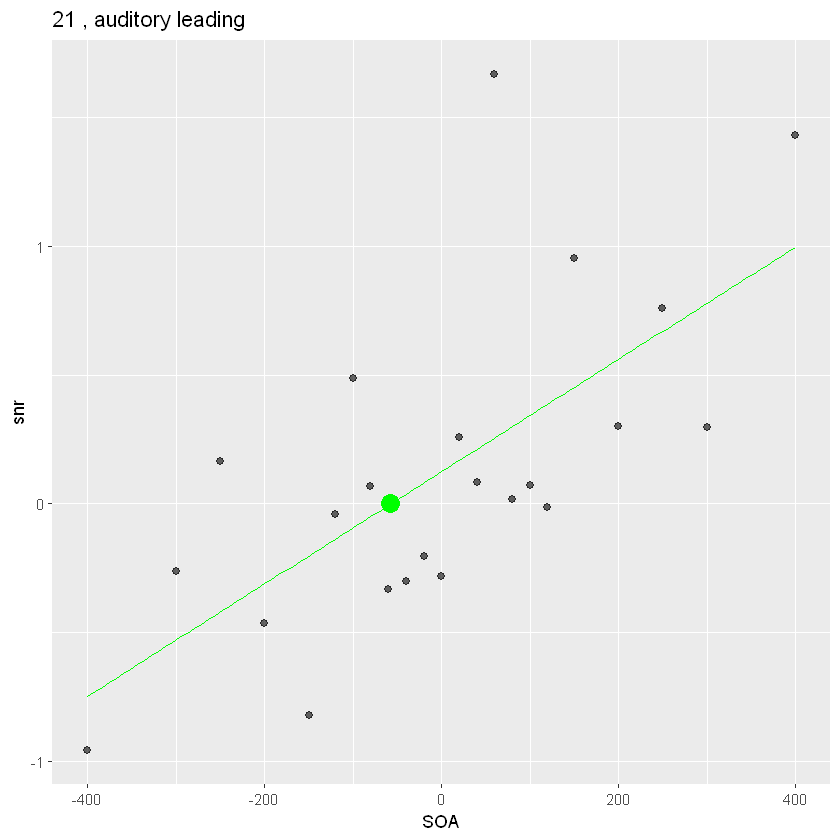

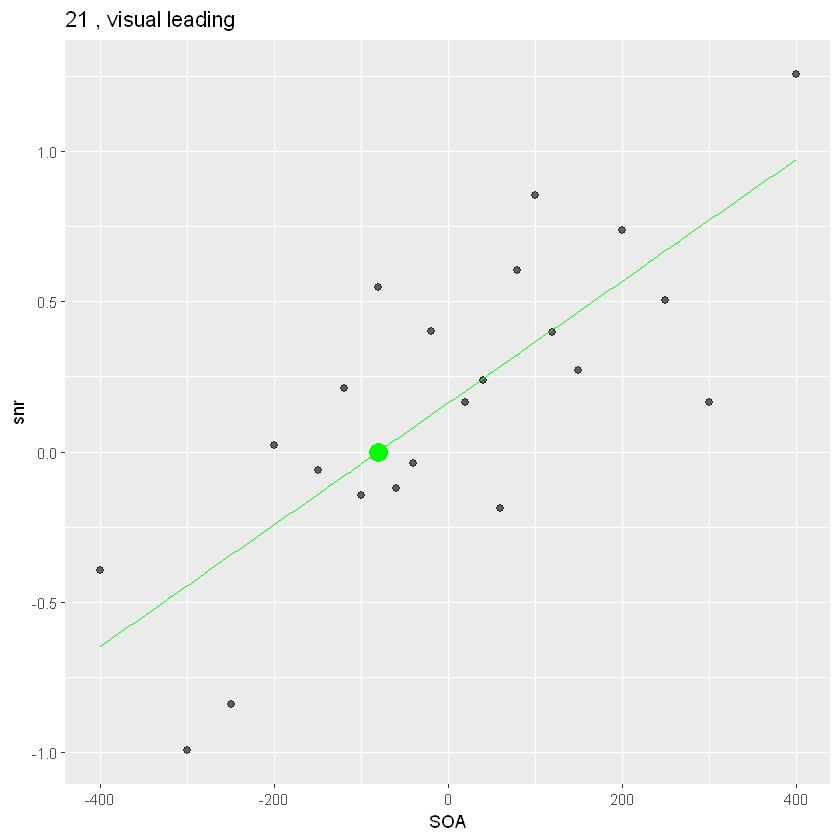

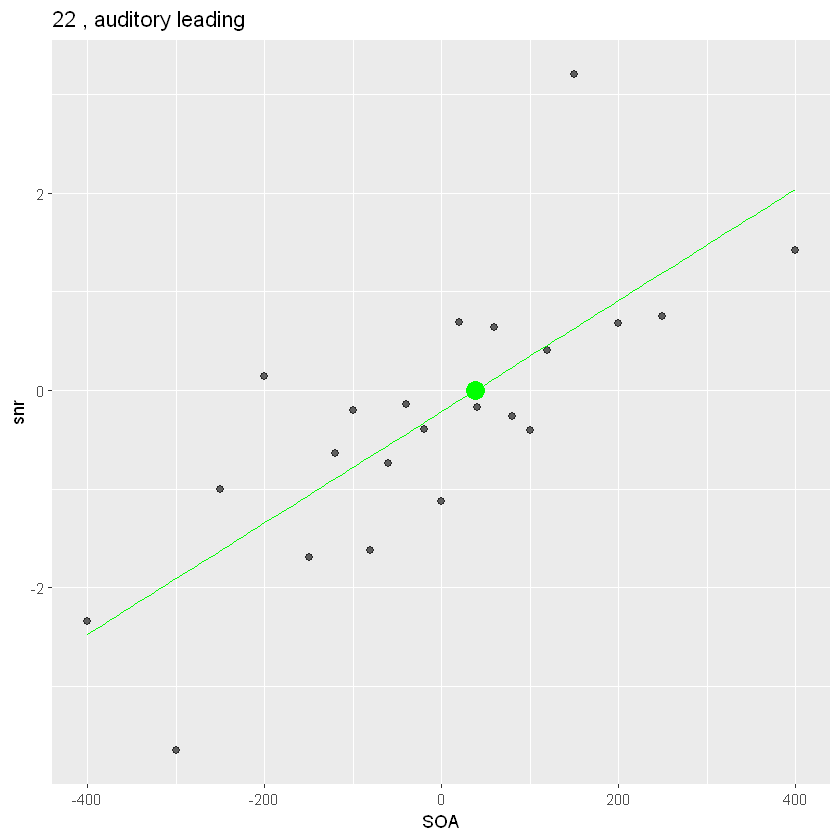

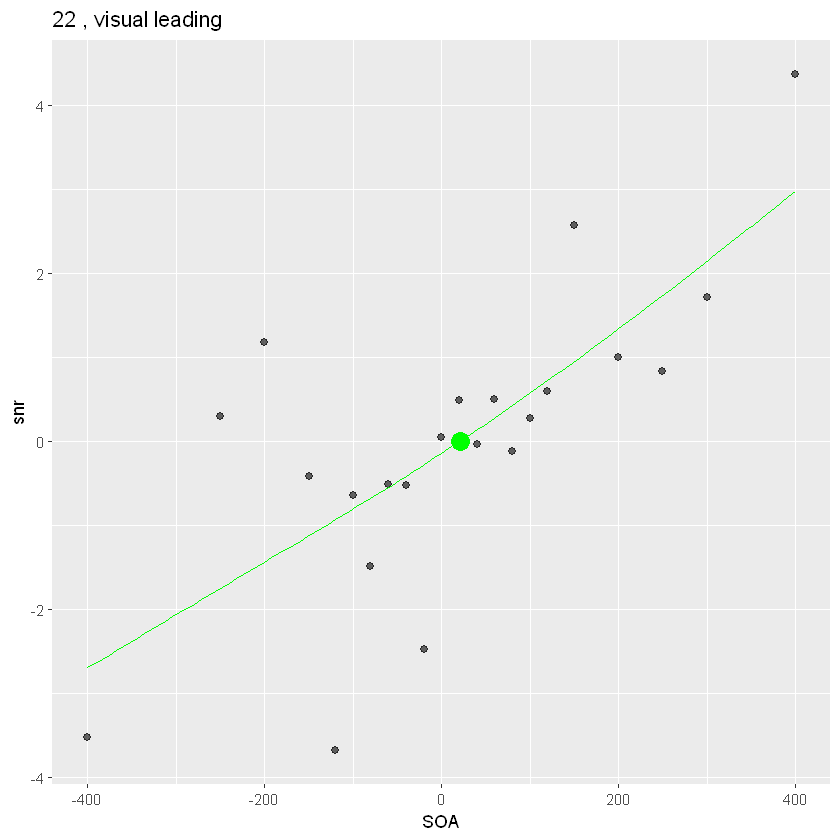

In [53]:
# ==============================================================================
# Sensory Bias Estimation for a Single Participant
#
# This script fits Shape-Constrained Additive Models (SCAM) to SNR data as a 
# function of SOA for a specific participant, split by prior stimulus conditions.
# The zero-crossing points (roots) are calculated to estimate the Point of 
# Subjective Equality (PSE) where sensory evidence is balanced.
# ==============================================================================

sigmoid_results <- data.frame()

for (participant in unique(df_stim$ID)) {
    for (condition in unique(df_stim$prior_stimulus)) {
        # print(participant)
        df_stim_subset <- df_stim %>% filter(ID == participant, prior_stimulus == condition)

        model <- scam(snr ~ s(SOA, bs = "mpi"), data = df_stim_subset)
        ff <- function(SOA) {
              predict(model, data.frame(SOA = SOA))
            }
        roots <- findZeros(ff(x)~x)
        
        print(ggplot(df_stim_subset, aes(x = SOA, y = snr)) +
              ggtitle(glue('{participant} , {condition}')) +
          geom_point(size = 2, alpha = 0.6) + 
          geom_function(fun=ff, color='green') +
          geom_point(data = data.frame(x=roots, y=0), aes(x=x,y=y),size = 5, color='green') 
             )

        sigmoid_results <- rbind(sigmoid_results, data.frame(
            ID = participant,
            prior_stimulus = condition,
            root = mean(roots$x)))
  }
}

In [54]:
write_xlsx(sigmoid_results,"files/TOJ_prior_stimulus_sensory_bias.xlsx")

In [55]:
# ---------------------------------------------------------
# Decision bias is quantified using the relative starting
# point (z/a). This parameter reflects the bias in the
# decision process toward one response boundary.
# ---------------------------------------------------------

df_summary <- df_stim %>%
  group_by(ID, prior_stimulus) %>%
  summarise(mean_Z = median(Z, na.rm = TRUE),
            .groups = "drop")

write_xlsx (df_summary,"files/TOJ_prior_stimulus_decision_bias.xlsx")

###############################################################
## 3-3 Testing change in SNR root

In [56]:
sigmoid_results <- read_xlsx("files/TOJ_prior_stimulus_sensory_bias.xlsx")

In [57]:
sigmoid_results2 <- sigmoid_results %>% group_by(ID) %>% summarise(
    diff = root[prior_stimulus == "visual leading"] - root[prior_stimulus == "auditory leading"],
    .groups = "drop"
  )
head(sigmoid_results2)

ID,diff
<dbl>,<dbl>
1,-20.5262
3,-21.9582
5,43.9156
6,-99.6892
7,7.1555
8,-26.1545


In [58]:
#summary
sigmoid_results %>% group_by(prior_stimulus) %>%  get_summary_stats(root)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory leading,root,18,-123.344,141.227,6.880,-65.453,48.507,113.961,91.139,-0.086,83.651,19.717,41.599
visual leading,root,18,-155.265,201.858,-40.442,-79.924,34.433,114.357,90.553,-22.525,93.059,21.934,46.277


In [59]:
sigmoid_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-205.366,110.436,-19.004,-25.732,5.002,30.735,32.399,-22.439,80.166,18.895,39.865


In [60]:
#identify outlier
dd <- sigmoid_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>
6,-99.6892,TRUE,FALSE
9,-87.1550,TRUE,FALSE
11,-167.5566,TRUE,TRUE
13,-205.3657,TRUE,TRUE
15,96.2950,TRUE,FALSE
17,60.6303,TRUE,FALSE
19,110.4364,TRUE,TRUE


In [61]:
#Removing outliers data
sigmoid_results <- sigmoid_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
sigmoid_results2 <- sigmoid_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [62]:
# normality
sigmoid_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9092738,0.131982


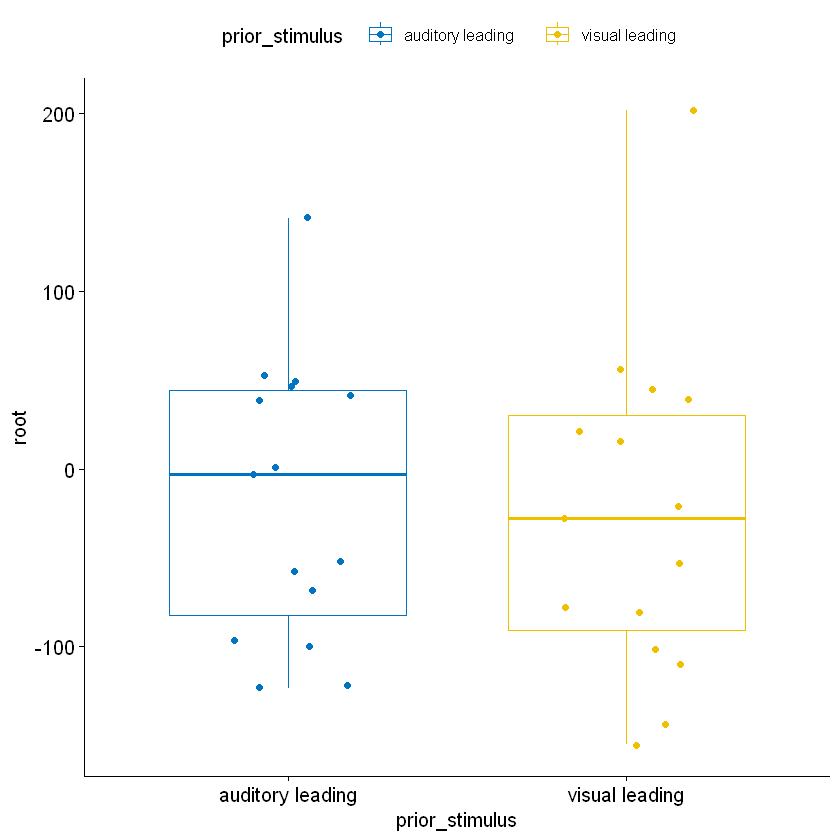

In [63]:
#plot
ggboxplot(
  sigmoid_results, x = "prior_stimulus", y = "root",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

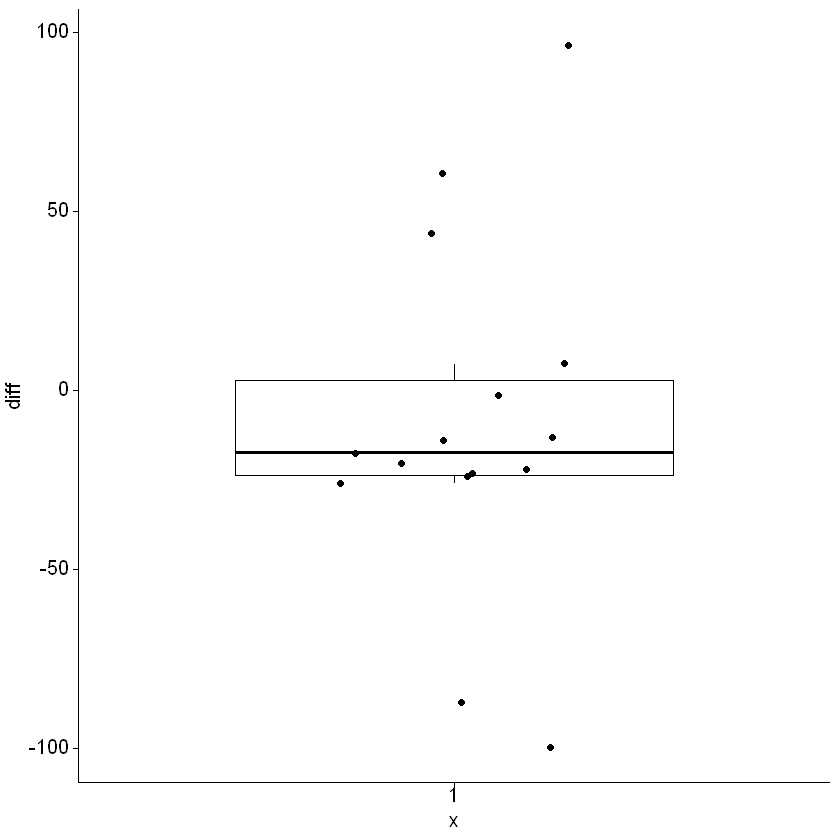

In [64]:
ggboxplot(
  sigmoid_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [65]:
sigmoid_results %>% t_test(root ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,9.427807,root,auditory leading,visual leading,15,15,0.7351788,0.474,14,-18.07657,36.93218,T-test,two.sided


In [66]:
sigmoid_results %>% cohens_d(root ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,root,auditory leading,visual leading,0.1898223,15,15,negligible


###############################################################
## 3-4 Testing change in relative starting point

In [67]:
df_summary <- read_xlsx("files/TOJ_prior_stimulus_decision_bias.xlsx")

In [68]:
df_summary2 <- df_summary %>% group_by(ID) %>% summarise(
    diff = mean_Z[prior_stimulus == "visual leading"] - mean_Z[prior_stimulus == "auditory leading"],
    .groups = "drop"
  )
head(df_summary2)

ID,diff
<dbl>,<dbl>
1,-0.001716022
3,-0.142536570
5,0.023032720
6,-0.073289279
7,0.147957689
8,0.010253138


In [69]:
df_summary %>% group_by(prior_stimulus) %>%  get_summary_stats(mean_Z)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory leading,mean_Z,18,-0.375,0.434,0.054,-0.064,0.199,0.263,0.191,0.052,0.216,0.051,0.108
visual leading,mean_Z,18,-0.293,0.443,0.167,0.031,0.319,0.288,0.223,0.146,0.210,0.049,0.104


In [70]:
df_summary2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-0.145,0.438,0.025,-0.03,0.209,0.239,0.165,0.095,0.188,0.044,0.094


In [71]:
#identify outlier
dd <- df_summary2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [72]:
#Removing outliers data
df_summary <- df_summary %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
df_summary2 <- df_summary2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [73]:
# normality
df_summary2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9123791,0.09476506


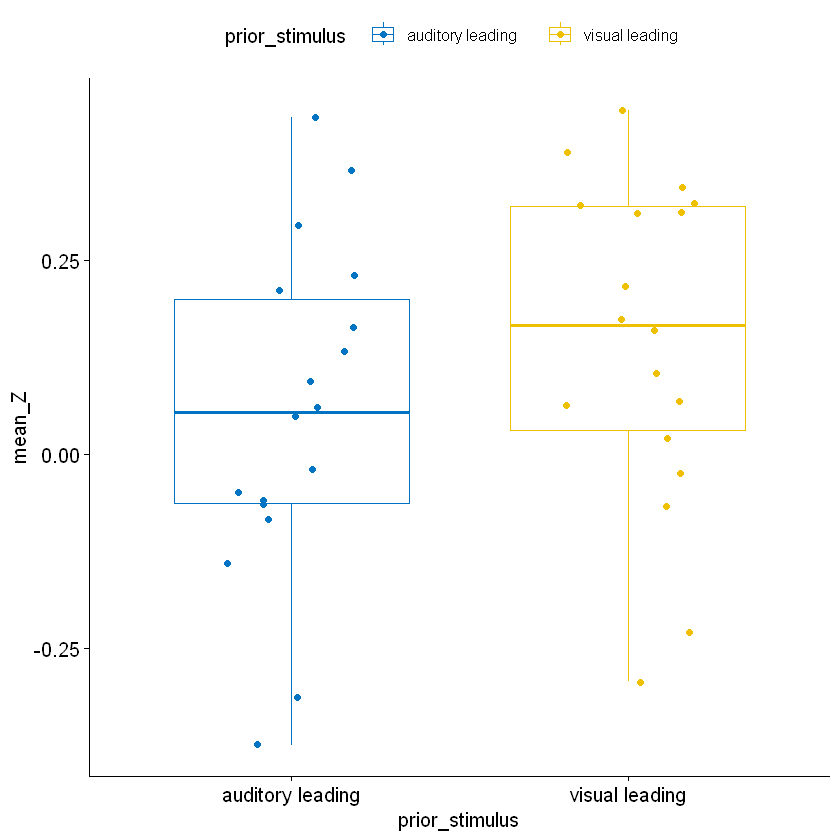

In [74]:
#plot
ggboxplot(
  df_summary, x = "prior_stimulus", y = "mean_Z",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

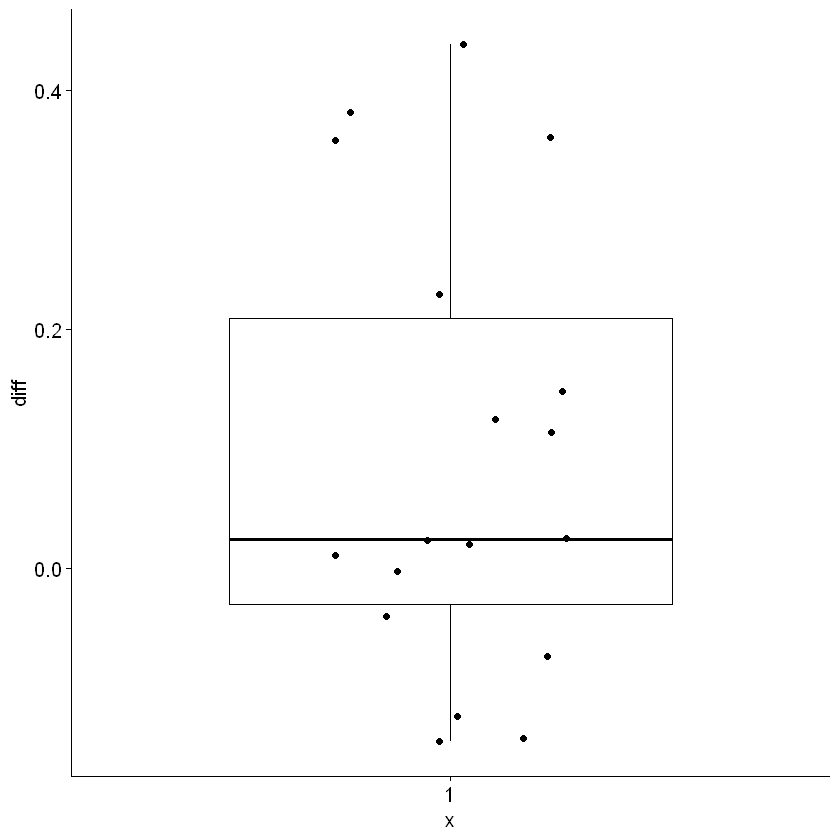

In [75]:
ggboxplot(
  df_summary2, y = "diff", palette = "jco", add = "jitter"
  )

In [76]:
df_summary %>% t_test(mean_Z ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-0.09480229,mean_Z,auditory leading,visual leading,18,18,-2.139113,0.0472,17,-0.1883062,-0.001298414,T-test,two.sided


In [77]:
df_summary %>% cohens_d(mean_Z ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,mean_Z,auditory leading,visual leading,-0.5041937,18,18,moderate


###############################################################\
###############################################################
# 4- Plot statistical results

In [80]:
ddm_drift_zero_TOJ_pre_stim <- read_excel("files/TOJ_prior_stimulus_sensory_bias.xlsx")
ddm_drift_zero_TOJ_pre_resp <- read_excel("files/TOJ_prior_response_sensory_bias.xlsx")
ddm_bias_TOJ_pre_resp<- read_excel("files/TOJ_prior_response_decision_bias.xlsx")
ddm_bias_TOJ_pre_stim<- read_excel("files/TOJ_prior_stimulus_decision_bias.xlsx")

In [81]:
combined_df_TOJ_pre_stim <- ddm_drift_zero_TOJ_pre_stim %>%
  full_join(ddm_bias_TOJ_pre_stim, by = c("ID", "prior_stimulus"))

combined_df_pre_resp_TOJ <- ddm_drift_zero_TOJ_pre_resp %>%
  full_join(ddm_bias_TOJ_pre_resp, by = c("ID", "prior_response"))

In [87]:
stimulus_long <- combined_df_TOJ_pre_stim %>%
  pivot_longer(cols = c(mean_Z,root), names_to = "parameter", values_to = "value") %>%
  mutate(
    trial_leading = "prior_stimulus", 
    type = prior_stimulus        
  ) %>%
  select(ID, trial_leading, type, parameter, value)

response_long <- combined_df_pre_resp_TOJ %>%
  pivot_longer(cols = c(mean_Z, root), names_to = "parameter", values_to = "value") %>%
  mutate(
    trial_leading = "prior_response",
    type = prior_response        
  ) %>%
  select(ID, trial_leading, type, parameter, value)

In [88]:
combined_results <- bind_rows(stimulus_long, response_long) %>%
  arrange(ID, trial_leading, type, parameter)

In [89]:
combined_results <- combined_results %>%
  filter(!(ID == "11" & trial_leading == "prior_stimulus" & parameter == "root"))%>%
  filter(!(ID == "13" & trial_leading == "prior_stimulus"& parameter == "root"))%>%
  filter(!(ID == "19" & trial_leading == "prior_stimulus"& parameter == "root"))

In [93]:
combined_results <- combined_results %>%
  mutate(trial_leading = recode(trial_leading,
    "prior_stimulus" = "Prior stimulus",
    "prior_response" = "Prior response"))

combined_results <- combined_results %>%
  mutate(parameter = recode(parameter,
    "mean_Z" = "Decisional~Bias~(DB)",
    "root" = "Sensory~Bias~(SB)"))

In [94]:
d <- combined_results %>% group_by(trial_leading,parameter,type) %>% summarise(mean=mean(value), sd=sd(value)/sqrt(n())) %>% ungroup()

`summarise()` has grouped output by 'trial_leading', 'parameter'. You can override using the `.groups` argument.


In [95]:
stat_test <- combined_results %>%
  group_by(trial_leading, parameter) %>%
  # Explicitly call t_test from rstatix
  rstatix::t_test(value ~ type, paired = TRUE) %>%
  rstatix::add_significance()

In [96]:
stat_test <- stat_test %>%
  add_xy_position(x = "trial_leading", dodge = 0.8)

In [97]:
stat_test[1,'y.position'] <- 0.6
stat_test[3,'y.position'] <- 0.6
stat_test[2,'y.position'] <- 300
stat_test[4,'y.position'] <- 300

Warning message in geom_errorbar(data = d, aes(group = type, fill = c(), y = c(), :
"Ignoring unknown aesthetics: fill"


png 
  2

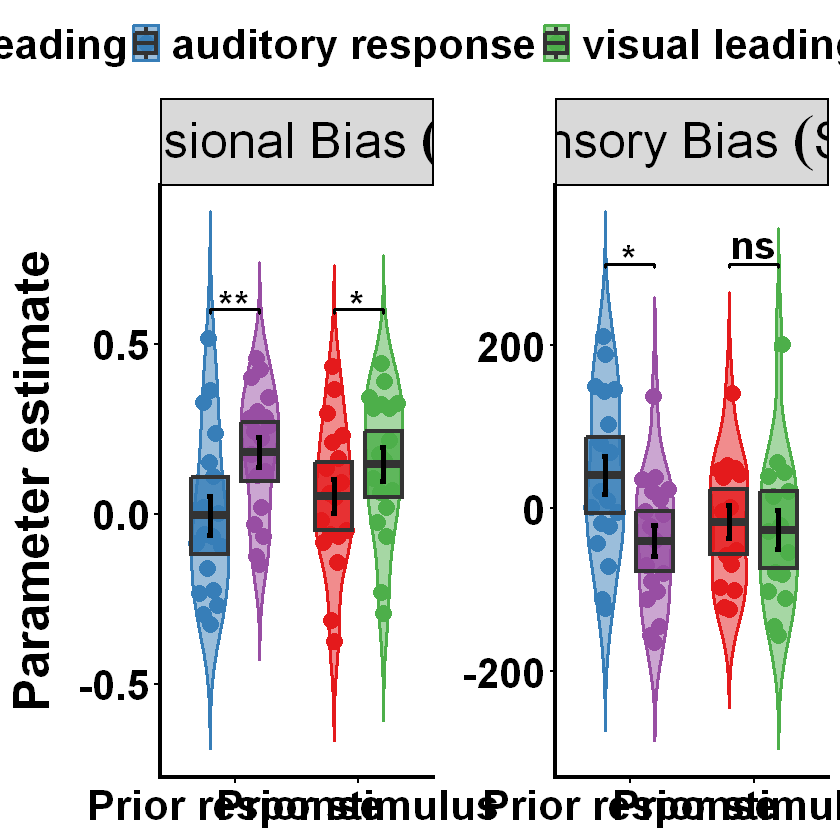

In [100]:
pdf(file="figures/TOJ_DDM_params.pdf", width = 15, height = 8)

p <- ggplot(data=combined_results, mapping=aes(x=trial_leading, y=value)) +
    # Increased linewidth to 1 and alpha to 0.5 for a bolder, more vivid violin look
    geom_violin(trim = FALSE, alpha=.5, width=.6, scale='width', position=position_dodge(.8), aes(colour=type, fill = type), linewidth=1) +
    # Increased alpha to 1 and stroke to 1.2 so individual points stand out sharply
    geom_quasirandom(dodge.width=.8, aes(colour=type), width=.13, shape=16, stroke=1.2, size=4, alpha=1) +
    # Increased boxplot linewidth to 1.2 for better visibility inside the violin
    geom_boxplot(alpha=.8, data=d, aes(y=c(), ymin=mean-sd*1.96, lower=mean-sd*1.96, middle=mean, upper=mean+sd*1.96, ymax=mean+sd*1.96, fill=type),
                 stat = "identity", position=position_dodge(.8), width=0.6, linewidth = 1.2) +
    # Increased errorbar linewidth to 1.5 to make the SD bounds extra bold
    geom_errorbar(data=d, aes(group=type, fill=c(), y=c(), ymin=mean-sd, ymax=mean+sd), position=position_dodge(.8), width=.1, linewidth=1.5) +
    # Significance bars kept bold as originally specified
    stat_pvalue_manual(stat_test, label = "p.adj.signif", tip.length = 0.01, size = 8.5, bracket.size = 1.1, fontface = "bold") +
    facet_wrap(vars(parameter), scales='free_y', nrow=1, labeller = label_parsed) + 
    labs(x = NULL, y = "Parameter estimate", color = NULL, fill = NULL) + 
    scale_color_brewer(palette = "Set1") +
    scale_fill_brewer(palette = "Set1") +

    # Clean publication theme with enhanced line thickness
    theme_classic(base_size = 14) +
    theme(
      axis.title.x     = element_text(face = "bold", size = 18, margin = margin(t = 10)),
      axis.title.y     = element_text(face = "bold", size = 30, margin = margin(r = 12)),
      axis.text.x      = element_text(face = "bold", size = 25, color = "black"),
      axis.text.y      = element_text(face = "bold", size = 25, color = "black"),
      strip.text       = element_text(face = "bold", size = 30, color = "black"),
      # Made the facet frame borders bolder (linewidth = 1)
      strip.background = element_rect(fill = "gray85", color = "black", linewidth = 1),
      legend.title     = element_text(face = "bold", size = 25),
      legend.text      = element_text(face = "bold", size = 25),
      legend.position  = "top",
      # Made main axis lines bolder (linewidth = 1.2)
      axis.line        = element_line(linewidth = 1.2),
      panel.spacing    = unit(1.2, "lines")
    )
p
dev.off()
p